# Traffic Flow Prediction and Signal Control via Graph Attention Networks and Flow Models

**One-file version.** All project notebooks in execution order, each section starting with its own setup cell (so any section can be re-run after a restart). This file was **assembled from the executed notebooks** (`00` ... `09`): the outputs shown are those of the real runs, nothing was re-run to build it and nothing was edited. Section 06b (optional DCRNN) is included only if that notebook exists and was executed. Run modes, data requirements and the meaning of every number are explained in `README.md`.

| Section | Notebook |
|---|---|
| 0 | `00_environment_and_setup` |
| 1 | `01_data_exploration` |
| 2 | `02_data_preprocessing` |
| 3 | `03_graph_construction` |
| 4 | `04_baseline_models` |
| 5 | `05_xgboost_forecasting` |
| 6 | `05b_xgboost_spatial` |
| 7 | `06_graph_attention_network` |
| 8 | `06b_optional_dcrnn` |
| 9 | `07_model_evaluation` |
| 10 | `08_congestion_visualization` |
| 11 | `09_optional_sumo_simulation` |

---
---
# Section: `00_environment_and_setup`

# 00 · Environment and setup

**Project:** *Traffic Flow Prediction and Signal Control via Graph Attention Networks and Flow Models*

**Research question.** Does incorporating spatial relationships between connected traffic sensors improve
multi-step traffic-speed forecasting compared with models that treat every sensor independently?

**Data.** METR-LA: 5-minute speed readings from 207 loop-detector sensors on Los Angeles highways
(1 Mar - 27 Jun 2012), plus the road-network distance graph published with
[DCRNN](https://github.com/liyaguang/DCRNN).

**Models compared** (identical chronological split, windows, targets, and evaluation rules):

| Model | Uses the road graph? | Notebook |
|---|---|---|
| Persistence, rolling mean, seasonal average | no | 04 |
| XGBoost (global, direct multi-horizon, per-sensor features only) | no | 05 |
| ST-GAT (GRU encoder + graph attention + multi-horizon head) and its no-edge ablation | yes / no | 06 |
| DCRNN (optional) | yes | 06b |

**This notebook** only inspects and prepares the environment; it does not modify any installed package.
Signal control is **simulated only** (notebook 09, optional); nothing here connects to real traffic infrastructure
or live feeds.

## Notebook map and execution order

| # | Notebook | Produces |
|---|---|---|
| 00 | `00_environment_and_setup` | environment report |
| 01 | `01_data_exploration` | data understanding, figures |
| 02 | `02_data_preprocessing` | `data/processed/{traffic_clean.npz, splits.json, scaler.json}` |
| 03 | `03_graph_construction` | `data/processed/{adjacency.npy, sensor_order.csv, graph_meta.json}` |
| 04 | `04_baseline_models` | baseline predictions + metrics |
| 05 | `05_xgboost_forecasting` | XGBoost model + predictions |
| 06 | `06_graph_attention_network` | trained ST-GAT (+ ablation) + predictions |
| 06b | `06b_optional_dcrnn` | optional DCRNN comparison |
| 07 | `07_model_evaluation` | all comparison tables / figures |
| 08 | `08_congestion_visualization` | geographic maps |
| 09 | `09_optional_sumo_simulation` | optional simulated signal control |

Every notebook is **restart-safe**: it reloads what it needs from `data/processed/` and `artifacts/` instead of
relying on variables from another notebook. Set the environment variable `TFC_RUN_MODE=smoke` *before starting
Jupyter* to run everything on tiny subsets (outputs get a `_smoke` suffix and must not be reported as results).

## 1 · Methodology

1. Report the Python / OS / hardware environment.
2. Show (but do not execute) the installation commands.
3. Import the project package, fix random seeds, and print the central configuration.
4. Detect CUDA / Apple-MPS / CPU and run a tiny tensor test on the chosen device.
5. Create the directory tree, configure the dataset paths, and check that every required raw file exists.
6. Report package versions and finish with a PASS / FAIL setup summary.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


## 2 · Python and platform

In [2]:
import platform, sys, os

print("python        :", sys.version.split()[0], f"({Path(sys.executable).name})")
print("platform      :", platform.platform())
print("machine       :", platform.machine(), "| processor:", platform.processor() or "n/a")
print("logical cores :", os.cpu_count())
in_venv = sys.prefix != getattr(sys, "base_prefix", sys.prefix)
print("virtual env   :", (Path(sys.prefix).relative_to(ROOT).as_posix() if Path(sys.prefix).is_relative_to(ROOT) else Path(sys.prefix).name) if in_venv else "not using a virtual environment")
apple_silicon = platform.system() == "Darwin" and platform.machine() == "arm64"
print("Apple Silicon :", apple_silicon)

python        : 3.13.6 (python3.13)
platform      : macOS-27.0.1-arm64-arm-64bit-Mach-O
machine       : arm64 | processor: arm
logical cores : 8
virtual env   : .venv
Apple Silicon : True


## 3 · Dependency installation (optional, **not** executed automatically)

Only run this if packages are missing. It installs into the *active* environment, so create a virtual environment first:

```bash
cd traffic-flow-control
python3 -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
```

macOS note: the XGBoost wheel needs the OpenMP runtime. If `import xgboost` fails with a `libomp.dylib` error run
`brew install libomp`.

The cell below is commented out on purpose so that re-running this notebook never changes a working environment.

In [3]:
# Uncomment ONLY if packages are missing (installs into the active kernel's environment):
# %pip install -r "{ROOT}/requirements.txt"

## 4 · Imports and reproducibility configuration

All hyper-parameters, horizons, split fractions and paths live in `src/config.py`. The seed is applied to Python,
NumPy and PyTorch. (GPU kernels, especially on Apple MPS and CUDA, are not guaranteed bit-wise deterministic.)

In [4]:
import random, numpy as np, pandas as pd

try:
    import torch
except ImportError as exc:
    raise SystemExit("PyTorch is required: see the installation cell above") from exc

random.seed(config.SEED); np.random.seed(config.SEED); torch.manual_seed(config.SEED)

settings = {
    "seed": config.SEED,
    "input window": f"{config.INPUT_LEN} steps = {config.INPUT_LEN * config.STEP_MINUTES} min",
    "horizons (steps)": config.HORIZONS,
    "horizons (minutes)": tuple(config.HORIZON_MINUTES[h] for h in config.HORIZONS),
    "split (train/val/test)": f"{config.TRAIN_FRAC:.0%} / {config.VAL_FRAC:.0%} / {1 - config.TRAIN_FRAC - config.VAL_FRAC:.0%} (day aligned)",
    "missing-value sentinel": config.MISSING_SENTINEL,
    "MAPE minimum true speed (mph)": config.MAPE_MIN_SPEED,
    "peak windows (local hours, weekdays)": config.PEAK_WINDOWS,
    "assumed time zone": config.DATA_TIMEZONE,
}
for k, v in settings.items():
    print(f"{k:38s}: {v}")

seed                                  : 42
input window                          : 12 steps = 60 min
horizons (steps)                      : (1, 3, 6, 12)
horizons (minutes)                    : (5, 15, 30, 60)
split (train/val/test)                : 70% / 10% / 20% (day aligned)
missing-value sentinel                : 0.0
MAPE minimum true speed (mph)         : 1.0
peak windows (local hours, weekdays)  : ((7, 10), (15, 19))
assumed time zone                     : America/Los_Angeles


## 5 · CPU / GPU detection

The graph model picks **CUDA** if available, otherwise **Apple MPS**, otherwise the **CPU**. Nothing assumes a GPU exists.

In [5]:
from src.gat_model import select_device

device = select_device()
print("torch version      :", torch.__version__)
print("CUDA available     :", torch.cuda.is_available())
print("MPS built/available:", torch.backends.mps.is_built(), "/", torch.backends.mps.is_available())
print("CPU threads (torch):", torch.get_num_threads())
print("selected device    :", device)

# Tiny functional test: a matmul + GRU forward/backward on the chosen device.
a = torch.randn(256, 256, device=device)
gru = torch.nn.GRU(8, 8, batch_first=True).to(device)
out, h = gru(torch.randn(4, 12, 8, device=device))
(out.sum() + (a @ a).sum() * 0).backward()
print("device smoke test  : OK")

torch version      : 2.14.1
CUDA available     : False
MPS built/available: True / True
CPU threads (torch): 4
selected device    : mps


device smoke test  : OK


## 6 · Project directories and dataset paths

In [6]:
config.ensure_dirs()
for name in ["DATA_RAW", "SENSOR_GRAPH_DIR", "DATA_PROCESSED", "MODELS_DIR", "PREDICTIONS_DIR", "FIGURES_DIR", "METRICS_DIR", "REPORTS_DIR"]:
    p = getattr(config, name)
    print(f"{name:18s} {str(p.relative_to(config.PROJECT_ROOT)):28s} exists={p.is_dir()}")

DATA_RAW           data/raw                     exists=True
SENSOR_GRAPH_DIR   data/raw/sensor_graph        exists=True
DATA_PROCESSED     data/processed               exists=True
MODELS_DIR         artifacts/models             exists=True
PREDICTIONS_DIR    artifacts/predictions        exists=True
FIGURES_DIR        artifacts/figures            exists=True
METRICS_DIR        artifacts/metrics            exists=True
REPORTS_DIR        reports                      exists=True


## 7 · Dataset availability

`require_raw_files()` fails with an actionable message listing every missing file. The files are **not** committed
to Git (see `data/README.md` for sources and checksums).

In [7]:
import hashlib
from src import data_loader as dl

rows = []
for path, description in config.REQUIRED_RAW_FILES.items():
    exists = path.is_file()
    rows.append({
        "file": str(path.relative_to(config.PROJECT_ROOT)),
        "present": exists,
        "size_MB": round(path.stat().st_size / 1e6, 3) if exists else None,
        "sha256[:12]": hashlib.sha256(path.read_bytes()).hexdigest()[:12] if exists else None,
    })
availability = pd.DataFrame(rows)
display(availability)

missing = dl.missing_raw_files()
if missing:
    print("MISSING FILES:")
    for p, d in missing.items():
        print(f"  - {p.relative_to(config.PROJECT_ROOT)}  ({d})")
    print("See data/README.md for download instructions; the remaining notebooks cannot run without them.")
else:
    print("All required raw files are present.")

,file,present,size_MB,sha256[:12]
0,data/raw/metr-la.h5,True,57.038,64784b76d6fb
1,data/raw/sensor_graph/graph_sensor_ids.txt,True,0.001,3ba026caa2e6
2,data/raw/sensor_graph/graph_sensor_locations.csv,True,0.006,eb8ea96e0735
3,data/raw/sensor_graph/distances_la_2012.csv,True,6.393,a576a2a3e28d


All required raw files are present.


## 8 · Package versions

In [8]:
from importlib import metadata

packages = ["numpy", "pandas", "scipy", "scikit-learn", "h5py", "torch", "torch_geometric", "xgboost",
            "networkx", "matplotlib", "seaborn", "plotly", "folium", "nbformat", "nbclient", "pytest"]
versions = {}
for pkg in packages:
    try:
        versions[pkg] = metadata.version(pkg)
    except metadata.PackageNotFoundError:
        versions[pkg] = "NOT INSTALLED"
display(pd.Series(versions, name="version").to_frame())

# xgboost can be installed but fail to load without the OpenMP runtime (macOS).
try:
    import xgboost
    xgb_ok, xgb_msg = True, f"xgboost {xgboost.__version__} loads"
except Exception as exc:  # noqa: BLE001 - we want the reason, whatever it is
    xgb_ok, xgb_msg = False, f"xgboost import failed: {str(exc).strip().splitlines()[0][:120]} (macOS: `brew install libomp`)"
print(xgb_msg)

import shutil
print("SUMO (optional, notebook 09):", shutil.which("sumo") or "not found on PATH")

,version
numpy,2.5.4
pandas,3.0.6
scipy,1.18.1
scikit-learn,1.9.1
h5py,3.16.0
torch,2.14.1
torch_geometric,2.8.1
xgboost,3.4.1
networkx,3.7
matplotlib,3.11.2


xgboost 3.4.1 loads
SUMO (optional, notebook 09): not found on PATH


## 9 · Setup verification summary

Every *required* check must pass before continuing. SUMO is optional and reported separately.

In [9]:
import importlib.util

checks = {
    "Python >= 3.10": sys.version_info >= (3, 10),
    "required packages installed": all(v != "NOT INSTALLED" for k, v in versions.items() if k not in {"torch_geometric", "folium", "seaborn"}),
    "xgboost loads": xgb_ok,
    "torch device usable": True,  # the smoke test above would have raised otherwise
    "all raw data files present": not missing,
    "project directories exist": all(getattr(config, n).is_dir() for n in ["DATA_PROCESSED", "MODELS_DIR", "PREDICTIONS_DIR", "FIGURES_DIR", "METRICS_DIR", "REPORTS_DIR"]),
}
summary = pd.DataFrame({"check": list(checks), "status": ["PASS" if v else "FAIL" for v in checks.values()]})
display(summary)
print("Optional: PyTorch Geometric installed ->", importlib.util.find_spec("torch_geometric") is not None,
      "(only needed by the layer-equivalence unit test)")
print("Optional: SUMO on PATH               ->", shutil.which("sumo") is not None)

assert all(checks.values()), "Setup incomplete - fix the FAIL rows above before running the next notebooks."
print("\nSETUP VERIFIED - continue with 01_data_exploration.ipynb")

,check,status
0,Python >= 3.10,PASS
1,required packages installed,PASS
2,xgboost loads,PASS
3,torch device usable,PASS
4,all raw data files present,PASS
5,project directories exist,PASS


Optional: PyTorch Geometric installed -> True (only needed by the layer-equivalence unit test)
Optional: SUMO on PATH               -> False

SETUP VERIFIED - continue with 01_data_exploration.ipynb


### Interpretation

The environment is ready when every row above reads `PASS`. If a data file is missing, notebooks 01-08 raise a
`FileNotFoundError` with the same instructions rather than silently skipping a step. Next: **01 · data exploration**.

---
---
# Section: `01_data_exploration`

# 01 · Dataset exploration

**Objective.** Understand the real METR-LA data *before* any modelling: structure, time grid, how missing readings are
encoded, how much is missing, descriptive statistics, and daily / weekly traffic patterns.

**Methodology.**
1. Inspect the HDF5 layout and load it (`h5py`, strict schema checks).
2. Establish the timestamp frequency, sensor count, duplicates.
3. Work out how missing readings are encoded and quantify missingness and outages.
4. Descriptive statistics, representative sensors, network-wide average speed.
5. Time-of-day / day-of-week structure, which also justifies the peak windows fixed in `src/config.py`
   (decided here, **before** any model exists).
6. State the limitations of the data.

Nothing in this notebook alters the data; it only reads.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, visualization as viz

viz.apply_style()
dl.require_raw_files()

## 1 · HDF5 structure

`metr-la.h5` was written by pandas (`HDFStore`, key `df`). We read the raw HDF5 datasets with `h5py` instead of
`pandas.read_hdf`, because pandas' fixed-format reader can unpickle object arrays embedded in a file, and this file
comes from a third-party mirror. The loader refuses any object-dtype dataset.

In [3]:
layout = dl.inspect_h5()
print("root keys:", layout["root_keys"])
for name, info in layout["datasets"].items():
    print(f"  dataset {name:18s} shape={str(info['shape']):14s} dtype={info['dtype']}")
print("group attributes of 'df':", {k: v for k, v in layout["group_attrs"]["df"].items() if k in ("pandas_type", "pandas_version", "nblocks", "ndim")})

root keys: ['df']
  dataset df/axis0           shape=(207,)         dtype=|S6
  dataset df/axis1           shape=(34272,)       dtype=int64
  dataset df/block0_items    shape=(207,)         dtype=|S6
  dataset df/block0_values   shape=(34272, 207)   dtype=float64
group attributes of 'df': {'nblocks': '1', 'ndim': '2', 'pandas_type': 'frame', 'pandas_version': '0.15.2'}


**Reading the layout.** `axis0` holds the 207 sensor ids as fixed-width byte strings, `axis1` the timestamps as int64
nanoseconds, and `block0_values` the `[time x sensor]` float64 speed matrix: a plain pandas `DataFrame` with a
`DatetimeIndex`. Nothing requires unpickling.

## 2 · Dimensions, index, identifiers and time grid

In [4]:
raw = dl.load_metr_la_h5()
values, timestamps, sensor_ids = raw.values, raw.timestamps, raw.sensor_ids
T, N = values.shape
frame = pd.DataFrame(values, index=timestamps, columns=sensor_ids)   # inspection view only

print(f"observations (time steps): {T:,}   sensors: {N}   cells: {T * N:,}")
print(f"first timestamp: {timestamps[0]}   last timestamp: {timestamps[-1]}")
print(f"dtype: {frame.dtypes.unique()}   index dtype: {frame.index.dtype}   index name: {frame.index.name}")
print(f"sensor ids are {type(sensor_ids[0]).__name__}, e.g. {sensor_ids[:5]}  (unique: {len(set(sensor_ids)) == N})")
display(frame.iloc[:5, :6])

observations (time steps): 34,272   sensors: 207   cells: 7,094,304
first timestamp: 2012-03-01 00:00:00   last timestamp: 2012-06-27 23:55:00
dtype: [dtype('float64')]   index dtype: datetime64[ns]   index name: None
sensor ids are str, e.g. ['773869', '767541', '767542', '717447', '717446']  (unique: True)


,773869,767541,767542,717447,717446,717445
2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000
2012-03-01 00:05:00,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111
2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000
2012-03-01 00:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2012-03-01 00:20:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [5]:
steps = pd.Series(timestamps[1:] - timestamps[:-1]).value_counts()
print("distinct gaps between consecutive timestamps:")
print(steps.to_string())
print("pandas inferred frequency:", pd.infer_freq(timestamps))
print("duplicate timestamps:", int(timestamps.duplicated().sum()), "| duplicate sensor ids:", N - len(set(sensor_ids)))
n_days = T / (24 * 60 / config.STEP_MINUTES)
print(f"days covered: {n_days:.1f} (= {T} steps x {config.STEP_MINUTES} min)   first weekday: {timestamps[0].day_name()}")

assert list(steps.index) == [pd.Timedelta(minutes=config.STEP_MINUTES)], "time grid is not a regular 5-minute grid"
assert not timestamps.duplicated().any() and n_days == int(n_days)

distinct gaps between consecutive timestamps:
0 days 00:05:00    34271
pandas inferred frequency: 5min
duplicate timestamps: 0 | duplicate sensor ids: 0
days covered: 119.0 (= 34272 steps x 5 min)   first weekday: Thursday


**Interpretation.** The series is a complete, regular 5-minute grid: one gap size, no duplicate timestamps, exactly
119 whole days starting on a Thursday. No resampling or timestamp repair is needed. The timestamps are naive
(no time-zone information); we assume Los Angeles local time, and section 8 checks that this is consistent with the
rush-hour pattern in the data.

## 3 · How are missing readings encoded?

There are no NaNs, so missing data must be encoded in-band. We test the hypothesis that `0.0` means *"no reading"*,
using three kinds of evidence: (a) zeros are far outside the range of genuine speeds, (b) there are time steps at which
**every** sensor reads exactly zero (impossible for real traffic), and (c) zeros form contiguous runs.

NaN: 0   inf: 0   negative: 0
exactly 0.0: 575,302 cells = 8.11% of all readings
smallest positive reading: 0.33 mph; readings in (0, 3) mph: 552
largest reading: 70.0 mph
time steps where ALL 207 sensors are exactly 0: 2,148 (6.27% of steps)


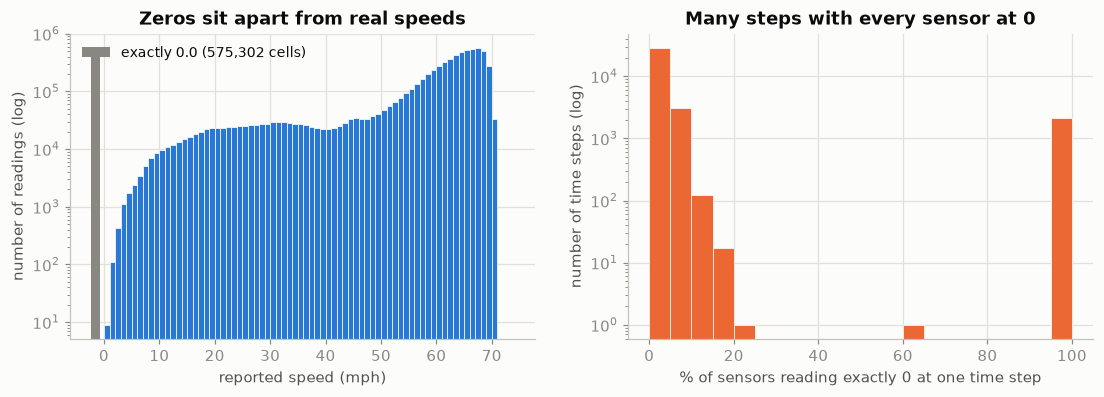

In [6]:
n_nan, n_inf, n_neg = int(np.isnan(values).sum()), int(np.isinf(values).sum()), int((values < 0).sum())
n_zero = int((values == 0).sum())
positive = values[values > 0]
print(f"NaN: {n_nan}   inf: {n_inf}   negative: {n_neg}")
print(f"exactly 0.0: {n_zero:,} cells = {n_zero / values.size:.2%} of all readings")
print(f"smallest positive reading: {positive.min():.2f} mph; readings in (0, 3) mph: {int(((values > 0) & (values < 3)).sum())}")
print(f"largest reading: {values.max():.1f} mph")

zero_share_per_step = (values == 0).mean(axis=1)
all_missing_steps = int((zero_share_per_step == 1.0).sum())
print(f"time steps where ALL {N} sensors are exactly 0: {all_missing_steps:,} ({all_missing_steps / T:.2%} of steps)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(positive, bins=np.arange(0, 75, 1), color="#2a78d6", edgecolor=viz.SURFACE, linewidth=0.5)
axes[0].bar([-1.5], [n_zero], width=1.6, color=viz.MISSING_COLOR, label=f"exactly 0.0 ({n_zero:,} cells)")
axes[0].set_yscale("log"); axes[0].set_xlabel("reported speed (mph)"); axes[0].set_ylabel("number of readings (log)")
axes[0].set_title("Zeros sit apart from real speeds"); axes[0].legend(loc="upper left")
axes[1].hist(zero_share_per_step * 100, bins=np.arange(0, 105, 5), color="#eb6834", edgecolor=viz.SURFACE, linewidth=0.5)
axes[1].set_yscale("log"); axes[1].set_xlabel("% of sensors reading exactly 0 at one time step"); axes[1].set_ylabel("number of time steps (log)")
axes[1].set_title("Many steps with every sensor at 0")
viz.save_figure(fig, "01_zero_encoding"); plt.show()

assert n_nan == 0 and n_inf == 0 and n_neg == 0
assert all_missing_steps > 0, "hypothesis check: expected network-wide all-zero time steps"

**Decision.** Zero is not a speed here: there are time steps at which all 207 sensors read exactly 0.0
simultaneously, which cannot be real congestion. We therefore treat `0.0` as **missing**, convert it to `NaN`,
and keep a boolean *observed* mask. Missing values are never used as a zero speed, in inputs, targets, scalers or
metrics. (DCRNN's reference code also masks `0` as the null value, so the convention matches the literature.)
The smallest *positive* reading is 0.33 mph; very low but non-zero speeds are kept as genuine stop-and-go traffic.

In [7]:
speed, observed = dl.to_speed_and_mask(values)
assert observed.sum() + (~observed).sum() == values.size
assert np.nanmin(speed) > 0, "no observed reading may be zero"
print(f"observed cells: {int(observed.sum()):,}   missing cells: {int((~observed).sum()):,}")

observed cells: 6,519,002   missing cells: 575,302


## 4 · Missingness and potential sensor outages

In [8]:
miss = ~observed
per_sensor = pd.Series(miss.mean(axis=0) * 100, index=sensor_ids, name="missing_%")

def run_lengths(flag: np.ndarray) -> np.ndarray:
    """Lengths of consecutive True runs in a boolean vector."""
    padded = np.r_[False, flag, False].astype(np.int8)
    edges = np.flatnonzero(np.diff(padded))
    return edges[1::2] - edges[0::2]

runs = {sid: run_lengths(miss[:, j]) for j, sid in enumerate(sensor_ids)}
longest = pd.Series({sid: (r.max() if len(r) else 0) for sid, r in runs.items()}, name="longest_missing_run_steps")
all_runs = np.concatenate([r for r in runs.values() if len(r)])

summary = pd.DataFrame({
    "overall missing %": [100 * miss.mean()],
    "per-sensor missing % (min)": [per_sensor.min()],
    "per-sensor missing % (median)": [per_sensor.median()],
    "per-sensor missing % (max)": [per_sensor.max()],
    "sensors > 50% missing": [int((per_sensor > 50).sum())],
    "all-sensor outage steps": [all_missing_steps],
}).T.rename(columns={0: "value"})
display(summary.round(3))

buckets = pd.cut(all_runs, [0, 1, 11, 287, np.inf], labels=["5 min", "10-55 min", "1 h - <1 day", ">= 1 day"])
run_table = pd.DataFrame({
    "gaps": pd.Series(buckets).value_counts().sort_index(),
    "missing cells": pd.Series(all_runs).groupby(buckets, observed=False).sum(),
})
run_table["% of all missing cells"] = 100 * run_table["missing cells"] / miss.sum()
print("Missing gaps by duration (a gap is a maximal run of consecutive missing readings at one sensor):")
display(run_table.round(2))
print("Sensors with the longest single gap (steps of 5 min):")
display(longest.sort_values(ascending=False).head(5).to_frame().assign(days=lambda d: (d.iloc[:, 0] / 288).round(1)))

,value
overall missing %,8.109
per-sensor missing % (min),6.268
per-sensor missing % (median),6.974
per-sensor missing % (max),20.104
sensors > 50% missing,0.000
all-sensor outage steps,2148.000


Missing gaps by duration (a gap is a maximal run of consecutive missing readings at one sensor):


,gaps,missing cells,% of all missing cells
5 min,7468,7468,1.30
10-55 min,11553,46319,8.05
1 h - <1 day,6661,391941,68.13
>= 1 day,281,129574,22.52


Sensors with the longest single gap (steps of 5 min):


,longest_missing_run_steps,days
717491,1683,5.8
717490,1683,5.8
769444,1330,4.6
769430,1330,4.6
769431,1330,4.6


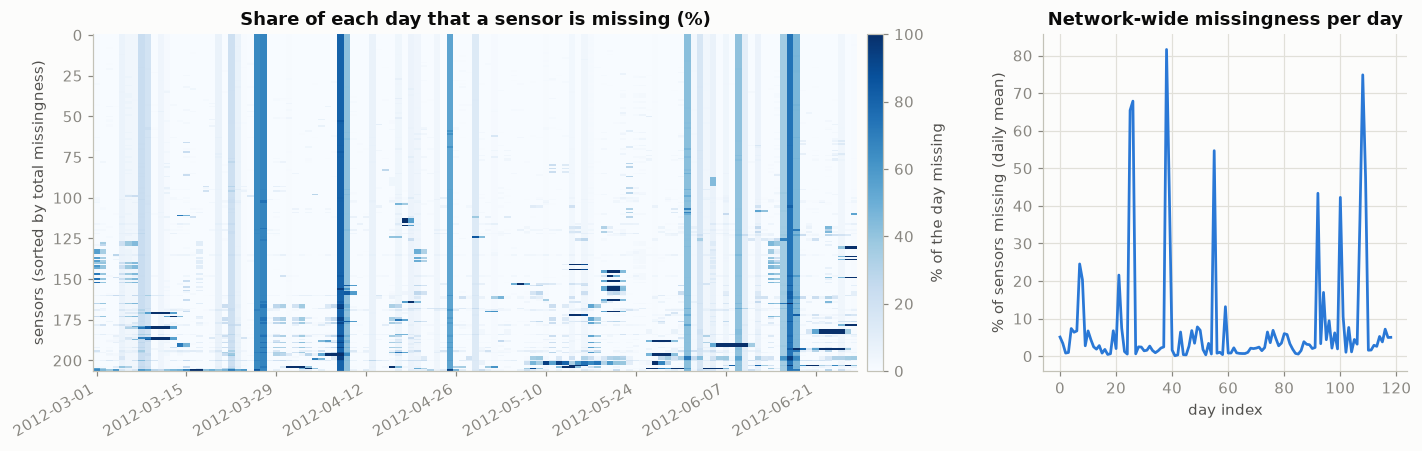

In [9]:
daily_missing = miss.reshape(int(n_days), 288, N).mean(axis=1)            # [days, sensors]
order = np.argsort(per_sensor.values)                                     # least -> most missing
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [3, 1.2]})
im = axes[0].imshow(daily_missing[:, order].T * 100, aspect="auto", cmap="Blues", vmin=0, vmax=100, interpolation="nearest")
axes[0].grid(False)
tick_days = np.arange(0, int(n_days), 14)
axes[0].set_xticks(tick_days, [str(timestamps[d * 288].date()) for d in tick_days], rotation=30, ha="right")
axes[0].set_ylabel("sensors (sorted by total missingness)"); axes[0].set_title("Share of each day that a sensor is missing (%)")
plt.colorbar(im, ax=axes[0], pad=0.01, label="% of the day missing")
axes[1].plot(miss.mean(axis=1).reshape(int(n_days), 288).mean(axis=1) * 100, color="#2a78d6")
axes[1].set_xlabel("day index"); axes[1].set_ylabel("% of sensors missing (daily mean)")
axes[1].set_title("Network-wide missingness per day")
fig.tight_layout(); viz.save_figure(fig, "01_missingness"); plt.show()

**Interpretation.** Missingness is modest for a typical sensor (about 7% of readings) but unevenly distributed in time:
the heatmap shows vertical bands (days on which a large share of all sensors is missing at once, also visible as spikes
in the right panel) and horizontal bands (individual sensors down for several consecutive days; the longest single gap
is listed above). Gaps lasting an hour or longer account for most of the missing cells, so imputing them would mean inventing
long stretches of data.
We therefore keep an observed-mask everywhere, exclude missing *targets* from every loss and metric, and never fill
inputs with future information.

## 5 · Descriptive statistics (observed readings only)

,all observed readings (mph)
count,6519002.00
mean,58.46
std,13.02
min,0.33
1%,13.12
5%,25.62
50%,63.22
95%,68.89
99%,69.75
max,70.00


Distribution across the 207 sensors of each per-sensor statistic:


,mean,std,median,cv
min,30.89,1.99,31.44,0.03
25%,55.38,6.53,60.06,0.11
50%,59.72,10.23,63.00,0.18
75%,62.85,13.43,66.22,0.24
max,67.73,23.94,69.12,0.58


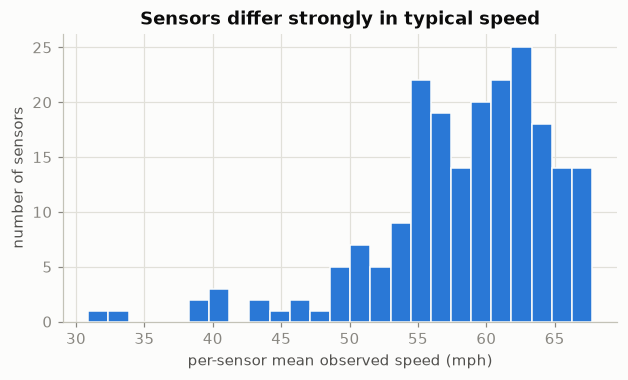

In [10]:
obs_frame = pd.DataFrame(speed, index=timestamps, columns=sensor_ids)
overall = pd.Series(speed[observed]).describe(percentiles=[.01, .05, .5, .95, .99]).rename("all observed readings (mph)")
display(overall.round(2).to_frame())
sensor_stats = obs_frame.agg(["mean", "std", "min", "median", "max", "count"]).T
sensor_stats["cv"] = sensor_stats["std"] / sensor_stats["mean"]
print("Distribution across the 207 sensors of each per-sensor statistic:")
display(sensor_stats.describe().loc[["min", "25%", "50%", "75%", "max"], ["mean", "std", "median", "cv"]].round(2))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(sensor_stats["mean"], bins=25, color="#2a78d6", edgecolor=viz.SURFACE)
ax.set_xlabel("per-sensor mean observed speed (mph)"); ax.set_ylabel("number of sensors"); ax.set_title("Sensors differ strongly in typical speed")
viz.save_figure(fig, "01_sensor_mean_hist"); plt.show()

**Interpretation.** Speeds are capped at 70 mph and the distribution is strongly left-skewed: most readings are in free flow,
a minority are congested. Sensors differ substantially in their typical speed and variability, which is why the models
receive sensor identity (XGBoost), a learned sensor embedding (ST-GAT) and per-sensor training means.

## 6 · Representative sensors

Rather than plotting 207 series, we pick four sensors by an explicit rule: the slowest, the median and the fastest sensor by
mean observed speed, plus the sensor with the highest standard deviation. `plot_sensor` lets you inspect any other id.

                       rule sensor_id
      slowest (lowest mean)    771667
        median-speed sensor    769847
     fastest (highest mean)    767455
most variable (highest std)    717462


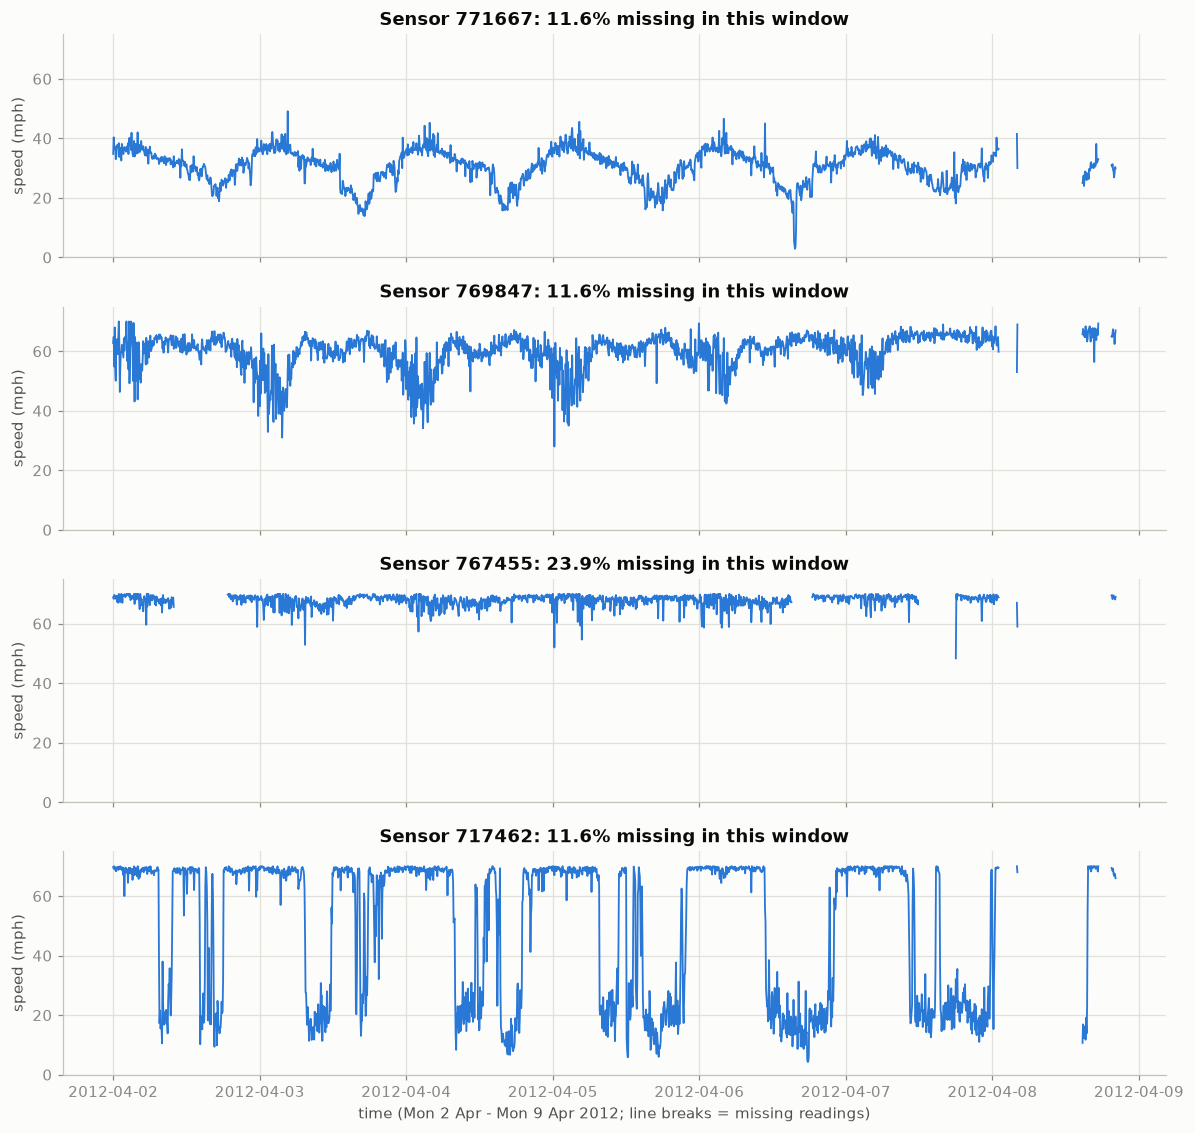

In [11]:
by_mean = sensor_stats["mean"].sort_values()
chosen = {
    "slowest (lowest mean)": by_mean.index[0],
    "median-speed sensor": by_mean.index[len(by_mean) // 2],
    "fastest (highest mean)": by_mean.index[-1],
    "most variable (highest std)": sensor_stats["std"].idxmax(),
}
REP_SENSORS = list(dict.fromkeys(chosen.values()))
print(pd.DataFrame({"rule": list(chosen), "sensor_id": list(chosen.values())}).to_string(index=False))

def plot_sensor(sensor_id, start="2012-04-02", days=7, ax=None):
    """Observed speed of one sensor over `days` days; gaps are real missing readings (line breaks)."""
    ax = ax or plt.subplots(figsize=(11, 2.8))[1]
    window = obs_frame.loc[start:pd.Timestamp(start) + pd.Timedelta(days=days), sensor_id]
    ax.plot(window.index, window.values, color="#2a78d6", lw=1.2)
    ax.set_ylim(0, 75); ax.set_ylabel("speed (mph)")
    ax.set_title(f"Sensor {sensor_id}: {window.isna().mean():.1%} missing in this window")
    return ax

fig, axes = plt.subplots(len(REP_SENSORS), 1, figsize=(11, 2.6 * len(REP_SENSORS)), sharex=True)
for ax, sid in zip(np.atleast_1d(axes), REP_SENSORS):
    plot_sensor(sid, ax=ax)
np.atleast_1d(axes)[-1].set_xlabel("time (Mon 2 Apr - Mon 9 Apr 2012; line breaks = missing readings)")
fig.tight_layout(); viz.save_figure(fig, "01_representative_sensors_week"); plt.show()

**Interpretation.** The plots show a repeating daily rhythm (high free-flow speed at night, dips during commute
periods) with sensor-specific depth and noise. Gaps appear as line breaks, i.e. they stay visible rather than becoming zeros.

## 7 · Network-wide average speed over time

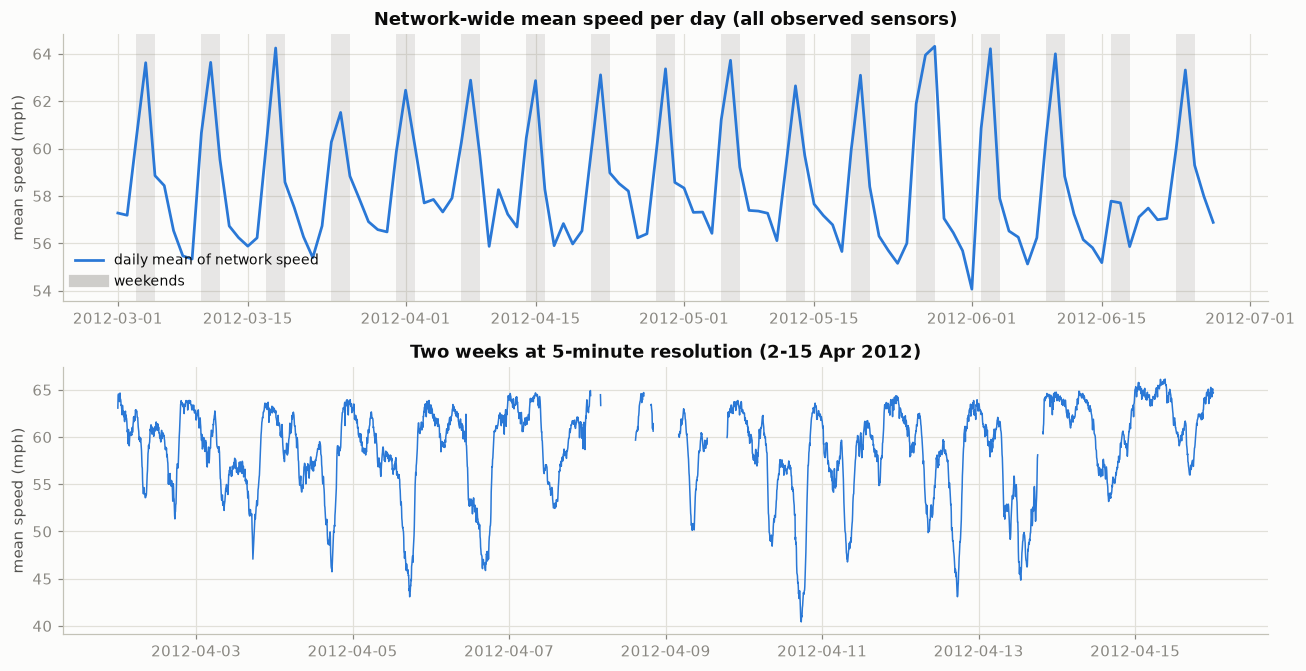

days with the lowest / highest network mean speed:
lowest network mean speed:


,mean mph,weekday
2012-06-01,54.06,Friday
2012-06-07,55.13,Thursday
2012-05-24,55.15,Thursday


highest network mean speed:


,mean mph,weekday
2012-05-28,64.31,Monday
2012-03-18,64.24,Sunday
2012-06-03,64.21,Sunday


mean of daily network speed: weekdays 57.2 mph vs weekends 61.6 mph


In [12]:
n_obs_step = observed.sum(axis=1)
network_mean = pd.Series(np.where(observed, speed, 0.0).sum(axis=1) / np.maximum(n_obs_step, 1), index=timestamps)
network_mean[n_obs_step == 0] = np.nan         # all-sensor outage steps stay undefined, not zero
daily = network_mean.resample("D").mean()
is_weekend = daily.index.dayofweek >= 5

fig, axes = plt.subplots(2, 1, figsize=(12, 6.2))
axes[0].plot(daily.index, daily.values, color="#2a78d6", label="daily mean of network speed")
for d in daily.index[is_weekend]:
    axes[0].axvspan(d, d + pd.Timedelta(days=1), color="#898781", alpha=0.18, lw=0)
axes[0].plot([], [], color="#898781", alpha=0.4, lw=8, label="weekends")
axes[0].set_ylabel("mean speed (mph)"); axes[0].set_title("Network-wide mean speed per day (all observed sensors)"); axes[0].legend(loc="lower left")
two_weeks = network_mean["2012-04-02":"2012-04-15"]
axes[1].plot(two_weeks.index, two_weeks.values, color="#2a78d6", lw=1.0)
axes[1].set_ylabel("mean speed (mph)"); axes[1].set_title("Two weeks at 5-minute resolution (2-15 Apr 2012)")
fig.tight_layout(); viz.save_figure(fig, "01_network_mean_speed"); plt.show()

print("days with the lowest / highest network mean speed:")
for label, days_ in (("lowest", daily.nsmallest(3)), ("highest", daily.nlargest(3))):
    print(f"{label} network mean speed:")
    display(days_.round(2).to_frame("mean mph").assign(weekday=days_.index.day_name()))
weekday_daily, weekend_daily = daily[~is_weekend].mean(), daily[is_weekend].mean()
print(f"mean of daily network speed: weekdays {weekday_daily:.1f} mph vs weekends {weekend_daily:.1f} mph")
assert weekday_daily < weekend_daily

**Interpretation.** The mean of the daily network speed is lower on weekdays than on weekends (asserted above). The days with
the most extreme network means are listed; the data contain no incident, weather or holiday labels, so we do not attribute them
to causes. (Outside the data: 2012-05-28 was the US Memorial Day holiday and falls in the validation period.)

## 8 · Time-of-day and day-of-week structure

Peak periods must be defined *before* models are evaluated. Here we measure the weekday profile and check that the windows
fixed in `config.PEAK_WINDOWS` correspond to the lowest-speed hours. The same profile also supports the assumption that the
naive timestamps are Los Angeles local time (commute dips at around 08:00 and 17:00).

weekday mean speed inside the configured peak windows ((7, 10), (15, 19)): 50.4 mph
weekday mean speed outside them: 60.0 mph   | weekend mean: 61.7 mph
six slowest weekday hours: [8, 9, 15, 16, 17, 18]  -> all inside the peak windows? True


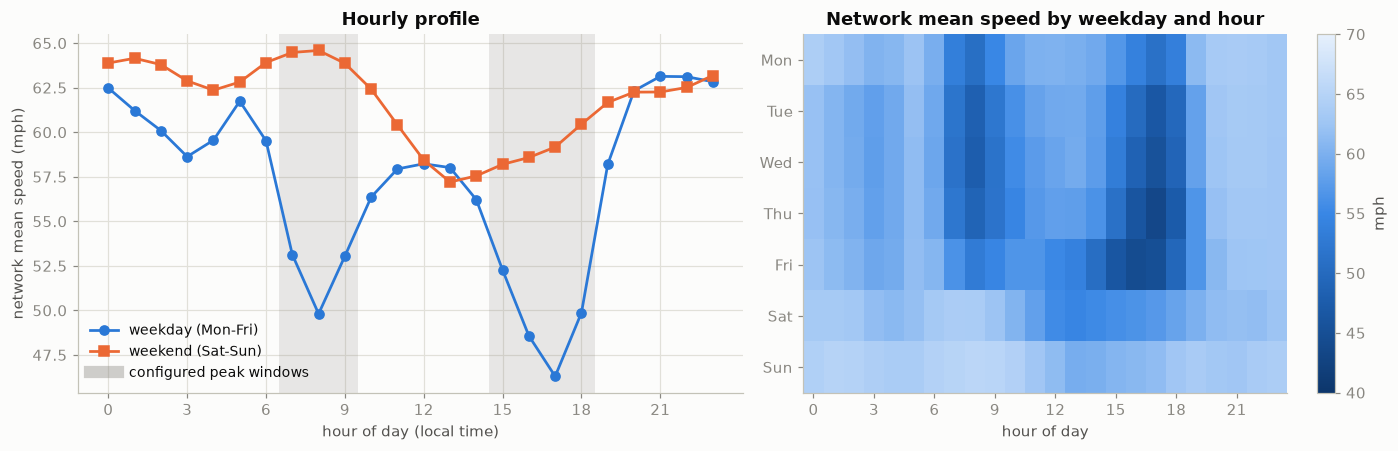

In [13]:
hour = timestamps.hour.to_numpy(); dow = timestamps.dayofweek.to_numpy()
net = network_mean.to_numpy()
weekday = dow < 5

profile = pd.DataFrame({
    "weekday": pd.Series(net[weekday]).groupby(hour[weekday]).mean(),
    "weekend": pd.Series(net[~weekday]).groupby(hour[~weekday]).mean(),
})
dow_hour = pd.DataFrame({"v": net, "dow": dow, "hour": hour}).groupby(["dow", "hour"])["v"].mean().unstack()

in_peak = np.zeros(len(hour), dtype=bool)
for start, end in config.PEAK_WINDOWS:
    in_peak |= (hour >= start) & (hour < end)
peak_mean = np.nanmean(net[weekday & in_peak]); off_mean = np.nanmean(net[weekday & ~in_peak])
weekend_mean = np.nanmean(net[~weekday])
lowest_hours = profile["weekday"].nsmallest(6).index.tolist()
print(f"weekday mean speed inside the configured peak windows {config.PEAK_WINDOWS}: {peak_mean:.1f} mph")
print(f"weekday mean speed outside them: {off_mean:.1f} mph   | weekend mean: {weekend_mean:.1f} mph")
print(f"six slowest weekday hours: {sorted(lowest_hours)}  -> all inside the peak windows? "
      f"{all(any(s <= h < e for s, e in config.PEAK_WINDOWS) for h in lowest_hours)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
axes[0].plot(profile.index, profile["weekday"], color="#2a78d6", marker="o", label="weekday (Mon-Fri)")
axes[0].plot(profile.index, profile["weekend"], color="#eb6834", marker="s", label="weekend (Sat-Sun)")
for start, end in config.PEAK_WINDOWS:
    axes[0].axvspan(start - 0.5, end - 0.5, color="#898781", alpha=0.18, lw=0)
axes[0].plot([], [], color="#898781", alpha=0.4, lw=8, label="configured peak windows")
axes[0].set_xlabel("hour of day (local time)"); axes[0].set_ylabel("network mean speed (mph)")
axes[0].set_xticks(range(0, 24, 3)); axes[0].set_title("Hourly profile"); axes[0].legend(loc="lower left")
im = axes[1].imshow(dow_hour.values, aspect="auto", cmap=viz.SPEED_CMAP, vmin=40, vmax=70)
axes[1].grid(False); axes[1].set_xticks(range(0, 24, 3)); axes[1].set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set_xlabel("hour of day"); axes[1].set_title("Network mean speed by weekday and hour")
plt.colorbar(im, ax=axes[1], label="mph")
fig.tight_layout(); viz.save_figure(fig, "01_time_of_day_patterns"); plt.show()

assert peak_mean < off_mean < weekend_mean, "the data do not support the configured peak definition"

**Interpretation (asserted in code above).** On weekdays the network is slower inside the configured peak windows than
outside them, and weekends are faster than weekday off-peak on average. The weekday profile has two pronounced dips
(morning and late afternoon) that line up with local commute hours, which also supports reading the timestamps as Pacific
local time. A smaller dip around 03:00 is visible on weekdays; this data set cannot explain it, so we make no claim about its cause.
The peak definition stays as configured: weekdays 07:00-10:00 and 15:00-19:00 (judged on the forecast *target* time).

## 9 · Representative sensors compared: weekday time-of-day profiles

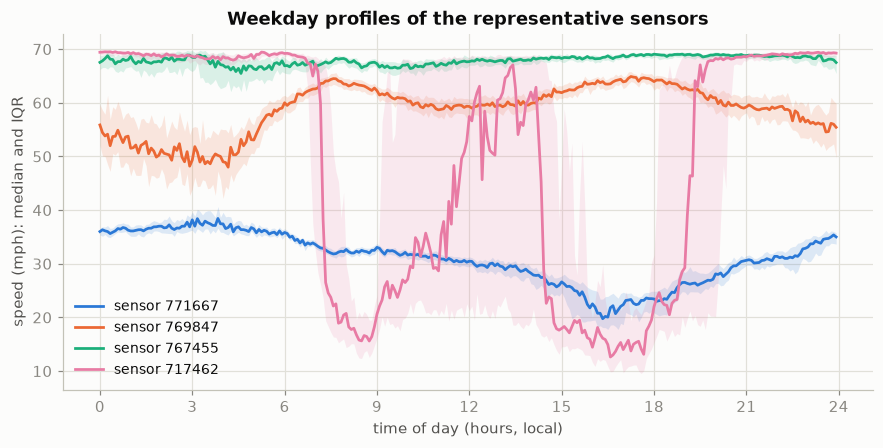

In [14]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"]
for color, sid in zip(colors, REP_SENSORS):
    s = obs_frame.loc[weekday, sid]
    tod = (s.index.hour * 60 + s.index.minute) / 60
    prof = s.groupby(tod).agg(["median", lambda x: x.quantile(.25), lambda x: x.quantile(.75)])
    prof.columns = ["median", "q25", "q75"]
    ax.plot(prof.index, prof["median"], color=color, label=f"sensor {sid}")
    ax.fill_between(prof.index, prof["q25"], prof["q75"], color=color, alpha=0.15, lw=0)
ax.set_xlabel("time of day (hours, local)"); ax.set_ylabel("speed (mph): median and IQR"); ax.set_xticks(range(0, 25, 3))
ax.set_title("Weekday profiles of the representative sensors"); ax.legend(loc="lower left")
viz.save_figure(fig, "01_representative_profiles"); plt.show()

**Interpretation.** The same commute structure appears at different depths and with different spreads for each sensor, so a
single network-wide pattern does not describe individual sensors well. Whether nearby sensors share congestion with a time lag
is not shown here; it is exactly what the later models test.

## 10 · Limitations of the dataset

* **Speed only.** METR-LA contains speed. It has no vehicle counts (flow), occupancy, incidents, weather, or holiday labels,
  so we do not model flow and make no claim about it.
* **In-band missing data.** Missing readings are encoded as `0.0`; 8% of cells (and some whole-network time steps) are missing.
  The decision to treat them as missing rests on the evidence in section 3.
* **Short, old, single-region record.** 119 days in 2012, one metropolitan area, highway loop detectors only. The train / validation /
  test periods are contiguous and cover different weeks, so seasonal effects, holidays and infrastructure changes are not controlled.
* **Sensor subset.** 207 of the roughly 4,000 sensors in the district; the graph describes only relationships among those 207.
* **Capped, aggregated measurements.** Speeds are capped at 70 mph and averaged over 5 minutes, hiding within-interval dynamics.
* **Naive timestamps.** No explicit time zone; Pacific local time is an assumption (consistent with the commute pattern above).
* **Observational data.** Low speed at a sensor does not identify an incident or its cause.

In [15]:
checks = {
    "regular 5-minute grid": list(steps.index) == [pd.Timedelta(minutes=5)],
    "207 sensors x 34,272 steps": (T, N) == (34272, 207),
    "zero used as missing sentinel (evidence: all-sensor zero steps)": all_missing_steps > 0,
    "no observed reading equals zero": bool(np.nanmin(speed) > 0),
    "peak windows supported by data": bool(peak_mean < off_mean < weekend_mean),
}
display(pd.DataFrame({"check": list(checks), "result": ["PASS" if v else "FAIL" for v in checks.values()]}))
assert all(checks.values())
print("Exploration complete. Next: 02_data_preprocessing.ipynb")

,check,result
0,regular 5-minute grid,PASS
1,"207 sensors x 34,272 steps",PASS
2,zero used as missing sentinel (evidence: all-s...,PASS
3,no observed reading equals zero,PASS
4,peak windows supported by data,PASS


Exploration complete. Next: 02_data_preprocessing.ipynb


---
---
# Section: `02_data_preprocessing`

# 02 · Preprocessing and forecasting samples

**Objective.** Turn the raw METR-LA matrix into leakage-free, reproducible forecasting samples that **every** model shares:
one chronological split, one training-only scaler, one missing-data policy, one window definition.

**Methodology.**
1. Interpret zeros as missing (`speed` with NaN + boolean `observed` mask).
2. Split **chronologically** at exact timestamps (70 / 10 / 20 %, snapped to midnight so each split holds whole days).
3. Preserve missingness information; decide per model family how it enters the model.
4. Fit the scaler on **training timestamps only**.
5. Calendar features and causal (past-only) helper arrays.
6. Generate windows: 12 past steps (60 min) -> targets at steps 1, 3, 6, 12 (5, 15, 30, 60 min); assert no leakage.
7. Save the processed artifacts that notebooks 03-08 reload.

All reusable logic is in `src/preprocessing.py`, `src/feature_engineering.py`; the unit tests are in `tests/test_splits.py`.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, preprocessing as pp, feature_engineering as fe, visualization as viz

viz.apply_style()
dl.require_raw_files()

## 1 · Load the raw data and interpret missing readings

As established in notebook 01, `0.0` marks a missing reading. `to_speed_and_mask` converts it to `NaN` and records an
`observed` mask; negative values would raise an error. After this step **no array contains a zero speed**.

In [3]:
raw = dl.load_metr_la_h5()
speed, observed = dl.to_speed_and_mask(raw.values)
timestamps, sensor_ids = raw.timestamps, raw.sensor_ids
T, N = speed.shape
print(f"speed: {speed.shape} {speed.dtype} | observed mask: {observed.shape} {observed.dtype}")
print(f"missing share: {(~observed).mean():.2%}")
assert np.array_equal(np.isnan(speed), ~observed) and np.nanmin(speed) > 0

speed: (34272, 207) float32 | observed mask: (34272, 207) bool
missing share: 8.11%


## 2 · Chronological split with exact timestamp boundaries

* Boundaries are placed at the nearest **midnight** to the 70 % / 80 % marks, so each split contains complete days.
* No shuffling anywhere: train < validation < test in time.
* **Context rule.** A sample belongs to the split containing *all its targets*. Its 60-minute *input* window may reach
  back into the preceding split (that is legitimate past information at prediction time), but never forward.
  Consequently, training windows never see validation/test rows at all, and the first test forecasts use validation rows
  only as input history.

In [4]:
splits = pp.make_chronological_splits(timestamps)
rows = []
for name in pp.SPLIT_NAMES:
    a, b = splits.range(name)
    rows.append({"split": name, "start_idx": a, "end_idx (excl.)": b, "steps": b - a, "days": (b - a) / 288,
                 "share": (b - a) / T, "first timestamp": splits.first_timestamp[name], "last timestamp": splits.last_timestamp[name],
                 "weekdays covered": int(timestamps[a:b].dayofweek.nunique())})
split_table = pd.DataFrame(rows).set_index("split")
display(split_table)

# integrity assertions
assert splits.train[0] == 0 and splits.train[1] == splits.val[0] and splits.val[1] == splits.test[0] and splits.test[1] == T
assert pd.Timestamp(splits.last_timestamp["train"]) < pd.Timestamp(splits.first_timestamp["val"])
assert pd.Timestamp(splits.last_timestamp["val"]) < pd.Timestamp(splits.first_timestamp["test"])
assert all(timestamps[e].hour == 0 and timestamps[e].minute == 0 for e in (splits.train[1], splits.val[1]))
splits.to_json()
print("saved", config.SPLITS_JSON.relative_to(config.PROJECT_ROOT))

,start_idx,end_idx (excl.),steps,days,share,first timestamp,last timestamp,weekdays covered
split,,,,,,,,
train,0,23904,23904,83.0,0.697479,2012-03-01 00:00:00,2012-05-22 23:55:00,7
val,23904,27360,3456,12.0,0.100840,2012-05-23 00:00:00,2012-06-03 23:55:00,7
test,27360,34272,6912,24.0,0.201681,2012-06-04 00:00:00,2012-06-27 23:55:00,7


saved data/processed/splits.json


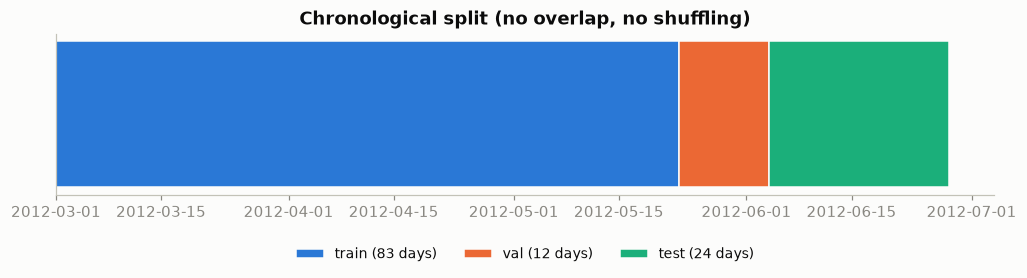

In [5]:
fig, ax = plt.subplots(figsize=(11, 1.9))
colors = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
for name in pp.SPLIT_NAMES:
    a, b = splits.range(name)
    ax.barh(0, timestamps[b - 1] - timestamps[a], left=timestamps[a], color=colors[name], edgecolor=viz.SURFACE, height=0.5, label=f"{name} ({(b - a) / 288:.0f} days)")
ax.set_yticks([]); ax.set_title("Chronological split (no overlap, no shuffling)"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25))
ax.grid(False); viz.save_figure(fig, "02_split_timeline"); plt.show()

**Interpretation.** The three periods are contiguous and disjoint; the last 24 days (the test period) are never touched during
fitting, scaling, early stopping or hyper-parameter selection. All models use these identical boundaries.
Because the periods are different calendar weeks, the test period may differ in conditions from the training period
(see the limitations in notebook 01).

## 3 · Missing values

| Where | Policy |
|---|---|
| **Targets** | A missing target is never predicted-against: it is excluded from every loss and metric (`observed` mask). |
| **Persistence / rolling mean** | Use the latest / mean of **observed** readings in the 60-minute window; if the whole window is missing, fall back to the sensor's *training* mean (never zero). |
| **XGBoost features** | Lags stay `NaN` (XGBoost learns a default direction for missing values); no imputation. |
| **ST-GAT inputs** | Value channel = scaled speed, `0` (= the training mean in scaled space) where missing, **plus** an explicit observed-mask channel. No value is copied from a neighbour or from the future. |
| **Anchor** | `last observed speed in the window` (causal last-observation-carried-forward limited to the window) with the training-mean fallback; used by persistence and as the residual base of both learned models. |

In [6]:
miss_summary = pp.missingness_summary(observed, splits)
display(miss_summary.round(3))
assert (miss_summary["missing_cells"].sum() == (~observed).sum())
ratio = miss_summary.loc["test", "missing_pct"] / miss_summary.loc["train", "missing_pct"]
print(f"missing share, test vs train: {miss_summary.loc['test', 'missing_pct']:.1f}% vs {miss_summary.loc['train', 'missing_pct']:.1f}% (x{ratio:.2f})")

,timesteps,cells,missing_cells,missing_pct,network_wide_outage_steps
split,,,,,
train,23904,4948128,354097,7.156,1301
val,3456,715392,49275,6.888,181
test,6912,1430784,171930,12.016,666


missing share, test vs train: 12.0% vs 7.2% (x1.68)


**Interpretation / caveat.** Missingness is **not** uniform across the splits: the test period contains noticeably more missing
data (and more network-wide outage steps) than the training period (printed above). Missing *targets* are simply excluded from
all metrics, so scores remain comparable between models, but test *inputs* are also more often incomplete. The anchor-fallback
rate in section 6 shows the same shift. This is a property of the data, not something we correct; it is reported again in the
final results.

## 4 · Scaling fitted on training timestamps only

A global z-score (`mean`, `std` of the **observed training** speeds) plus a per-sensor training mean (the fallback anchor).
The same fitted object transforms validation and test; nothing is ever refitted. To *demonstrate* the absence of leakage, we
wreck the validation/test rows and verify the fitted statistics do not change.

In [7]:
scaler = pp.SpeedScaler.fit(speed, observed, splits.train)
print(f"fit range (train)  : rows {scaler.fit_range}")
print(f"global mean / std  : {scaler.mean:.3f} / {scaler.std:.3f} mph")
print(f"per-sensor training mean: min {scaler.sensor_mean.min():.1f}  median {np.median(scaler.sensor_mean):.1f}  max {scaler.sensor_mean.max():.1f} mph")

# leakage test: destroy everything after the training period, refit, compare
tampered = speed.copy(); tampered[splits.val[0]:] = 12345.0
check = pp.SpeedScaler.fit(tampered, observed, splits.train)
assert check.mean == scaler.mean and check.std == scaler.std and np.array_equal(check.sensor_mean, scaler.sensor_mean)

# scaled statistics per split (only the training split is exactly standardised)
rows = []
for name in pp.SPLIT_NAMES:
    a, b = splits.range(name)
    z = scaler.transform(speed[a:b][observed[a:b]])
    rows.append({"split": name, "mean of scaled": z.mean(), "std of scaled": z.std()})
display(pd.DataFrame(rows).set_index("split").round(3))
assert abs(rows[0]["mean of scaled"]) < 1e-3 and abs(rows[0]["std of scaled"] - 1) < 1e-3
lo, hi = config.SPEED_BOUNDS_MPH
a, b = splits.train
assert np.nanmin(speed[a:b]) > lo and np.nanmax(speed[a:b]) <= hi, "training speeds fall outside the clipping range"
print(f"training speeds lie in ({np.nanmin(speed[a:b]):.2f}, {np.nanmax(speed[a:b]):.2f}] mph -> predictions are clipped to {config.SPEED_BOUNDS_MPH} when scored")

scaler.to_json()
print("saved", config.SCALER_JSON.relative_to(config.PROJECT_ROOT))

fit range (train)  : rows (0, 23904)
global mean / std  : 58.579 / 12.837 mph
per-sensor training mean: min 30.9  median 59.8  max 67.8 mph


,mean of scaled,std of scaled
split,,
train,-0.000,1.000
val,0.023,1.025
test,-0.060,1.059


training speeds lie in (0.33, 70.00] mph -> predictions are clipped to (0.0, 70.0) when scored
saved data/processed/scaler.json


**Interpretation.** The scaler is unaffected by what happens after the training period, as required. Validation and test are
transformed with the *training* statistics, so their scaled mean/std deviate from (0, 1); that deviation is expected and
is exactly what an honest deployment would experience.

## 5 · Temporal features

Calendar information about a timestamp is legitimately available in advance (we know what time and weekday it will be).
We create `sin/cos` of the minute-of-day and of the weekday (cyclical, so 23:55 is close to 00:00 and Sunday to Monday).
The tabular model additionally gets the calendar features of the **forecast target time**.

In [8]:
cal = pp.calendar_arrays(timestamps)
time_feats = pp.time_feature_matrix(timestamps)
display(pd.DataFrame({"timestamp": timestamps[[0, 100, 288 * 4 + 150]], "minute_of_day": cal["minute_of_day"][[0, 100, 288 * 4 + 150]],
                      "dow (Mon=0)": cal["dow"][[0, 100, 288 * 4 + 150]],
                      **{k: cal[k][[0, 100, 288 * 4 + 150]].round(3) for k in ("tod_sin", "tod_cos", "dow_sin", "dow_cos")}}))
assert time_feats.shape == (T, 4) and np.abs(time_feats).max() <= 1 + 1e-6
assert np.allclose(time_feats[0, :2], time_feats[288, :2])        # same time of day, one day later

,timestamp,minute_of_day,dow (Mon=0),tod_sin,tod_cos,dow_sin,dow_cos
0,2012-03-01 00:00:00,0.0,3,0.000,1.000,0.434,-0.901
1,2012-03-01 08:20:00,500.0,3,0.819,-0.574,0.434,-0.901
2,2012-03-05 12:30:00,750.0,0,-0.131,-0.991,0.000,1.000


## 6 · Causal helper arrays: last observation, age, and the anchor

`locf_with_age` carries the last observed value forward using **only the current and earlier rows**. From it we derive the
*anchor* of each sample (the most recent observed speed inside the 12-step input window, otherwise the sensor's training
mean). We verify causality by changing the future and checking that nothing earlier moves.

In [9]:
locf_value, locf_age = pp.locf_with_age(speed, observed)

future_wrecked = speed.copy(); future_wrecked[20000:] = 999.0
v2, a2 = pp.locf_with_age(future_wrecked, observed)
assert np.array_equal(np.nan_to_num(locf_value[:20000], nan=-1), np.nan_to_num(v2[:20000], nan=-1))
assert np.array_equal(locf_age[:20000], a2[:20000])
print("LOCF is causal: rows < 20000 are unchanged when rows >= 20000 are altered")

rows = []
for name in pp.SPLIT_NAMES:
    o = pp.valid_origins(splits.range(name), config.INPUT_LEN, config.MAX_HORIZON, T, name)
    _, used_fallback = pp.window_anchor(locf_value, locf_age, o, config.INPUT_LEN, scaler.sensor_mean)
    rows.append({"split": name, "origins": len(o), "anchor fell back to training mean": f"{used_fallback.mean():.2%}"})
display(pd.DataFrame(rows).set_index("split"))

LOCF is causal: rows < 20000 are unchanged when rows >= 20000 are altered


,origins,anchor fell back to training mean
split,,
train,23881,5.50%
val,3445,4.84%
test,6901,9.58%


## 7 · Window generation, shapes and leakage assertions

For an origin `t`: inputs are rows `t-11 ... t` and targets are rows `t+1 ... t+12`; models are evaluated at steps
`1, 3, 6, 12`. Origins are generated so that **all 12 target steps** lie in the sample's split.

In [10]:
L, H = config.INPUT_LEN, config.MAX_HORIZON
origins = {}
for name in pp.SPLIT_NAMES:
    origins[name] = pp.valid_origins(splits.range(name), L, H, T, name)
    pp.assert_no_leakage(origins[name], splits.range(name), L, H, T)       # raises on any violation

rows = []
for name in pp.SPLIT_NAMES:
    o = origins[name]; x_idx, y_idx = pp.window_index_arrays(o, L, H)
    rows.append({"split": name, "samples": len(o),
                 "first input row": int(x_idx.min()), "last input row": int(x_idx.max()),
                 "first target row": int(y_idx.min()), "last target row": int(y_idx.max()),
                 "split rows": str(splits.range(name))})
display(pd.DataFrame(rows).set_index("split"))

# train windows must never contain a validation or test row (neither as input nor as target)
x_tr, y_tr = pp.window_index_arrays(origins["train"], L, H)
assert x_tr.max() < splits.val[0] and y_tr.max() < splits.val[0]
# test windows may read validation rows as past context only
x_te, y_te = pp.window_index_arrays(origins["test"], L, H)
assert x_te.min() < splits.test[0] <= y_te.min()
print("temporal ordering verified: inputs <= origin < targets, targets inside their own split")

,samples,first input row,last input row,first target row,last target row,split rows
split,,,,,,
train,23881,0,23891,12,23903,"(0, 23904)"
val,3445,23892,27347,23904,27359,"(23904, 27360)"
test,6901,27348,34259,27360,34271,"(27360, 34272)"


temporal ordering verified: inputs <= origin < targets, targets inside their own split


In [11]:
# Tensor shapes for the graph model and the targets, on a small batch of test origins
batch = origins["test"][:8]
scaled_filled = pp.fill_for_model(speed, observed, scaler)
X = pp.gather_model_inputs(scaled_filled, observed, time_feats, batch, L)
Y, Y_obs = pp.gather_targets(speed, observed, batch, tuple(range(1, H + 1)))
Y_eval, Y_eval_obs = pp.gather_targets(speed, observed, batch, config.HORIZONS)
print(f"X (inputs)          : {X.shape}   = [batch, {L} steps, {N} sensors, 6 features]")
print("   channels         : 0 scaled speed (0 where missing) | 1 observed mask | 2-5 sin/cos time of day, sin/cos weekday")
print(f"Y (all 12 steps)    : {Y.shape}   = [batch, {H}, {N}] mph with NaN where missing; observed mask {Y_obs.shape}")
print(f"Y at {config.HORIZONS}  : {Y_eval.shape}  -> the evaluation targets (minutes {tuple(config.HORIZON_MINUTES[h] for h in config.HORIZONS)})")
assert X.shape == (8, L, N, 6) and Y.shape == (8, H, N)
assert np.array_equal(X[..., 1].astype(bool), observed[pp.window_index_arrays(batch, L, 1)[0]])   # mask channel == observed
assert np.isfinite(X).all()                     # model inputs never contain NaN
assert np.array_equal(Y_eval_obs, Y_obs[:, [h - 1 for h in config.HORIZONS]])

# leakage test: destroy all rows after the last origin of this batch; the inputs must not change
wrecked = scaled_filled.copy(); wrecked[batch.max() + 1:] = 1e6
X2 = pp.gather_model_inputs(wrecked, observed, time_feats, batch, L)
assert np.array_equal(X, X2)
print("inputs do not depend on any row after the origin")

X (inputs)          : (8, 12, 207, 6)   = [batch, 12 steps, 207 sensors, 6 features]
   channels         : 0 scaled speed (0 where missing) | 1 observed mask | 2-5 sin/cos time of day, sin/cos weekday
Y (all 12 steps)    : (8, 12, 207)   = [batch, 12, 207] mph with NaN where missing; observed mask (8, 12, 207)
Y at (1, 3, 6, 12)  : (8, 4, 207)  -> the evaluation targets (minutes (5, 15, 30, 60))
inputs do not depend on any row after the origin


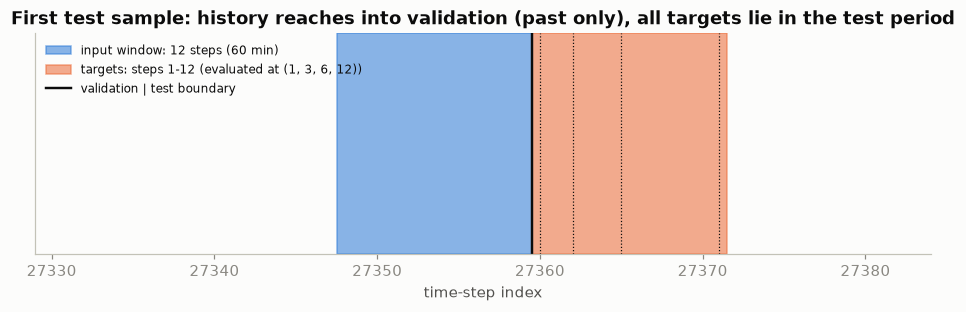

In [12]:
fig, ax = plt.subplots(figsize=(10.5, 2.6))
o = int(origins["test"][0])
ax.axvspan(o - L + 1 - 0.5, o + 0.5, color="#2a78d6", alpha=0.55, label=f"input window: {L} steps (60 min)")
ax.axvspan(o + 0.5, o + H + 0.5, color="#eb6834", alpha=0.55, label=f"targets: steps 1-{H} (evaluated at {config.HORIZONS})")
for h in config.HORIZONS:
    ax.axvline(o + h, color=viz.INK, lw=0.8, ls=":")
ax.axvline(splits.test[0] - 0.5, color=viz.INK, lw=1.6, label="validation | test boundary")
ax.set_xlim(o - 30, o + 25); ax.set_yticks([]); ax.set_xlabel("time-step index"); ax.grid(False)
ax.set_title("First test sample: history reaches into validation (past only), all targets lie in the test period")
ax.legend(loc="upper left", fontsize=8, ncol=1); viz.save_figure(fig, "02_window_diagram"); plt.show()

**Interpretation.** Window generation is verified numerically, not only drawn: inputs end at the origin, targets start one
step after it, train windows are fully inside the training period, and the first test origin is the last row of validation,
whose forecasts all fall in the test period. The graph model's input tensor has the shape `[batch, 12, 207, 6]`.

## 8 · Tabular features for the per-sensor model (XGBoost)

One row per *(origin, sensor)*: 12 lags, rolling means (3, 6, 12 steps) and standard deviations (6, 12), a short-term trend,
the last observed speed and its age, calendar features of the **target** time, and static sensor descriptors
(`sensor_id`, latitude, longitude, training mean). All rolling features use only readings up to the origin, and **no feature uses
another sensor** (that would give the "independent" baseline spatial information).

In [13]:
loc = dl.load_sensor_locations().set_index("sensor_id").loc[sensor_ids]
demo = origins["test"][::1000]
base, base_names = fe.build_base_features(speed, locf_value, locf_age, scaler.sensor_mean, demo,
                                          loc["latitude"].to_numpy(), loc["longitude"].to_numpy())
hz, hz_names = fe.horizon_features(timestamps, demo, 6, N)
frame = fe.to_frame(base, base_names, hz, hz_names, N)
print(f"feature matrix for {len(demo)} origins: {frame.shape}  (= {len(demo)} x {N} rows, {frame.shape[1]} columns)")
print("columns:", list(frame.columns))
print(f"share of NaN per column (lags are NaN where the reading is missing): ")
display(frame.isna().mean().round(3).loc[["lag_0", "lag_11", "roll_mean_12", "roll_std_6", "last_observed", "target_tod_sin"]].to_frame("NaN share"))

# leakage test: wreck every row after the last origin of this demo set
wr = speed.copy(); wr[demo.max() + 1:] = 555.0
lv, la = pp.locf_with_age(wr, ~np.isnan(wr))
base2, _ = fe.build_base_features(wr, lv, la, scaler.sensor_mean, demo, loc["latitude"].to_numpy(), loc["longitude"].to_numpy())
assert np.array_equal(np.nan_to_num(base, nan=-1), np.nan_to_num(base2, nan=-1))
print("features do not depend on any row after the origin")

feature matrix for 7 origins: (1449, 30)  (= 7 x 207 rows, 30 columns)
columns: ['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'roll_mean_3', 'roll_mean_6', 'roll_mean_12', 'roll_std_6', 'roll_std_12', 'n_observed_window', 'trend_3', 'last_observed', 'age_last_observed', 'sensor_train_mean', 'latitude', 'longitude', 'target_tod_sin', 'target_tod_cos', 'target_dow_sin', 'target_dow_cos', 'target_is_weekend', 'sensor_id']
share of NaN per column (lags are NaN where the reading is missing): 


,NaN share
lag_0,0.160
lag_11,0.161
roll_mean_12,0.014
roll_std_6,0.017
last_observed,0.000
target_tod_sin,0.000


features do not depend on any row after the origin


## 9 · Save the processed data

`traffic_clean.npz` (speed with NaN, observed mask, timestamps, canonical sensor order) is what every later notebook loads,
together with `splits.json` and `scaler.json`. Windows themselves are not stored: they are cheap index operations
(`window_index_arrays`) and storing 207 x 12 x 24k floats would waste gigabytes.

In [14]:
clean = dl.CleanTraffic(speed=speed, mask=observed, timestamps=timestamps, sensor_ids=sensor_ids)
dl.save_clean_traffic(clean)

# round-trip check through the same loader the next notebooks use
ctx = pp.load_context()
assert np.array_equal(np.nan_to_num(ctx.speed, nan=-1), np.nan_to_num(speed, nan=-1)) and np.array_equal(ctx.mask, observed)
assert ctx.sensor_ids == sensor_ids and (ctx.timestamps == timestamps).all()
assert all(np.array_equal(ctx.origins[k], origins[k]) for k in pp.SPLIT_NAMES)

size_mb = config.TRAFFIC_CLEAN_NPZ.stat().st_size / 1e6
print(f"saved {config.TRAFFIC_CLEAN_NPZ.relative_to(config.PROJECT_ROOT)} ({size_mb:.1f} MB), splits.json, scaler.json")
display(pd.DataFrame({
    "split": list(pp.SPLIT_NAMES),
    "samples (origins)": [len(origins[k]) for k in pp.SPLIT_NAMES],
    "GAT input X": [f"[{len(origins[k])}, {L}, {N}, 6]" for k in pp.SPLIT_NAMES],
    "targets Y (12 steps)": [f"[{len(origins[k])}, {H}, {N}]" for k in pp.SPLIT_NAMES],
    "XGBoost rows per horizon": [f"{len(origins[k]) * N:,}" for k in pp.SPLIT_NAMES],
}).set_index("split"))
print("\nPreprocessing complete. Next: 03_graph_construction.ipynb")

saved data/processed/traffic_clean.npz (11.2 MB), splits.json, scaler.json


,samples (origins),GAT input X,targets Y (12 steps),XGBoost rows per horizon
split,,,,
train,23881,"[23881, 12, 207, 6]","[23881, 12, 207]","4,943,367"
val,3445,"[3445, 12, 207, 6]","[3445, 12, 207]","713,115"
test,6901,"[6901, 12, 207, 6]","[6901, 12, 207]","1,428,507"



Preprocessing complete. Next: 03_graph_construction.ipynb


---
---
# Section: `03_graph_construction`

# 03 · Road-graph construction

**Objective.** Build, validate and save the sensor graph that the graph model will use, and keep one **canonical sensor order**
that every other array in the project must obey.

**Four different things that must not be confused**

| Concept | Source | What it tells us |
|---|---|---|
| Geographic **coordinates** | `graph_sensor_locations.csv` | where a sensor is on the map; *not* whether sensors are connected |
| Road-network **distance** | `distances_la_2012.csv` | pre-computed **directed** driving distance (metres) from sensor *i* to sensor *j* |
| Binary **connectivity** | derived: `A[i, j] > 0` | a directed edge *i -> j* |
| Weighted **adjacency** | derived from distance | `A = exp(-(d/sigma)^2)`, zero below 0.1 (DCRNN's thresholded Gaussian kernel) |

**Methodology.**
1. Inspect the three graph files (real schemas, no assumptions).
2. Align sensors **by id** with the traffic data and report every discrepancy.
3. Build the adjacency with DCRNN's construction and validate it (shape, diagonal, weights, edges, isolation, symmetry, connectivity).
4. Show that geographic proximity is not road connectivity.
5. Visualise; save the validated graph and a fingerprint of the sensor order.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, visualization as viz

viz.apply_style()
dl.require_raw_files()
clean = dl.load_clean_traffic()          # written by notebook 02
traffic_ids = clean.sensor_ids
print(f"canonical traffic sensors: {len(traffic_ids)}   first ids: {traffic_ids[:4]}")

canonical traffic sensors: 207   first ids: ['773869', '767541', '767542', '717447']


## 1 · Inspect the graph metadata files

In [3]:
locations = dl.load_sensor_locations()
graph_ids = dl.load_sensor_ids_txt()
distances = dl.load_distance_table()

print("graph_sensor_locations.csv:", locations.shape, "| columns:", list(locations.columns), "| dtypes:", dict(locations.dtypes.astype(str)))
display(locations.head(3))
print(f"  latitude  range: {locations.latitude.min():.4f} .. {locations.latitude.max():.4f}")
print(f"  longitude range: {locations.longitude.min():.4f} .. {locations.longitude.max():.4f}")
print(f"\ngraph_sensor_ids.txt: {len(graph_ids)} comma-separated ids, e.g. {graph_ids[:4]}")
print(f"\ndistances_la_2012.csv: {distances.shape} | columns {list(distances.columns)}")
display(distances.head(3))
all_ids_in_distance_file = set(distances['from']) | set(distances['to'])
print(f"  the file covers {len(all_ids_in_distance_file):,} distinct sensors (all LA sensors, not just our {len(traffic_ids)})")
print(f"  distance units: metres (cost). min {distances.cost.min():.0f}  median {distances.cost.median():.0f}  max {distances.cost.max():.0f}")
print(f"  self-pairs (from == to, cost 0): {(distances['from'] == distances['to']).sum():,} | duplicated (from,to) pairs: {distances.duplicated(['from', 'to']).sum()}")
in_subset = distances['from'].isin(traffic_ids) & distances['to'].isin(traffic_ids)
print(f"  rows with both endpoints among our sensors: {in_subset.sum():,} of {len(distances):,}")

graph_sensor_locations.csv: (207, 4) | columns: ['index', 'sensor_id', 'latitude', 'longitude'] | dtypes: {'index': 'int64', 'sensor_id': 'str', 'latitude': 'float64', 'longitude': 'float64'}


,index,sensor_id,latitude,longitude
0,0,773869,34.15497,-118.31829
1,1,767541,34.11621,-118.23799
2,2,767542,34.11641,-118.23819


  latitude  range: 34.0430 .. 34.2216
  longitude range: -118.5368 .. -118.1829

graph_sensor_ids.txt: 207 comma-separated ids, e.g. ['773869', '767541', '767542', '717447']

distances_la_2012.csv: (295374, 3) | columns ['from', 'to', 'cost']


,from,to,cost
0,1201054,1201054,0.0
1,1201054,1201066,2610.9
2,1201054,1201076,2822.7


  the file covers 4,106 distinct sensors (all LA sensors, not just our 207)
  distance units: metres (cost). min 0  median 7730  max 21255
  self-pairs (from == to, cost 0): 4,106 | duplicated (from,to) pairs: 0


  rows with both endpoints among our sensors: 11,753 of 295,374


**How DCRNN builds the adjacency** (read from `scripts/gen_adj_mx.py` in the original repository, which is not vendored here):

1. Create an `N x N` float32 matrix filled with `inf`; map each sensor id to its index in `graph_sensor_ids.txt`.
2. For each row `(from, to, cost)` whose two ids are in the sensor list, set `dist[from, to] = cost` (**one direction only; the
   symmetrisation line is commented out**, so the graph is directed).
3. `sigma` = standard deviation of all *finite* entries of `dist`.
4. `A = exp(-(dist / sigma)^2)`; entries below `normalized_k = 0.1` are set to 0.

We reproduce exactly that in `graph_utils.build_adjacency_from_distances`. We deliberately do **not** unpickle the shipped
`adj_mx.pkl` (pickle files can execute code); rebuilding from the CSV is transparent and testable.

## 2 · Sensor alignment (by id, never by row position)

The canonical order is the column order of the traffic file. `validate_sensor_alignment` matches locations to traffic sensors
*by id*, reports sensors without a location and ids unknown to the traffic data, and raises on duplicates or on any traffic
sensor missing from the graph id list.

In [4]:
ordered_locations, report = gu.validate_sensor_alignment(traffic_ids, locations, graph_ids)
display(pd.Series({k: (v if not isinstance(v, list) else (len(v) if v else 0)) for k, v in report.items()}, name="value").to_frame())
print("traffic sensors without a location record:", report["traffic_without_location"])
print("location records without traffic data     :", report["location_without_traffic"])
print("graph ids not in traffic / traffic ids not in graph:", report["graph_not_in_traffic"], "/", report["traffic_not_in_graph"])
print("duplicate ids (traffic / locations / graph):", report["duplicate_traffic_ids"], report["duplicate_location_ids"], report["duplicate_graph_ids"])

assert list(ordered_locations["sensor_id"]) == traffic_ids                   # node k <-> traffic column k
assert {"node", "sensor_id", "latitude", "longitude"} <= set(ordered_locations.columns) and ordered_locations["node"].is_monotonic_increasing
SENSOR_HASH = gu.sensor_order_hash(traffic_ids)
print("sensor-order fingerprint:", SENSOR_HASH)
display(ordered_locations.head(3))

,value
n_traffic,207
n_locations,207
n_graph_ids,207
duplicate_traffic_ids,0
duplicate_location_ids,0
duplicate_graph_ids,0
traffic_without_location,0
location_without_traffic,0
traffic_not_in_graph,0
graph_not_in_traffic,0


traffic sensors without a location record: []
location records without traffic data     : []
graph ids not in traffic / traffic ids not in graph: [] / []
duplicate ids (traffic / locations / graph): [] [] []
sensor-order fingerprint: 2a38ef551082d02d


,node,sensor_id,index,latitude,longitude
0,0,773869,0,34.15497,-118.31829
1,1,767541,1,34.11621,-118.23799
2,2,767542,2,34.11641,-118.23819


**Interpretation.** All 207 sensors in the traffic file have exactly one location record, the graph id list is the same set in
the same order, and there are no duplicates or unknown ids. Here the location file happens to be in the same row order as the
traffic file, but the code does not rely on that: it matched by id, so a reordered file would be handled correctly (this is
covered by `tests/test_graph.py`).

## 3 · Adjacency construction and validation

In [5]:
adj, road_dist, build_report = gu.build_adjacency_from_distances(distances, traffic_ids, normalized_k=config.GRAPH_NORMALIZED_K)
print(pd.Series(gu.report_to_dict(build_report), name="value").to_frame().to_string())
stats = gu.graph_stats(adj)
scalar_stats = {k: v for k, v in stats.items() if k not in ("in_degree", "out_degree", "isolated_nodes")}
display(pd.Series(scalar_stats, name="value").to_frame())
print("isolated nodes (no edge in or out, ignoring self-loop):", stats["isolated_nodes"], [traffic_ids[i] for i in stats["isolated_nodes"]])

                                       value
n_nodes                           207.000000
n_distance_rows                295374.000000
n_rows_used                     11753.000000
n_rows_skipped_unknown_sensor  283621.000000
n_duplicate_pairs                   0.000000
n_finite_pairs                  11753.000000
sigma_m                          2584.450195
normalized_k                        0.100000


,value
n_nodes,207
shape,"(207, 207)"
n_nonzero_total,1722
n_self_loops,207
n_edges_directed,1515
edge_density,0.035528
weight_min,0.100084
weight_max,0.999832
weight_mean,0.401044
n_reciprocal_edges,404


isolated nodes (no edge in or out, ignoring self-loop): [26] ['717804']


In [6]:
# --- validation checks (each one is asserted) --------------------------------------------------
N = len(traffic_ids)
assert adj.shape == (N, N), "adjacency must be N x N in canonical sensor order"
assert adj.dtype == np.float32 and np.isfinite(adj).all()
assert stats["n_self_loops"] == N and np.all(np.diag(adj) == 1.0), "d_ii = 0 gives weight exp(0) = 1 on the diagonal"
nonzero = adj[adj > 0]
assert nonzero.min() >= config.GRAPH_NORMALIZED_K - 1e-6 and nonzero.max() <= 1.0, "weights must lie in [normalized_k, 1]"
assert (adj >= 0).all()
assert build_report.n_duplicate_pairs == 0
# the weight really is the thresholded Gaussian kernel of the road distance
i, j = np.argwhere((adj > 0) & ~np.eye(N, dtype=bool))[0]
assert np.isclose(adj[i, j], np.exp(-(road_dist[i, j] / build_report.sigma_m) ** 2), rtol=1e-4)
# pairs without a listed road distance have no edge
assert np.all(adj[np.isinf(road_dist)] == 0)

print(f"matrix {adj.shape} | self-loops {stats['n_self_loops']} | directed edges (off-diagonal) {stats['n_edges_directed']} | total non-zeros {stats['n_nonzero_total']}")
print(f"weights of edges: min {stats['weight_min']:.3f}  mean {stats['weight_mean']:.3f}  max {stats['weight_max']:.3f}  (sigma = {build_report.sigma_m:.0f} m, cut-off k = {build_report.normalized_k})")
print(f"symmetric? {stats['is_symmetric']} (max |A - A^T| = {stats['max_asymmetry']:.3f}); reciprocal edges: {stats['n_reciprocal_edges']} of {stats['n_edges_directed']} = {stats['reciprocal_fraction']:.1%}")
print(f"degree (excluding self): in {stats['in_degree'].mean():.1f} avg / max {stats['max_in_degree']}; out {stats['out_degree'].mean():.1f} avg / max {stats['max_out_degree']}")
print(f"weakly connected components: {stats['n_weak_components']} (largest has {stats['largest_weak_component']} sensors); strongly connected components: {stats['n_strong_components']}")
print("all graph validation checks passed")

matrix (207, 207) | self-loops 207 | directed edges (off-diagonal) 1515 | total non-zeros 1722
weights of edges: min 0.100  mean 0.401  max 1.000  (sigma = 2584 m, cut-off k = 0.1)
symmetric? False (max |A - A^T| = 0.996); reciprocal edges: 404 of 1515 = 26.7%
degree (excluding self): in 7.3 avg / max 17; out 7.3 avg / max 18
weakly connected components: 2 (largest has 206 sensors); strongly connected components: 13
all graph validation checks passed


**Interpretation.**

* **Dimensions and order:** `207 x 207`, rows/columns in canonical sensor order. Row `i` is the *source* sensor, column `j` the *target*: `A[i, j] > 0` is an edge `i -> j`.
* **Self-loops:** every diagonal entry is exactly 1 (a sensor is at distance 0 from itself). The graph model adds a self-loop to every attention neighbourhood anyway.
* **Directed:** the matrix is **not** symmetric, and only about a quarter of the edges are reciprocal (the printed fraction), which is plausible for directional highway data. We therefore do **not** symmetrise: the graph model attends separately over each node's *in-edge* and *out-edge* neighbours.
* **Sparse:** each sensor has only a handful of neighbours, and one sensor has none (isolated): for it the graph model reduces to its own temporal features.
* **Plausibility check (not a proof):** the total count of non-zero entries (1,722, including the 207 self-loops) equals the figure commonly quoted for DCRNN's METR-LA graph. We did not unpickle the original `adj_mx.pkl`, so we cannot claim bit-wise identity.

## 4 · Geographic proximity is not road connectivity

Straight-line (haversine) distance between sensor coordinates is only a diagnostic. We compare it with the road-network graph.

sensor pairs closer than 1 km in a straight line: 417 (unordered pairs)
  ...of which have NO edge in either direction of the road graph: 66 (16%)
directed edges whose endpoints are > 5 km apart in a straight line: 0
road distance / straight-line distance over the 1515 edges: median 1.22, 5th pct 1.00, 95th pct 32.83


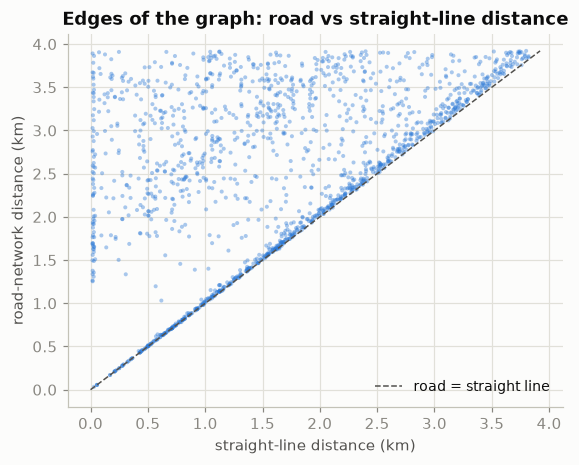

In [7]:
geo = gu.haversine_matrix(ordered_locations["latitude"].to_numpy(), ordered_locations["longitude"].to_numpy())
off = ~np.eye(N, dtype=bool)
edge = (adj > 0) & off

near = (geo < 1000) & off
n_near, n_near_unlinked = int(near.sum() // 2), int((near & ~edge & ~edge.T).sum() // 2)
print(f"sensor pairs closer than 1 km in a straight line: {n_near} (unordered pairs)")
print(f"  ...of which have NO edge in either direction of the road graph: {n_near_unlinked} ({n_near_unlinked / n_near:.0%})")
assert n_near_unlinked > 0, "expected at least some close-by pairs without a road edge"
print(f"directed edges whose endpoints are > 5 km apart in a straight line: {int((edge & (geo > 5000)).sum())}")

both = edge & np.isfinite(road_dist)
ratio = road_dist[both] / np.maximum(geo[both], 1.0)
print(f"road distance / straight-line distance over the {both.sum()} edges: median {np.median(ratio):.2f}, "
      f"5th pct {np.percentile(ratio, 5):.2f}, 95th pct {np.percentile(ratio, 95):.2f}")

fig, ax = plt.subplots(figsize=(5.8, 4.4))
ax.scatter(geo[both] / 1000, road_dist[both] / 1000, s=7, alpha=0.4, color="#2a78d6", edgecolor="none")
lim = max(geo[both].max(), road_dist[both].max()) / 1000
ax.plot([0, lim], [0, lim], color=viz.INK_2, lw=1, ls="--", label="road = straight line")
ax.set_xlabel("straight-line distance (km)"); ax.set_ylabel("road-network distance (km)")
ax.set_title("Edges of the graph: road vs straight-line distance"); ax.legend(); viz.save_figure(fig, "03_road_vs_geographic_distance"); plt.show()

**Interpretation.** Most pairs that are within 1 km of each other do have a road edge, but a non-trivial share (printed above) have
none in either direction, so a coordinate-radius graph would add connections that the road network does not support. Road distance
is also never shorter than the straight line and is typically somewhat longer (median ratio printed above), with a long tail of edges
whose road distance is many times the straight-line distance (close by on the map, far apart by road). We therefore use the
**road-distance graph** and use the coordinates **only** for maps and as static descriptors.

## 5 · Visualisation

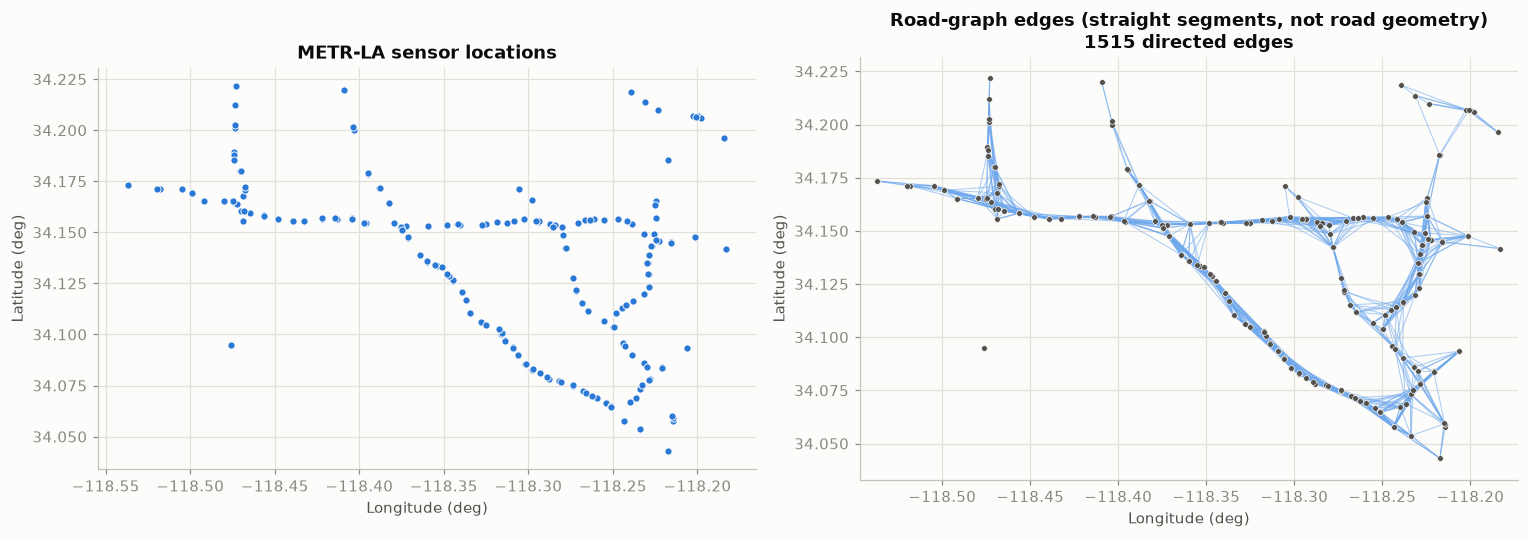

drawn edges: 1515 of 1515


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
viz.plot_sensor_locations(axes[0], ordered_locations)
n_drawn = viz.plot_graph_on_map(axes[1], ordered_locations, adj, max_edges=None, title="Road-graph edges (straight segments, not road geometry)")
fig.tight_layout(); viz.save_figure(fig, "03_sensor_locations_and_graph"); plt.show()
print(f"drawn edges: {n_drawn} of {stats['n_edges_directed']}")

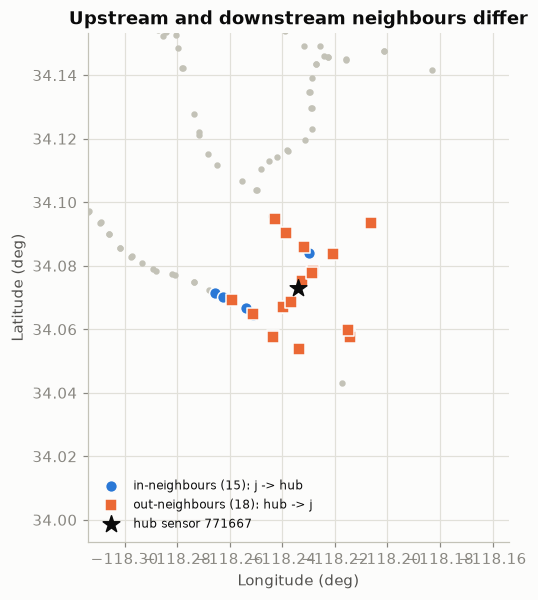

hub has 15 in-neighbours and 18 out-neighbours; 8 sensors are both


In [9]:
# Directedness made visible: the neighbourhood of the sensor with the most connections
deg_total = stats["in_degree"] + stats["out_degree"]
hub = int(np.argmax(deg_total))
in_nb, out_nb = np.flatnonzero(edge[:, hub]), np.flatnonzero(edge[hub, :])
lon, lat = ordered_locations["longitude"].to_numpy(), ordered_locations["latitude"].to_numpy()
fig, ax = plt.subplots(figsize=(7.2, 6))
ax.scatter(lon, lat, s=10, color="#c3c2b7", zorder=2)
ax.scatter(lon[in_nb], lat[in_nb], s=60, color="#2a78d6", edgecolor=viz.SURFACE, zorder=3, label=f"in-neighbours ({len(in_nb)}): j -> hub")
ax.scatter(lon[out_nb], lat[out_nb], s=60, marker="s", color="#eb6834", edgecolor=viz.SURFACE, zorder=3, label=f"out-neighbours ({len(out_nb)}): hub -> j")
ax.scatter(lon[hub], lat[hub], s=130, marker="*", color=viz.INK, zorder=4, label=f"hub sensor {traffic_ids[hub]}")
pad = 0.08
ax.set_xlim(lon[hub] - pad, lon[hub] + pad); ax.set_ylim(lat[hub] - pad, lat[hub] + pad)
ax.set_aspect(1.0 / np.cos(np.deg2rad(lat.mean()))); ax.set_xlabel("Longitude (deg)"); ax.set_ylabel("Latitude (deg)")
ax.set_title("Upstream and downstream neighbours differ"); ax.legend(loc="lower left", fontsize=8)
viz.save_figure(fig, "03_hub_neighbourhood"); plt.show()
both_dirs = np.intersect1d(in_nb, out_nb)
print(f"hub has {len(in_nb)} in-neighbours and {len(out_nb)} out-neighbours; {len(both_dirs)} sensors are both")

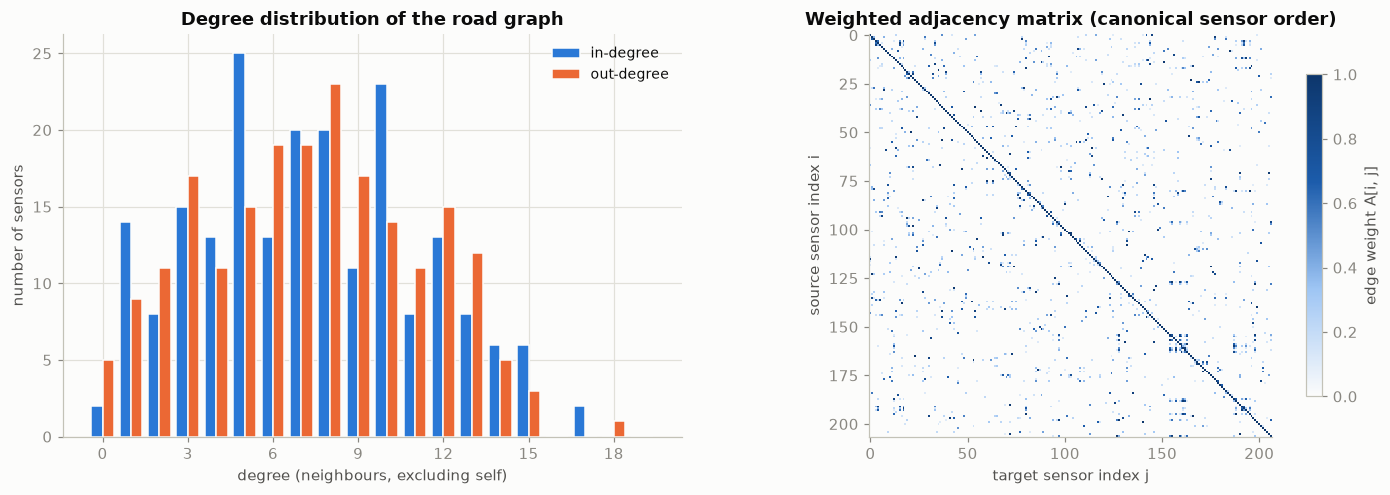

,value
measure,
sensors,207.00
directed edges (excl. self),1515.00
reciprocal edges,404.00
mean in-degree,7.32
max in-degree,17.00
max out-degree,18.00
isolated sensors,1.00
weakly connected components,2.00
largest weak component,206.00


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
viz.plot_degree_distribution(axes[0], stats["in_degree"], stats["out_degree"])
viz.plot_adjacency_heatmap(axes[1], adj, title="Weighted adjacency matrix (canonical sensor order)")
fig.tight_layout(); viz.save_figure(fig, "03_degree_and_adjacency"); plt.show()

connectivity = pd.DataFrame({
    "measure": ["sensors", "directed edges (excl. self)", "reciprocal edges", "mean in-degree", "max in-degree", "max out-degree",
                "isolated sensors", "weakly connected components", "largest weak component", "strongly connected components"],
    "value": [N, stats["n_edges_directed"], stats["n_reciprocal_edges"], round(stats["in_degree"].mean(), 2), stats["max_in_degree"],
              stats["max_out_degree"], len(stats["isolated_nodes"]), stats["n_weak_components"], stats["largest_weak_component"], stats["n_strong_components"]],
}).set_index("measure")
display(connectivity)

**Interpretation.** The graph is sparse: in- and out-degrees are small and similarly distributed. In the adjacency heatmap the
self-loop diagonal is the only clear structure; the remaining edges are scattered across the whole matrix with a few dense
clusters, i.e. the sensor-id order carries no spatial locality and any model must use the matrix itself rather than index
proximity. The graph is one weakly connected component of 206 sensors plus the isolated sensor, but it splits into many strongly
connected components because edges are directed. For a 2-block graph network this means information can reach a sensor from
neighbours up to two hops away, not from the whole network.

## 6 · Save the validated graph and lock the sensor order

Everything downstream loads these files through `graph_utils.load_graph_artifacts(expected_sensor_ids=...)`, which compares the
fingerprint of the saved order with the order of the traffic tensor and **raises** if they ever differ.

In [11]:
meta = {
    "source": "DCRNN thresholded Gaussian kernel on directed road distances (distances_la_2012.csv)",
    "normalized_k": config.GRAPH_NORMALIZED_K, "sigma_m": build_report.sigma_m,
    "n_edges_directed": stats["n_edges_directed"], "n_self_loops": stats["n_self_loops"], "directed": True,
    "reciprocal_fraction": stats["reciprocal_fraction"], "isolated_nodes": stats["isolated_nodes"],
    "n_weak_components": stats["n_weak_components"], "n_strong_components": stats["n_strong_components"],
    "distance_units": "metres", "adjacency_convention": "A[i, j] > 0 means edge i -> j",
    "sensor_ids_source": "column order of metr-la.h5",
}
gu.save_graph_artifacts(adj, road_dist, ordered_locations, meta)

art = gu.load_graph_artifacts(expected_sensor_ids=traffic_ids)       # raises AlignmentError on any order mismatch
assert np.array_equal(art.adjacency, adj) and art.sensor_ids == traffic_ids
print("saved:", [p.name for p in (config.ADJACENCY_NPY, config.DISTANCE_MATRIX_NPY, config.SENSOR_ORDER_CSV, config.GRAPH_META_JSON)])
print("fingerprint in graph_meta.json:", art.meta["sensor_order_hash"], "== traffic order:", gu.sensor_order_hash(traffic_ids))

# the guard really fires: a shuffled order is rejected
try:
    gu.load_graph_artifacts(expected_sensor_ids=traffic_ids[::-1])
    raise SystemExit("guard failed to fire")
except gu.AlignmentError as err:
    print("order guard works ->", str(err)[:90], "...")
print("\nGraph construction complete. Next: 04_baseline_models.ipynb")

saved: ['adjacency.npy', 'road_distance_matrix.npy', 'sensor_order.csv', 'graph_meta.json']
fingerprint in graph_meta.json: 2a38ef551082d02d == traffic order: 2a38ef551082d02d
order guard works -> Sensor order changed in traffic data vs saved graph: hash c3761653b5038453 != canonical 2a ...

Graph construction complete. Next: 04_baseline_models.ipynb


---
---
# Section: `04_baseline_models`

# 04 · Historical and seasonal baselines

**Objective.** Establish what can be achieved **without learning anything about the road network**: three simple, transparent baselines
that any learned model must beat to justify its complexity.

| Baseline | Forecast for `t + h` | What it captures | What it cannot learn |
|---|---|---|---|
| **A · Persistence** | the latest *observed* speed in the 60-min input window (training sensor mean if the whole window is missing) | the current state; excellent very short-term | any change: it predicts "no change" at every horizon |
| **B · Seasonal average** | mean speed of the same sensor at the same weekday and 5-min slot over the **training** period (fallbacks: weekday/weekend slot mean, then sensor mean) | the recurring daily/weekly rhythm; independent of the recent past | today's deviations from the usual pattern (incidents, weather, holidays) |
| C · Rolling mean | mean of the observed speeds in the 60-min window | smoothing of noise | trends, daily rhythm |

None of them uses any other sensor, so none of them can model congestion spreading along the road network.

**Methodology.** Use the origins/horizons/targets that *all* models share (from notebook 02); fit the seasonal table on training timestamps
only; save predictions in mph for notebook 07; evaluate with the common masked MAE / RMSE / MAPE policy.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, baselines as bl, evaluation as ev, visualization as viz
from src.metrics import compute_metrics

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)       # sensor order guard (the baselines themselves do not use edges)
N, H = len(ctx.sensor_ids), len(config.HORIZONS)
print({k: len(v) for k, v in ctx.origins.items()}, "origins | horizons (steps):", config.HORIZONS)

{'train': 23881, 'val': 3445, 'test': 6901} origins | horizons (steps): (1, 3, 6, 12)


## 1 · Fit the seasonal table on training data only

In [3]:
seasonal = bl.SeasonalAverage.fit(ctx.speed, ctx.mask, ctx.timestamps, ctx.splits.train, min_count=3)
cells = seasonal.count_dow.size
print(f"table shape [weekday, 5-min slot, sensor] = {seasonal.table_dow.shape}")
print(f"cells backed by >= {seasonal.min_count} training observations: {np.isfinite(seasonal.table_dow).mean():.1%}")
print(f"median observations behind a (weekday, slot, sensor) cell: {np.median(seasonal.count_dow):.0f}  (each weekday occurs ~{83 / 7:.0f} times in the training period)")

# which fallback level do test targets use?
tgt_ts = ctx.timestamps.values[ctx.origins["test"][:, None] + np.array(config.HORIZONS)[None, :]]     # [S, H] datetime64
_, level = seasonal.predict_at(pd.DatetimeIndex(tgt_ts.ravel()), return_level=True)
print("share of test forecasts using (1) weekday-slot mean / (2) weekday-or-weekend slot mean / (3) sensor mean:",
      [f"{(level == k).mean():.1%}" for k in (1, 2, 3)])

# leakage check: the table must not change if validation/test rows are destroyed
tampered = ctx.speed.copy(); tampered[ctx.splits.val[0]:] = 9999.0
check = bl.SeasonalAverage.fit(tampered, ctx.mask, ctx.timestamps, ctx.splits.train, min_count=3)
assert np.array_equal(np.nan_to_num(check.table_dow), np.nan_to_num(seasonal.table_dow))
print("seasonal table depends only on training rows: verified")

table shape [weekday, 5-min slot, sensor] = (7, 288, 207)
cells backed by >= 3 training observations: 100.0%
median observations behind a (weekday, slot, sensor) cell: 11  (each weekday occurs ~12 times in the training period)
share of test forecasts using (1) weekday-slot mean / (2) weekday-or-weekend slot mean / (3) sensor mean: ['100.0%', '0.0%', '0.0%']


seasonal table depends only on training rows: verified


## 2 · Generate and save the forecasts (validation and test)

In [4]:
BASELINES = ["persistence", "rolling_mean", "seasonal_avg"]
forecasts = {}
for split in ("val", "test"):
    origins = ctx.origins[split]
    preds = bl.all_baseline_forecasts(ctx.speed, ctx.mask, ctx.timestamps, ctx.locf_value, ctx.locf_age, ctx.scaler.sensor_mean,
                                      seasonal, origins)
    for name in BASELINES:
        assert preds[name].shape == (len(origins), H, N) and np.isfinite(preds[name]).all() and preds[name].min() > 0
        ev.save_predictions(name, split, preds[name], origins, config.HORIZONS,
                            {"model": name, "run_mode": config.RUN_MODE, "units": "mph"})
    forecasts[split] = preds
print({k: v.shape for k, v in forecasts["test"].items()}, "= [samples, horizons, sensors], mph; all finite and positive")
print("saved:", sorted(p.name for p in config.PREDICTIONS_DIR.glob(f"*__*.npz")))

{'persistence': (6901, 4, 207), 'rolling_mean': (6901, 4, 207), 'seasonal_avg': (6901, 4, 207)} = [samples, horizons, sensors], mph; all finite and positive
saved: ['dcrnn__test.npz', 'dcrnn__val.npz', 'gat__test.npz', 'gat__val.npz', 'gat_nograph__test.npz', 'gat_nograph__val.npz', 'gat_nograph_seed1__test.npz', 'gat_nograph_seed1__val.npz', 'gat_nograph_seed2__test.npz', 'gat_nograph_seed2__val.npz', 'gat_seed1__test.npz', 'gat_seed1__val.npz', 'gat_seed2__test.npz', 'gat_seed2__val.npz', 'persistence__test.npz', 'persistence__val.npz', 'rolling_mean__test.npz', 'rolling_mean__val.npz', 'seasonal_avg__test.npz', 'seasonal_avg__val.npz', 'xgboost__test.npz', 'xgboost__val.npz']


## 3 · Evaluation

Metric policy (shared by all models, see `src/metrics.py`): a point counts only if the true speed is **observed** and the prediction finite;
MAE/RMSE use all such points; MAPE additionally requires a true speed >= 1 mph. The number of valid points is reported next to every metric.
These baselines have no tunable parameters (the 60-minute window and the seasonal fallback rule were fixed in advance), so showing validation
*and* test scores here involves no test-set tuning.

In [5]:
def evaluate(split):
    origins = ctx.origins[split]
    y, ymask = pp.gather_targets(ctx.speed, ctx.mask, origins, config.HORIZONS)
    valid = ev.common_valid_mask(forecasts[split], ymask)
    return y, ymask, valid, ev.metrics_by_horizon(forecasts[split], y, valid, config.HORIZONS)

results = {}
for split in ("val", "test"):
    y_s, ymask_s, valid_s, table = evaluate(split)
    results[split] = (y_s, ymask_s, valid_s, table)
    table.to_csv(config.METRICS_DIR / f"{config.tagged('baselines')}_metrics_{split}.csv", index=False)
    print(f"\n=== {split.upper()} ===   valid targets: {int(valid_s.sum()):,} of {valid_s.size:,} cells ({valid_s.mean():.1%})")
    display(table.pivot(index="model", columns="horizon_min", values=["MAE", "RMSE", "MAPE"]).round(2))


=== VAL ===   valid targets: 2,659,512 of 2,852,460 cells (93.2%)


MAE                    RMSE                      MAPE         \
horizon_min     5     15    30    60    5     15    30     60     5      15   
model                                                                         
persistence   2.64  3.24  3.84  4.84  4.38  6.03  7.54   9.67   5.93   7.83   
rolling_mean  3.15  3.56  4.11  5.06  6.18  7.16  8.35  10.18   8.38   9.72   
seasonal_avg  4.32  4.32  4.33  4.33  8.07  8.07  8.08   8.08  12.62  12.63   

                            
horizon_min      30     60  
model                       
persistence    9.88  13.20  
rolling_mean  11.49  14.59  
seasonal_avg  12.64  12.65


=== TEST ===   valid targets: 5,026,522 of 5,714,028 cells (88.0%)


MAE                    RMSE                      MAPE         \
horizon_min     5     15    30    60    5     15    30     60     5      15   
model                                                                         
persistence   2.82  3.49  4.19  5.35  4.61  6.38  7.98  10.25   6.47   8.57   
rolling_mean  3.44  3.92  4.55  5.66  6.52  7.58  8.85  10.80   9.11  10.59   
seasonal_avg  4.18  4.18  4.18  4.18  7.83  7.83  7.83   7.83  12.97  12.97   

                            
horizon_min      30     60  
model                       
persistence   10.79  14.42  
rolling_mean  12.55  15.96  
seasonal_avg  12.97  12.97

In [6]:
y_t, ymask_t, valid_t, table_t = results["test"]
print("number of valid points per horizon used for every baseline (identical, because all baselines predict every cell):")
display(table_t.pivot(index="model", columns="horizon_min", values="n_valid"))
print("valid points used for MAPE (targets >= 1 mph):")
display(table_t.pivot(index="model", columns="horizon_min", values="n_valid_mape"))

best = table_t.loc[table_t.groupby("horizon_min")["MAE"].idxmin(), ["horizon_min", "model", "MAE"]].set_index("horizon_min")
print("lowest-MAE baseline per horizon on the test period:"); display(best.round(2))

number of valid points per horizon used for every baseline (identical, because all baselines predict every cell):


horizon_min,5,15,30,60
model,,,,
persistence,1256654,1256644,1256629,1256595
rolling_mean,1256654,1256644,1256629,1256595
seasonal_avg,1256654,1256644,1256629,1256595


valid points used for MAPE (targets >= 1 mph):


horizon_min,5,15,30,60
model,,,,
persistence,1256652,1256642,1256627,1256593
rolling_mean,1256652,1256642,1256627,1256593
seasonal_avg,1256652,1256642,1256627,1256593


lowest-MAE baseline per horizon on the test period:


,model,MAE
horizon_min,,
5,persistence,2.82
15,persistence,3.49
30,seasonal_avg,4.18
60,seasonal_avg,4.18


## 4 · Visualisations (test period)

Representative sensors are chosen by a fixed rule on **training** statistics only (slowest, median, fastest, most variable mean speed).

{'slowest': 'slowest (771667)', 'median': 'median (717465)', 'fastest': 'fastest (767455)', 'most_variable': 'most_variable (717462)'}


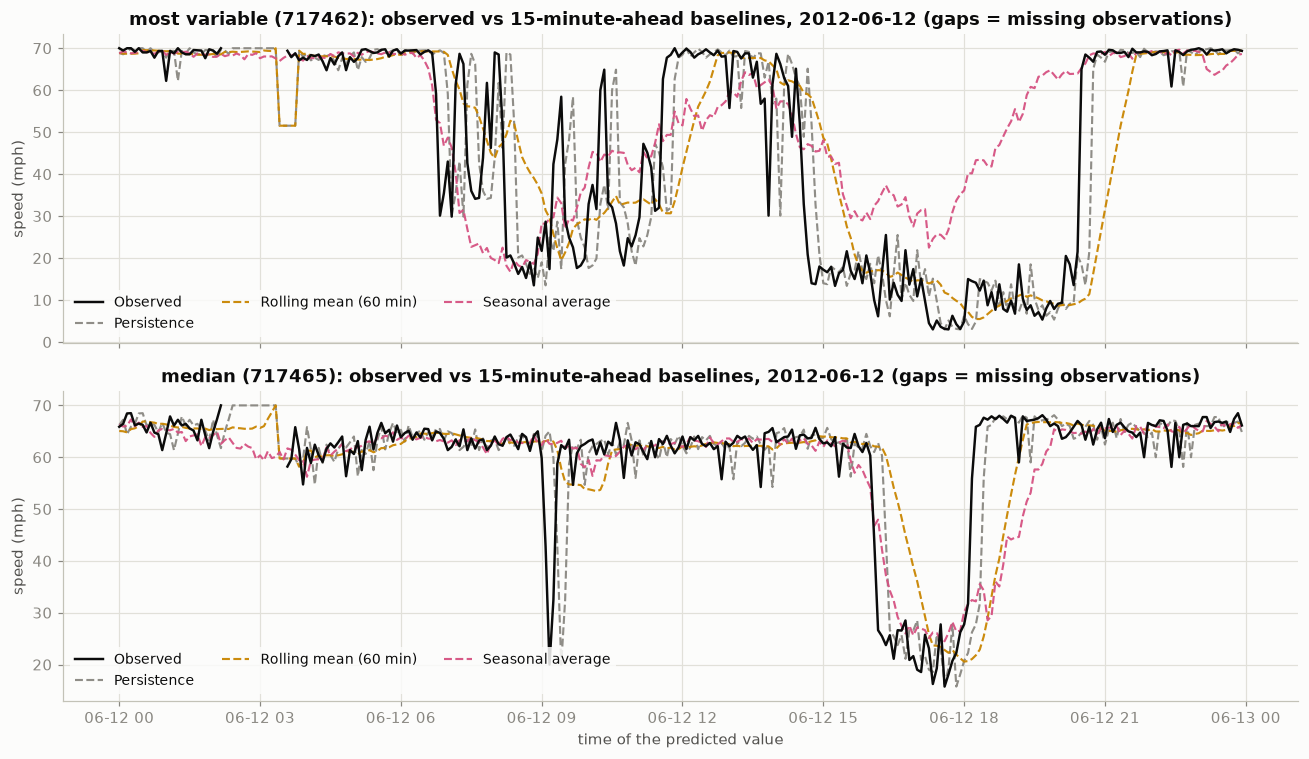

In [7]:
rep = ev.select_representative_sensors(ctx.speed, ctx.mask, ctx.splits.train, ctx.sensor_ids)
rep_labels = {k: f"{k} ({ctx.sensor_ids[v]})" for k, v in rep.items()}
print(rep_labels)

# Actual vs predicted: one weekday of the test period, horizon 15 minutes, 'most variable' sensor and 'median' sensor
j = config.HORIZONS.index(3)
day = pd.Timestamp("2012-06-12")                                   # a Tuesday inside the test period
origins = ctx.origins["test"]; tgt_time = ctx.timestamps[origins + 3]
sel = np.flatnonzero((tgt_time >= day) & (tgt_time < day + pd.Timedelta(days=1)))
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, key in zip(axes, ("most_variable", "median")):
    n = rep[key]
    actual = np.where(y_t[sel, j, n] * 0 == 0, y_t[sel, j, n], np.nan)          # NaN stays NaN -> line gap
    viz.plot_actual_vs_predicted(ax, tgt_time[sel], actual, {m: forecasts["test"][m][sel, j, n] for m in BASELINES},
                                 f"{rep_labels[key].replace('_', ' ')}: observed vs 15-minute-ahead baselines, {day.date()} (gaps = missing observations)")
axes[-1].set_xlabel("time of the predicted value")
fig.tight_layout(); viz.save_figure(fig, "04_baselines_actual_vs_predicted"); plt.show()

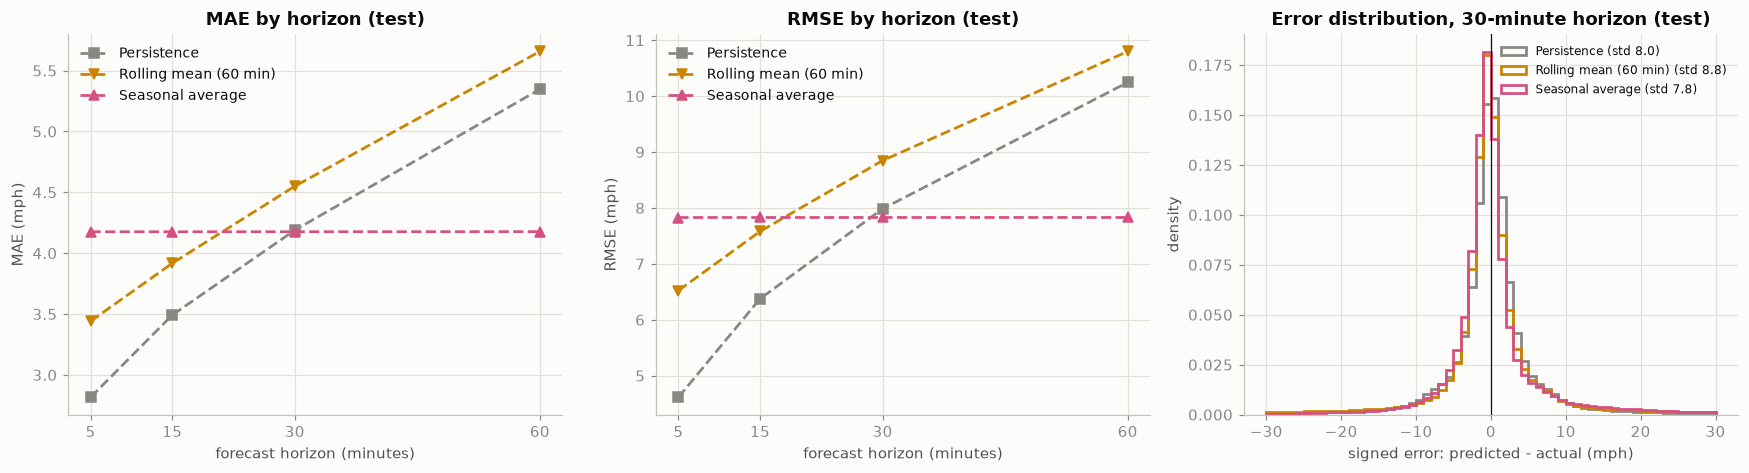

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
viz.plot_metric_vs_horizon(axes[0], table_t, "MAE", BASELINES, title="MAE by horizon (test)")
viz.plot_metric_vs_horizon(axes[1], table_t, "RMSE", BASELINES, title="RMSE by horizon (test)")
# error distribution at 30 minutes (signed error = predicted - actual)
jh = config.HORIZONS.index(6); bins = np.linspace(-30, 30, 61)
for m in BASELINES:
    err = (forecasts["test"][m][:, jh] - y_t[:, jh])[valid_t[:, jh]]
    axes[2].hist(err, bins=bins, histtype="step", lw=1.8, color=viz.style(m)["color"], label=f"{viz.style(m)['label']} (std {err.std():.1f})", density=True)
axes[2].axvline(0, color=viz.INK, lw=0.8); axes[2].set_xlabel("signed error: predicted - actual (mph)"); axes[2].set_ylabel("density")
axes[2].set_title("Error distribution, 30-minute horizon (test)"); axes[2].legend(fontsize=8)
fig.tight_layout(); viz.save_figure(fig, "04_baselines_horizon_and_errors"); plt.show()

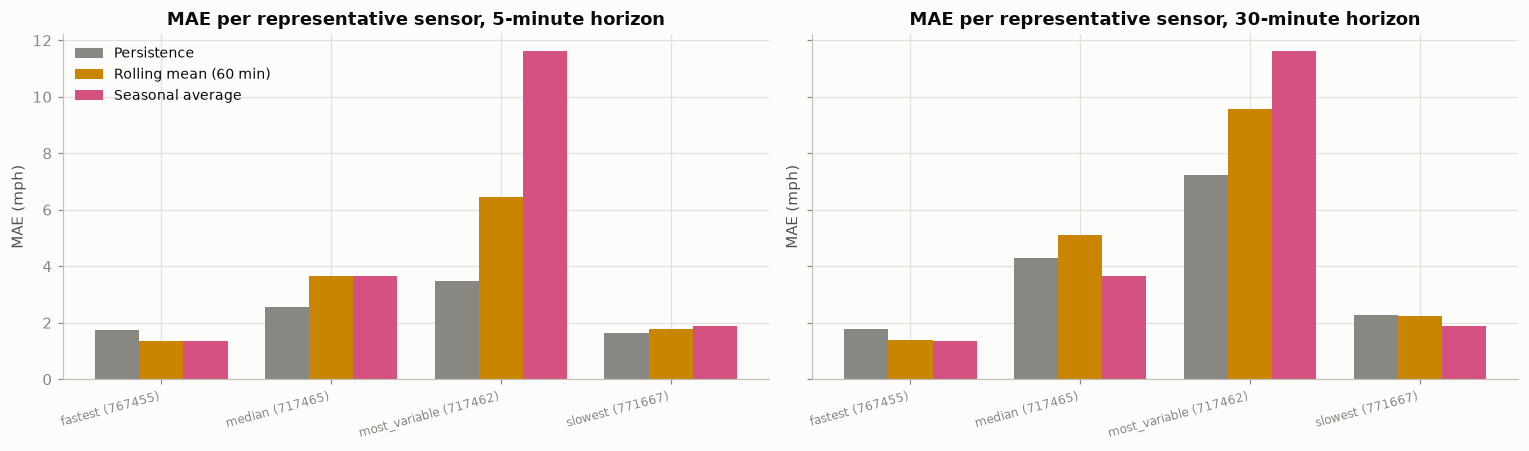

In [9]:
rows = []
for key, n in rep.items():
    for m in BASELINES:
        for hh in (1, 6):
            jj = config.HORIZONS.index(hh)
            met = compute_metrics(forecasts["test"][m][:, jj, n], y_t[:, jj, n], valid_t[:, jj, n])
            rows.append({"sensor": rep_labels[key], "model": viz.style(m)["label"], "horizon_min": hh * 5, "MAE": met["MAE"]})
per_sensor = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, hmin in zip(axes, (5, 30)):
    sub = per_sensor[per_sensor.horizon_min == hmin].pivot(index="sensor", columns="model", values="MAE")
    x = np.arange(len(sub)); w = 0.26
    for k, m in enumerate(BASELINES):
        ax.bar(x + (k - 1) * w, sub[viz.style(m)["label"]], width=w, color=viz.style(m)["color"], label=viz.style(m)["label"])
    ax.set_xticks(x, sub.index, rotation=15, ha="right", fontsize=8); ax.set_title(f"MAE per representative sensor, {hmin}-minute horizon"); ax.set_ylabel("MAE (mph)")
axes[0].legend(); fig.tight_layout(); viz.save_figure(fig, "04_baselines_per_sensor"); plt.show()

## 5 · Interpretation

The claims below are **checked in code** against the test-period metric table (a warning is printed if one does not hold in your run), so the text cannot silently drift from the executed results.

In [10]:
t = table_t.pivot(index="horizon_min", columns="model", values="MAE")
claims = {
    "persistence error grows with the horizon": bool(t["persistence"].is_monotonic_increasing),
    "persistence is the best baseline at the shortest horizon (5 min)": bool(t.loc[5].idxmin() == "persistence"),
    "seasonal-average error is (almost) independent of the horizon": bool(t["seasonal_avg"].max() - t["seasonal_avg"].min() < 0.05),
    "persistence beats the seasonal average at 5 and 15 min": bool((t.loc[[5, 15], "persistence"] < t.loc[[5, 15], "seasonal_avg"]).all()),
    "the seasonal average is within 0.1 mph of persistence at 30 min (a near tie)": bool(abs(t.loc[30, "seasonal_avg"] - t.loc[30, "persistence"]) < 0.1),
    "the seasonal average beats persistence at 60 min": bool(t.loc[60, "seasonal_avg"] < t.loc[60, "persistence"]),
    "the 60-minute rolling mean is worse than persistence at every horizon": bool((t["rolling_mean"] > t["persistence"]).all()),
}
display(ev.report_claims(claims))
print("MAE (mph):"); display(t.round(2))

,claim,holds in this run
0,persistence error grows with the horizon,True
1,persistence is the best baseline at the shorte...,True
2,seasonal-average error is (almost) independent...,True
3,persistence beats the seasonal average at 5 an...,True
4,the seasonal average is within 0.1 mph of pers...,True
5,the seasonal average beats persistence at 60 min,True
6,the 60-minute rolling mean is worse than persi...,True


MAE (mph):


model,persistence,rolling_mean,seasonal_avg
horizon_min,,,
5,2.82,3.44,4.18
15,3.49,3.92,4.18
30,4.19,4.55,4.18
60,5.35,5.66,4.18


**What the baselines show.**

* **Persistence** is very accurate five to fifteen minutes ahead (traffic rarely changes much within minutes) and degrades steadily with the horizon, because it can never anticipate a change.
* The **seasonal average** has the same error at every horizon (its forecast for a given clock time does not depend on when it was made). It roughly ties persistence at 30 minutes and is clearly better at 60 minutes: at longer horizons, knowing the usual pattern is worth more than knowing the current value. Its weakness is any deviation from the usual rhythm.
* The **rolling mean** is worse than persistence at every horizon here: averaging the last hour mostly adds lag.
* **None of them uses the road network.** A model that combines the recent state, the daily rhythm *and* neighbouring sensors has room to beat all three; whether it actually does is the subject of notebooks 05-07.
* The errors are heavy-tailed (the histogram has narrow peaks and long tails): most forecasts are close, a few large misses come from abrupt congestion onset and recovery, which these baselines cannot anticipate.

*Note on the test period:* about 12% of its cells are missing (vs ~7% in training), and missing targets are excluded here exactly as for every other model.

---
---
# Section: `05_xgboost_forecasting`

# 05 · XGBoost forecasting (the conventional per-sensor model)

**Objective.** Build the strongest reasonable **graph-agnostic** machine-learning baseline: gradient-boosted trees on lagged speeds and calendar
features of *one sensor at a time*. The graph model in notebook 06 must beat **this**, not just persistence, to claim that spatial structure helps.

**Design choices (and why)**

| Choice | Decision | Reason / limitation |
|---|---|---|
| Model scope | **one global model** per horizon, shared by all 207 sensors, with `sensor_id` (categorical), latitude, longitude and training mean as features | 207 x 4 separate models would each see few rows and cost far more; sensor identity lets the trees specialise. Limit: sensors are still modelled independently. |
| Multi-horizon strategy | **direct**: one model per horizon (1, 3, 6, 12 steps) | no error accumulation, unlike recursive forecasting; costs four fits |
| Target | residual `speed(t+h) - last observed speed` (mph) | the same anchor as persistence and the graph model: all models are compared on what they learn beyond persistence |
| Loss | absolute error (`reg:absoluteerror`) | same MAE objective as the graph model's masked-MAE loss |
| Missing inputs | lags stay `NaN`; XGBoost routes missing values natively | no imputation |
| Features | 12 lags, rolling mean (3/6/12), rolling std (6/12), trend, last observed + its age, calendar of the **target** time, static sensor descriptors | all from readings at or before the origin; **no other sensor's data** |
| Training rows | every 2nd forecast origin of the training period, observed targets only | neighbouring origins are ~92% identical; thinning halves memory |
| Selection | early stopping on **validation** residual MAE; test untouched | no test-set tuning |

> **Provenance of the delivered run.** The four models were fitted in earlier executions of this notebook (`RETRAIN = True`, about 15-20 minutes on an Apple M3, deterministic: two executions gave identical iterations and metrics).
> With `RETRAIN = False` (the delivered setting) the saved models in `artifacts/models/` and the saved validation curves are reloaded, and everything after the fit - importance, forecasts, scores - is recomputed. Set `RETRAIN = True` to refit.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, feature_engineering as fe, xgboost_model as xm, evaluation as ev, visualization as viz
from src.metrics import compute_metrics

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)        # sensor order guard (the model itself ignores edges)
N = len(ctx.sensor_ids); HZ = config.HORIZONS
loc = graph.locations
lat, lon = loc["latitude"].to_numpy(), loc["longitude"].to_numpy()
RETRAIN = False     # True: fit the models again (about 15-20 min); False: reload the saved models if they exist (fits them otherwise)
print("hyper-parameters:", {k: v for k, v in config.XGB_PARAMS.items()})
print(f"train stride {config.XGB_TRAIN_STRIDE}, validation stride {config.XGB_VAL_STRIDE}, random seed {config.SEED}")

hyper-parameters: {'objective': 'reg:absoluteerror', 'n_estimators': 1500, 'learning_rate': 0.08, 'max_depth': 8, 'min_child_weight': 20, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 5.0, 'tree_method': 'hist', 'max_cat_to_onehot': 1, 'enable_categorical': True, 'early_stopping_rounds': 40, 'random_state': 42, 'n_jobs': -1}
train stride 2, validation stride 3, random seed 42


## 1 · Feature matrices

Features are computed once per split (they do not depend on the horizon); only the five *target-time calendar* columns are added per horizon.
Rows are ordered `(origin, sensor)`; targets are the observed speeds at `origin + h`.

In [3]:
origin_sets = {
    "train": ctx.origins["train"][::config.XGB_TRAIN_STRIDE],
    "val_fit": ctx.origins["val"][::config.XGB_VAL_STRIDE],      # early stopping only
    "val": ctx.origins["val"],                                   # full validation forecasts (saved + evaluated)
    "test": ctx.origins["test"],                                 # full test forecasts (saved; scored in notebook 07)
}
BASE = {}
for name, origins in origin_sets.items():
    t0 = time.time()
    feats, names = fe.build_base_features(ctx.speed, ctx.locf_value, ctx.locf_age, ctx.scaler.sensor_mean, origins, lat, lon)
    BASE[name] = feats
    print(f"{name:8s}: {len(origins):6d} origins -> {feats.shape[0]:>9,} rows x {feats.shape[1]} base features ({feats.nbytes / 1e6:.0f} MB, {time.time() - t0:.0f}s)")
BASE_NAMES = names
ANCHOR_COL = BASE_NAMES.index("last_observed")
assert BASE["train"].shape[0] == len(origin_sets["train"]) * N

def design(split, h):
    """DataFrame of features for one horizon."""
    hz, hz_names = fe.horizon_features(ctx.timestamps, origin_sets[split], h, N)
    return fe.to_frame(BASE[split], BASE_NAMES, hz, hz_names, N)

def targets(split, h):
    """(residual target, observed flag, anchor) for every row of the split."""
    o = origin_sets[split]
    y = ctx.speed[o + h].reshape(-1)                      # origin-major rows: s * N + n
    ok = ctx.mask[o + h].reshape(-1)
    anchor = BASE[split][:, ANCHOR_COL]
    return (y - anchor), ok, anchor

# sanity: the target of row (s, n) is the speed of sensor n at origin_s + h
res, ok, anc = targets("val_fit", 3)
s_i, n_i = 5, 17
assert ok[s_i * N + n_i] == ctx.mask[origin_sets["val_fit"][s_i] + 3, n_i]
assert np.isclose(res[s_i * N + n_i] + anc[s_i * N + n_i], ctx.speed[origin_sets["val_fit"][s_i] + 3, n_i], equal_nan=True)
print(f"design matrix columns ({len(BASE_NAMES) + 5 + 0}): {BASE_NAMES} + 5 target-time calendar features")

train   :  11941 origins -> 2,471,787 rows x 24 base features (237 MB, 1s)
val_fit :   1149 origins ->   237,843 rows x 24 base features (23 MB, 0s)


val     :   3445 origins ->   713,115 rows x 24 base features (68 MB, 0s)


test    :   6901 origins -> 1,428,507 rows x 24 base features (137 MB, 0s)
design matrix columns (29): ['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'roll_mean_3', 'roll_mean_6', 'roll_mean_12', 'roll_std_6', 'roll_std_12', 'n_observed_window', 'trend_3', 'last_observed', 'age_last_observed', 'sensor_train_mean', 'latitude', 'longitude'] + 5 target-time calendar features


## 2 · Train one model per horizon (validation early stopping)

In [4]:
curves_path = config.METRICS_DIR / f"{config.tagged('xgb')}_validation_curves.json"
models, curves, fit_info = {}, {}, {}
if not RETRAIN and all(xm.model_path(h).is_file() for h in HZ) and curves_path.is_file():
    saved = json.loads(curves_path.read_text())
    for h in HZ:
        models[h] = xm.load_model(h); curves[h] = saved["curves"][str(h)]; fit_info[h] = saved["fit_info"][str(h)]
    print("reloaded the saved models (training was run in an earlier execution of this notebook; its fit summary is shown below)")
else:
    for h in HZ:
        t0 = time.time()
        X_tr, (r_tr, ok_tr, _) = design("train", h), targets("train", h)
        X_va, (r_va, ok_va, _) = design("val_fit", h), targets("val_fit", h)
        m = xm.fit_horizon_model(X_tr[ok_tr], r_tr[ok_tr], X_va[ok_va], r_va[ok_va])
        models[h] = m
        curves[h] = m.evals_result()["validation_0"]["mae"]
        fit_info[h] = {"horizon_min": h * 5, "train_rows": int(ok_tr.sum()), "val_rows": int(ok_va.sum()),
                       "best_iteration": int(m.best_iteration) + 1, "val_residual_MAE": float(min(curves[h])), "seconds": round(time.time() - t0)}
        print(f"h={h:2d} ({h * 5:2d} min): {fit_info[h]['train_rows']:,} training rows | best iteration {fit_info[h]['best_iteration']} | "
              f"validation residual MAE {fit_info[h]['val_residual_MAE']:.3f} mph | {fit_info[h]['seconds']}s")
        del X_tr, X_va
    xm.save_models(models, {"seed": config.SEED, "train_stride": config.XGB_TRAIN_STRIDE, "feature_names": BASE_NAMES, "run_mode": config.RUN_MODE,
                            "fit_info": {str(k): v for k, v in fit_info.items()}})
    curves_path.write_text(json.dumps({"curves": {str(k): v for k, v in curves.items()}, "fit_info": {str(k): v for k, v in fit_info.items()}}))
display(pd.DataFrame(fit_info).T)
print("saved models:", sorted(p.name for p in config.MODELS_DIR.glob(f"{config.tagged('xgb')}*")))

reloaded the saved models (training was run in an earlier execution of this notebook; its fit summary is shown below)


,horizon_min,train_rows,val_rows,best_iteration,val_residual_MAE,seconds
1,5.0,2296387.0,222088.0,844.0,2.167280,227.0
3,15.0,2296389.0,221704.0,782.0,2.635541,206.0
6,30.0,2293530.0,221497.0,1082.0,3.039496,337.0
12,60.0,2293535.0,221288.0,1124.0,3.490487,294.0


saved models: ['xgb_h1.json', 'xgb_h12.json', 'xgb_h3.json', 'xgb_h6.json', 'xgb_hyperparameters.json']


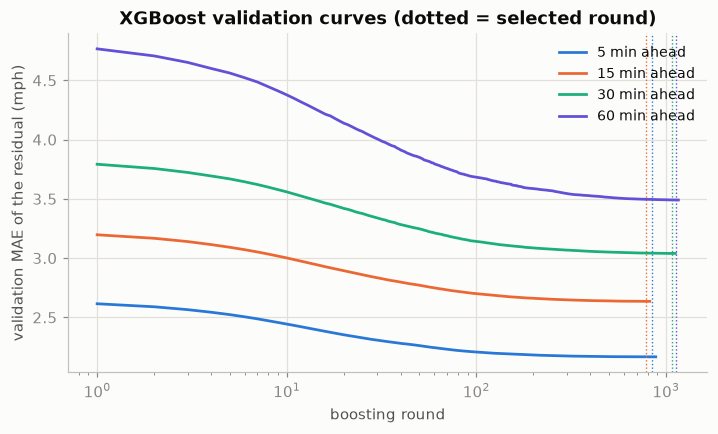

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for h, color in zip(HZ, ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]):
    ax.plot(np.arange(1, len(curves[h]) + 1), curves[h], color=color, label=f"{h * 5} min ahead")
    ax.axvline(fit_info[h]["best_iteration"], color=color, ls=":", lw=0.9)
ax.set_xlabel("boosting round"); ax.set_ylabel("validation MAE of the residual (mph)"); ax.set_xscale("log")
ax.set_title("XGBoost validation curves (dotted = selected round)"); ax.legend()
viz.save_figure(fig, "05_xgboost_validation_curves"); plt.show()

**Interpretation.** Each horizon is fitted until the validation error stops improving; later horizons are harder (larger residual error) and are
allowed to use more rounds. The dotted lines mark the model that is kept (early stopping on validation only).

## 3 · Feature importance

Gain-based importance: how much each feature reduced the loss across all trees (relative within one model; not causal).

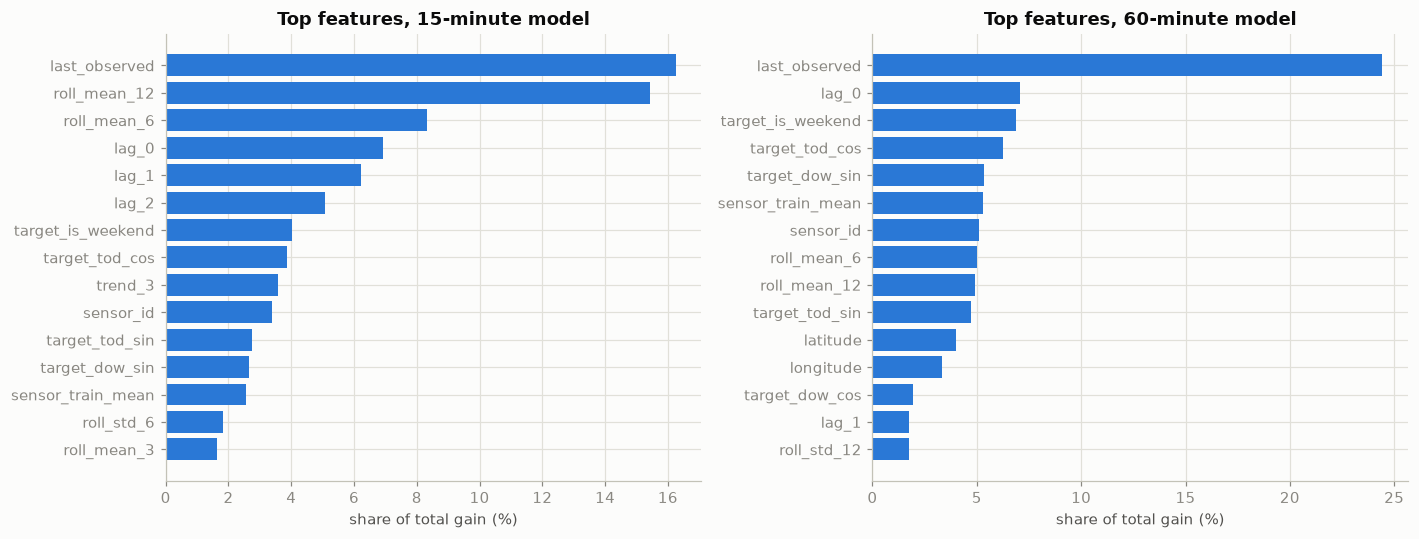

,5 min,15 min,30 min,60 min
lag_0,0.063,0.069,0.077,0.071
lag_1,0.069,0.062,NaN,NaN
lag_2,0.049,0.051,NaN,NaN
last_observed,0.161,0.163,0.188,0.244
roll_mean_12,0.212,0.154,0.076,NaN
roll_mean_6,0.100,0.083,0.078,NaN
sensor_train_mean,NaN,NaN,NaN,0.053
target_dow_sin,NaN,NaN,NaN,0.053
target_is_weekend,NaN,NaN,0.055,0.069
target_tod_cos,NaN,NaN,0.049,0.062


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, h in zip(axes, (3, 12)):
    gain = pd.Series(models[h].get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
    top = (gain / gain.sum()).head(15)[::-1]
    ax.barh(top.index, top.values * 100, color="#2a78d6")
    ax.set_xlabel("share of total gain (%)"); ax.set_title(f"Top features, {h * 5}-minute model")
fig.tight_layout(); viz.save_figure(fig, "05_xgboost_feature_importance"); plt.show()
importance = {h: pd.Series(models[h].get_booster().get_score(importance_type="gain")) for h in HZ}
display(pd.DataFrame({f"{h * 5} min": (v / v.sum()).sort_values(ascending=False).head(6).round(3) for h, v in importance.items()}))

## 4 · Forecast all validation and test origins and save

Predictions are `last observed + predicted residual` in mph, saved in the same `[samples, horizons, sensors]` layout as every other model.

In [7]:
preds = {}
for split in ("val", "test"):
    out = np.empty((len(origin_sets[split]), len(HZ), N), dtype=np.float32)
    for j, h in enumerate(HZ):
        X = design(split, h)
        out[:, j, :] = xm.predict_speed(models[h], X).reshape(-1, N)
        del X
    assert np.isfinite(out).all()
    preds[split] = out                                    # raw model output; clipping to 0..70 mph is applied when scoring
    ev.save_predictions("xgboost", split, out, origin_sets[split], HZ, {"model": "xgboost", "run_mode": config.RUN_MODE, "units": "mph", "seed": config.SEED})
    print(split, out.shape, "= [samples, horizons, sensors] mph | prediction range", float(out.min()).__round__(1), "to", float(out.max()).__round__(1))

val (3445, 4, 207) = [samples, horizons, sensors] mph | prediction range -1.0 to 87.0


test (6901, 4, 207) = [samples, horizons, sensors] mph | prediction range 0.2 to 83.9


## 5 · Validation results (the test period is not scored here)

The final, identical-rules comparison on the test period is done in notebook 07. Here we only check the model on the validation period
and against the saved baseline forecasts for the same origins.

In [8]:
names = ["persistence", "seasonal_avg"]
val_preds = {"xgboost": ev.clip_predictions(preds["val"])}      # same clipping rule as every model (0..70 mph)
for n in names:
    d = ev.load_predictions(n, "val")
    assert np.array_equal(d["origins"], origin_sets["val"]) and d["horizons"] == HZ      # identical samples and horizons
    val_preds[n] = d["pred"]
yv, mv = pp.gather_targets(ctx.speed, ctx.mask, origin_sets["val"], HZ)
valid = ev.common_valid_mask(val_preds, mv)
table = ev.metrics_by_horizon(val_preds, yv, valid, HZ)
table.to_csv(config.METRICS_DIR / f"{config.tagged('xgboost')}_metrics_val.csv", index=False)
display(table.pivot(index="model", columns="horizon_min", values=["MAE", "RMSE", "MAPE"]).round(2))
print(f"valid validation targets: {int(valid.sum()):,}")

MAE                    RMSE                     MAPE         \
horizon_min     5     15    30    60    5     15    30    60     5      15   
model                                                                        
persistence   2.64  3.24  3.84  4.84  4.38  6.03  7.54  9.67   5.93   7.83   
seasonal_avg  4.32  4.32  4.33  4.33  8.07  8.07  8.08  8.08  12.62  12.63   
xgboost       2.16  2.64  3.05  3.50  3.83  5.26  6.29  7.22   5.15   7.03   

                            
horizon_min      30     60  
model                       
persistence    9.88  13.20  
seasonal_avg  12.64  12.65  
xgboost        8.89  10.83

valid validation targets: 2,659,512


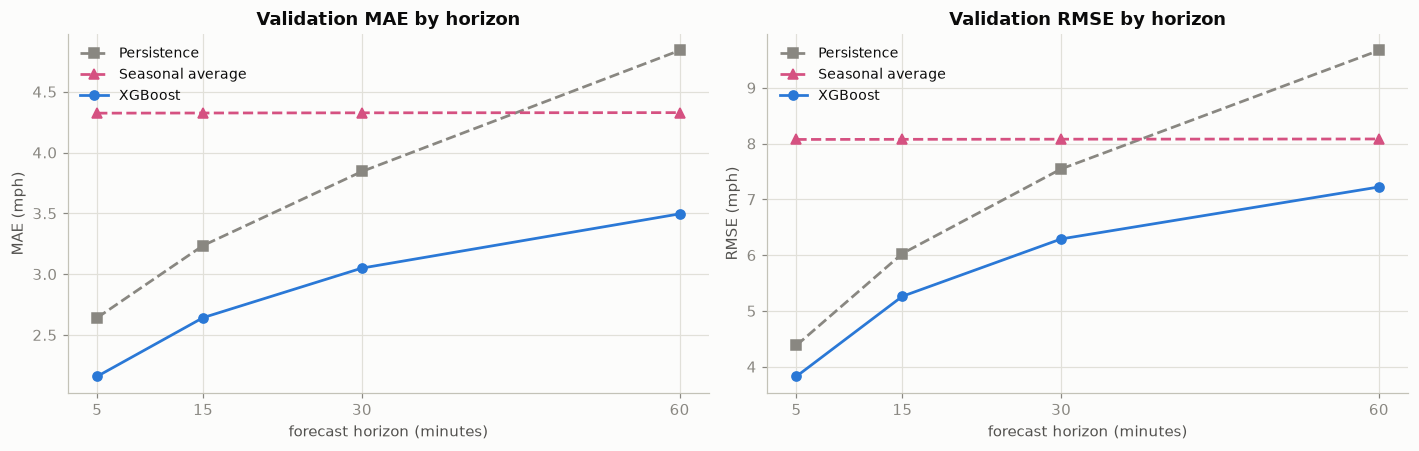

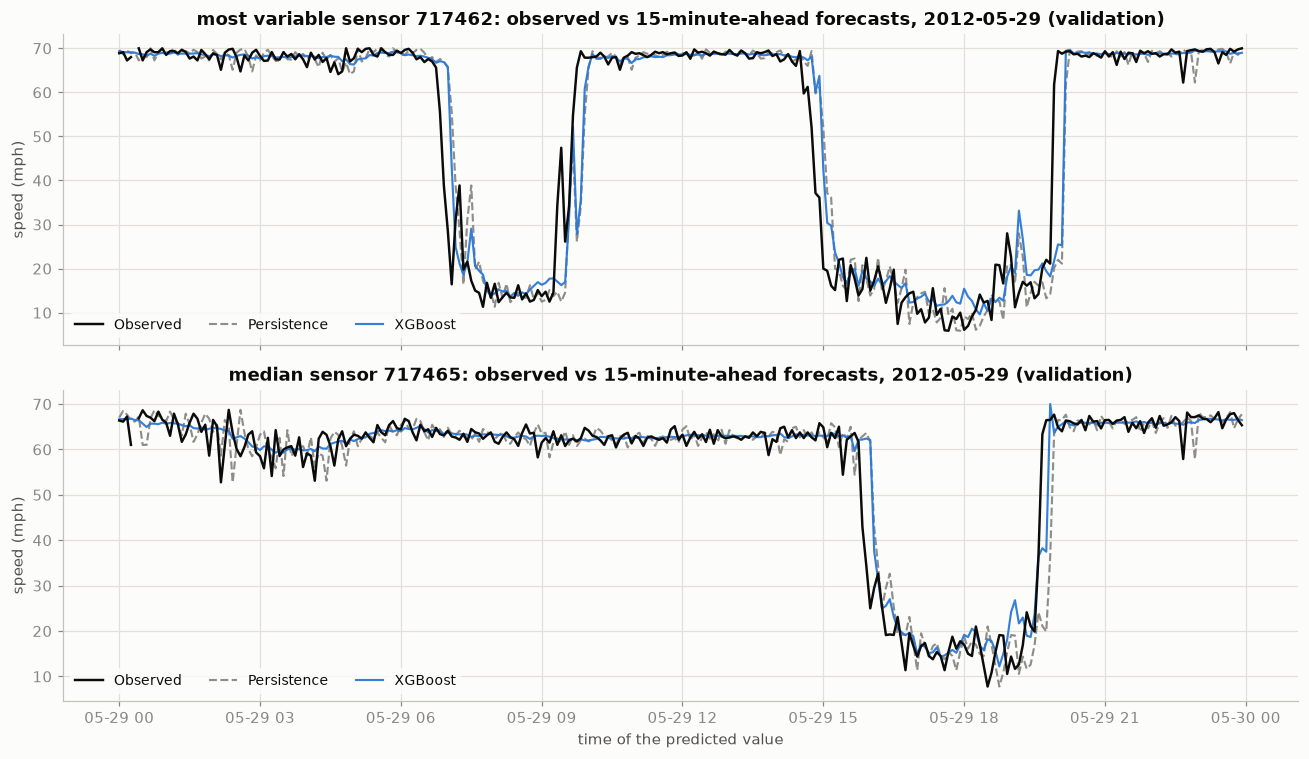

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
viz.plot_metric_vs_horizon(axes[0], table, "MAE", ["persistence", "seasonal_avg", "xgboost"], title="Validation MAE by horizon")
viz.plot_metric_vs_horizon(axes[1], table, "RMSE", ["persistence", "seasonal_avg", "xgboost"], title="Validation RMSE by horizon")
fig.tight_layout(); viz.save_figure(fig, "05_xgboost_val_horizon"); plt.show()

# actual vs predicted on a validation day, 15-minute horizon, two sensors (rule fixed on training statistics)
rep = ev.select_representative_sensors(ctx.speed, ctx.mask, ctx.splits.train, ctx.sensor_ids)
j = HZ.index(3); day = pd.Timestamp("2012-05-29")                    # a Tuesday inside the validation period
tgt_time = ctx.timestamps[origin_sets["val"] + 3]
sel = np.flatnonzero((tgt_time >= day) & (tgt_time < day + pd.Timedelta(days=1)))
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, key in zip(axes, ("most_variable", "median")):
    n = rep[key]
    viz.plot_actual_vs_predicted(ax, tgt_time[sel], yv[sel, j, n], {m: val_preds[m][sel, j, n] for m in ("persistence", "xgboost")},
                                 f"{key.replace('_', ' ')} sensor {ctx.sensor_ids[n]}: observed vs 15-minute-ahead forecasts, {day.date()} (validation)")
axes[-1].set_xlabel("time of the predicted value")
fig.tight_layout(); viz.save_figure(fig, "05_xgboost_actual_vs_predicted"); plt.show()

## 6 · Interpretation

The claims below are checked in code against the validation results and the feature importances (a warning is printed if one does not hold in your run).

In [10]:
t = table.pivot(index="horizon_min", columns="model", values="MAE")
gain = 100 * (t["persistence"] - t["xgboost"]) / t["persistence"]
print("validation MAE improvement of XGBoost over persistence (% ; positive = XGBoost has lower error):")
display(gain.round(1).to_frame("improvement %"))

recent_speed = lambda f: f.startswith(("lag_", "roll_", "last_observed", "trend_"))
top2 = {h: list((importance[h] / importance[h].sum()).sort_values(ascending=False).index[:2]) for h in HZ}
print("two most important features per horizon (gain):", {f"{h * 5} min": v for h, v in top2.items()})
claims = {
    "XGBoost beats persistence at every horizon on validation": bool((t["xgboost"] < t["persistence"]).all()),
    "XGBoost beats the seasonal average at every horizon on validation": bool((t["xgboost"] < t["seasonal_avg"]).all()),
    "its relative gain over persistence grows with the horizon": bool(gain.is_monotonic_increasing),
    "the two most important features at every horizon are recent-speed features": all(all(recent_speed(f) for f in v) for v in top2.values()),
}
display(ev.report_claims(claims))

validation MAE improvement of XGBoost over persistence (% ; positive = XGBoost has lower error):


,improvement %
horizon_min,
5,18.2
15,18.3
30,20.7
60,27.8


two most important features per horizon (gain): {'5 min': ['roll_mean_12', 'last_observed'], '15 min': ['last_observed', 'roll_mean_12'], '30 min': ['last_observed', 'roll_mean_6'], '60 min': ['last_observed', 'lag_0']}


,claim,holds in this run
0,XGBoost beats persistence at every horizon on ...,True
1,XGBoost beats the seasonal average at every ho...,True
2,its relative gain over persistence grows with ...,True
3,the two most important features at every horiz...,True


**What this shows.**

* A gradient-boosted tree model on one sensor's own recent history clearly improves on persistence at every horizon on the validation period, and the advantage grows with the horizon: it learns typical recovery from and onset of slow traffic, which persistence cannot.
* Its gain is dominated by **recent-speed features** (the last observed speed and recent rolling means); calendar features and the sensor id come well after them. At the longer horizons the calendar and sensor descriptors contribute more, consistent with a daily rhythm doing more work when the recent past says less.
* This model has **no access to other sensors**. It is therefore the right benchmark for the research question: any advantage of the graph model over it must come from information in neighbouring sensors (or from the different model family, which the no-edge ablation in notebook 06 separates out).
* These are *validation* numbers used for early stopping. The model was never evaluated on the test period here; the final comparison is in notebook 07.
* Raw tree predictions can leave the physical 0-70 mph range (see the printed prediction range); all models are clipped to that range when scored.

---
---
# Section: `05b_xgboost_spatial`

# 05b · XGBoost with road-graph neighbour features (spatial tree baseline)

**Why this notebook.** Notebook 05's XGBoost sees each sensor in isolation, so "ST-GAT beats XGBoost" mixes two things: the use of neighbouring sensors and
the different model family. Here the **same** XGBoost (same rows, hyper-parameters, residual target, validation early stopping) additionally receives
features of each sensor's **road-graph neighbours**. If this closes most of the gap to the ST-GAT, the benefit comes from spatial information rather than from the
neural architecture.

**Neighbour features** (`feature_engineering.build_neighbour_features`), separately for upstream (edge `j -> i`) and downstream (`i -> j`) neighbours of the validated
road graph: edge-weighted mean speed at the origin and 15 minutes earlier, the slowest neighbour at the origin, and how many neighbours are observed. Only readings at or
before the origin are used (unit-tested); missing neighbours are ignored, never treated as zero.

> **Provenance.** `RETRAIN = False` reloads the saved models if they exist (and fits them otherwise); the fit was run once in an earlier execution of this notebook.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, feature_engineering as fe, xgboost_model as xm, evaluation as ev, visualization as viz

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)
N, HZ = len(ctx.sensor_ids), config.HORIZONS
lat, lon = graph.locations["latitude"].to_numpy(), graph.locations["longitude"].to_numpy()
RETRAIN = False
PREFIX, KEY = "xgb_spatial", "xgboost_spatial"

## 1 · Feature matrices (base features of notebook 05 + neighbour features)

In [3]:
origin_sets = {"train": ctx.origins["train"][::config.XGB_TRAIN_STRIDE], "val_fit": ctx.origins["val"][::config.XGB_VAL_STRIDE],
               "val": ctx.origins["val"], "test": ctx.origins["test"]}
FEATS, NAMES = {}, None
for name, o in origin_sets.items():
    base, base_names = fe.build_base_features(ctx.speed, ctx.locf_value, ctx.locf_age, ctx.scaler.sensor_mean, o, lat, lon)
    nbr, nbr_names = fe.build_neighbour_features(ctx.speed, graph.adjacency, o)
    FEATS[name] = np.hstack([base, nbr]); NAMES = base_names + nbr_names
    print(f"{name:8s}: {FEATS[name].shape[0]:>9,} rows x {FEATS[name].shape[1]} features ({FEATS[name].nbytes / 1e6:.0f} MB)")
ANCHOR = NAMES.index("last_observed")
print("neighbour features:", nbr_names)
nbr_block = FEATS["test"][:, len(base_names):]
print("share of rows with no observed upstream / downstream neighbour (isolated sensor or missing data):",
      f"{np.isnan(nbr_block[:, nbr_names.index('up_mean_lag0')]).mean():.1%} / {np.isnan(nbr_block[:, nbr_names.index('down_mean_lag0')]).mean():.1%}")

def design(split, h):
    hz, hz_names = fe.horizon_features(ctx.timestamps, origin_sets[split], h, N)
    return fe.to_frame(FEATS[split], NAMES, hz, hz_names, N)

def targets(split, h):
    o = origin_sets[split]
    y = ctx.speed[o + h].reshape(-1); ok = ctx.mask[o + h].reshape(-1)
    return y - FEATS[split][:, ANCHOR], ok

train   : 2,471,787 rows x 32 features (316 MB)
val_fit :   237,843 rows x 32 features (30 MB)


val     :   713,115 rows x 32 features (91 MB)


test    : 1,428,507 rows x 32 features (183 MB)
neighbour features: ['up_mean_lag0', 'up_min_lag0', 'up_n_observed', 'up_mean_lag3', 'down_mean_lag0', 'down_min_lag0', 'down_n_observed', 'down_mean_lag3']
share of rows with no observed upstream / downstream neighbour (isolated sensor or missing data): 10.8% / 12.1%


## 2 · Fit one model per horizon (identical settings to notebook 05)

In [4]:
curves_path = config.METRICS_DIR / f"{config.tagged(PREFIX)}_validation_curves.json"
models, fit_info = {}, {}
if not RETRAIN and all(xm.model_path(h, PREFIX).is_file() for h in HZ) and curves_path.is_file():
    saved = json.loads(curves_path.read_text())
    for h in HZ:
        models[h] = xm.load_model(h, PREFIX); fit_info[h] = saved["fit_info"][str(h)]
    print("reloaded the saved models (fitted in an earlier execution)")
else:
    curves = {}
    for h in HZ:
        t0 = time.time()
        X_tr, (r_tr, ok_tr) = design("train", h), targets("train", h)
        X_va, (r_va, ok_va) = design("val_fit", h), targets("val_fit", h)
        m = xm.fit_horizon_model(X_tr[ok_tr], r_tr[ok_tr], X_va[ok_va], r_va[ok_va])
        models[h] = m; curves[h] = m.evals_result()["validation_0"]["mae"]
        fit_info[h] = {"horizon_min": h * 5, "train_rows": int(ok_tr.sum()), "best_iteration": int(m.best_iteration) + 1,
                       "val_residual_MAE": float(min(curves[h])), "seconds": round(time.time() - t0)}
        print(f"h={h:2d}: best iteration {fit_info[h]['best_iteration']}, validation residual MAE {fit_info[h]['val_residual_MAE']:.3f} mph, {fit_info[h]['seconds']}s")
        del X_tr, X_va
    xm.save_models(models, {"seed": config.SEED, "feature_names": NAMES, "fit_info": {str(k): v for k, v in fit_info.items()}}, prefix=PREFIX)
    curves_path.write_text(json.dumps({"curves": {str(k): v for k, v in curves.items()}, "fit_info": {str(k): v for k, v in fit_info.items()}}))
display(pd.DataFrame(fit_info).T)

h= 1: best iteration 1492, validation residual MAE 2.088 mph, 265s


h= 3: best iteration 1500, validation residual MAE 2.556 mph, 268s


h= 6: best iteration 1476, validation residual MAE 2.955 mph, 273s


h=12: best iteration 1500, validation residual MAE 3.415 mph, 244s


,horizon_min,train_rows,best_iteration,val_residual_MAE,seconds
1,5.0,2296387.0,1492.0,2.088368,265.0
3,15.0,2296389.0,1500.0,2.555772,268.0
6,30.0,2293530.0,1476.0,2.955285,273.0
12,60.0,2293535.0,1500.0,3.414736,244.0


## 3 · How much do the trees use the neighbour features?

,share of gain from neighbour features,top feature,best neighbour feature
5 min,0.110882,roll_mean_12,down_mean_lag0
15 min,0.110505,last_observed,down_mean_lag0
30 min,0.106266,last_observed,up_mean_lag0
60 min,0.090457,last_observed,down_n_observed


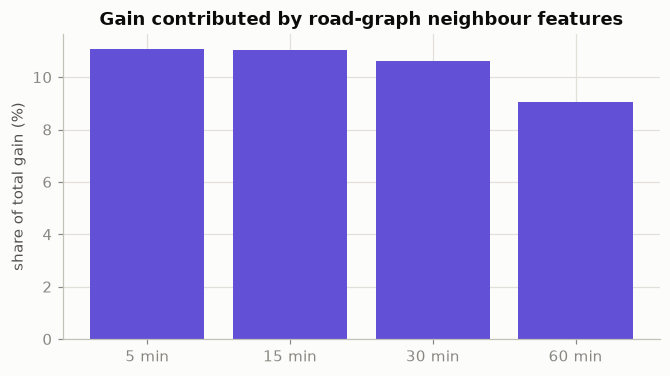

In [5]:
rows = {}
for h in HZ:
    g = pd.Series(models[h].get_booster().get_score(importance_type="gain")); g = g / g.sum()
    rows[f"{h * 5} min"] = {"share of gain from neighbour features": g[[c for c in g.index if c.startswith(("up_", "down_"))]].sum(),
                            "top feature": g.idxmax(), "best neighbour feature": g[[c for c in g.index if c.startswith(("up_", "down_"))]].idxmax()}
importance = pd.DataFrame(rows).T
display(importance)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(importance.index, importance["share of gain from neighbour features"].astype(float) * 100, color=viz.style(KEY)["color"])
ax.set_ylabel("share of total gain (%)"); ax.set_title("Gain contributed by road-graph neighbour features")
viz.save_figure(fig, "05b_neighbour_feature_gain"); plt.show()

## 4 · Forecasts (validation and test) and validation comparison

In [6]:
preds = {}
for split in ("val", "test"):
    out = np.empty((len(origin_sets[split]), len(HZ), N), dtype=np.float32)
    for j, h in enumerate(HZ):
        out[:, j, :] = xm.predict_speed(models[h], design(split, h)).reshape(-1, N)
    assert np.isfinite(out).all()
    ev.save_predictions(KEY, split, out, origin_sets[split], HZ, {"model": KEY, "units": "mph", "run_mode": config.RUN_MODE})
    preds[split] = out
val_preds = {KEY: ev.clip_predictions(preds["val"])}
for other in ("xgboost", "gat"):
    d = ev.load_predictions(other, "val"); assert np.array_equal(d["origins"], origin_sets["val"]); val_preds[other] = d["pred"]
yv, mv = pp.gather_targets(ctx.speed, ctx.mask, origin_sets["val"], HZ)
valid = ev.common_valid_mask(val_preds, mv)
table = ev.metrics_by_horizon(val_preds, yv, valid, HZ)
display(table.pivot(index="model", columns="horizon_min", values=["MAE", "RMSE"]).round(3))
print("Validation only; the test-period comparison with intervals is in notebook 07.")

MAE                        RMSE                     
horizon_min         5      15     30     60     5      15     30     60
model                                                                  
gat              2.116  2.513  2.849  3.242  3.691  4.851  5.796  6.811
xgboost          2.159  2.642  3.050  3.495  3.827  5.261  6.290  7.221
xgboost_spatial  2.081  2.562  2.961  3.419  3.607  4.965  5.989  6.976

Validation only; the test-period comparison with intervals is in notebook 07.


---
---
# Section: `06_graph_attention_network`

# 06 · Graph Attention Network (ST-GAT)

**Objective.** Train the primary research model: a spatio-temporal **graph attention network** that forecasts speed at all 207 sensors for
the next 12 steps, using the validated road graph. Then answer the research question's graph-specific part with an **ablation**: the
*same* network, same parameter count, same training recipe, but with every graph edge removed.

**Why a graph attention network?** Congestion propagates along roads. A graph attention layer lets each sensor re-weight the
information coming from its connected sensors, instead of treating them equally or ignoring them.

**Methodology.**
1. Build the tensors `x [B, 12, 207, 6]` (scaled speed with 0 where missing, observed-mask, 4 calendar features) and the residual-forecast target.
2. Architecture (below), with a numerical check that our masked dense attention equals PyTorch Geometric's `GATConv`.
3. Train with masked MAE, validation-based checkpointing and early stopping; keep only the best-validation weights.
4. Predict validation and test at horizons 1, 3, 6, 12 in **mph** and save for notebook 07. (Test metrics are *not* examined here; the test period stays untouched until the final evaluation.)
5. Train the no-edge ablation under identical conditions.
6. Inspect the learned attention, cautiously.

## Architecture and information flow

```
x [B, T=12, N=207, F=6]
   │ Linear(F→d)                              per sensor and time step
   ▼
[B, T, N, d] ─ GRU over T (weights shared by all sensors) ─▶ h [B, N, d]      temporal encoder
   │ concat learned sensor embedding (16) → Linear → h0 [B, N, d]
   ▼
 2 × GAT block:  z = LayerNorm(g)
                 out = GAT_in(z) + GAT_out(z)      4 heads each, attention only over graph neighbours (+ self)
                 g   = g + Dropout(ELU(out))        residual connection
   ▼
[g, h0] ─ MLP ─▶ residual [B, N, 12]                forecasting head (12 future steps at once)
prediction = anchor + residual                      anchor = last observed speed in the window (same as persistence)
```

* **`GAT_in`**: node *i* attends to sensors *j* with an edge `j → i` (upstream neighbours) and to itself; **`GAT_out`**: to sensors with an edge `i → j` (downstream) and itself. Scores for every other pair are set to `-inf` before the softmax, so they receive *exactly zero* attention. The graph therefore genuinely restricts the attention: nothing is unrestricted all-to-all.
* **Missing data.** Missing inputs are 0 in scaled space (the training mean) *and* flagged by the mask channel. The loss and the validation score count **only observed targets**.
* **Same target as every other model**: speed in mph at steps 1, 3, 6, 12; the network predicts all 12 steps (multi-step training) and we read off those four.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, gat_model as gm, evaluation as ev, visualization as viz
from src.metrics import compute_metrics

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()                                          # processed data from notebook 02
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)   # raises if the sensor order ever differs
N = len(ctx.sensor_ids)
device = gm.select_device()
print(f"{N} sensors | device: {device} | train/val/test origins: {[len(ctx.origins[k]) for k in pp.SPLIT_NAMES]}")

207 sensors | device: mps | train/val/test origins: [23881, 3445, 6901]


## 1 · Experiment switches and input tensors

`RETRAIN = False` reloads existing checkpoints from `artifacts/models/` instead of training again (useful after a restart); a model whose checkpoint does not exist is trained.
`EXTRA_SEEDS` trains additional seeds of both models, to measure how much results depend on initialisation.

> **Provenance of the delivered run.** The primary models (seed 42: ST-GAT and its no-edge ablation) were trained in an earlier execution of this notebook with `RETRAIN = True`;
> their full epoch-by-epoch training logs are printed again below when the checkpoints are reloaded (the logs are also kept in `artifacts/metrics/*_train.log`). Any model that has no checkpoint yet (for example
> extra seeds listed in `EXTRA_SEEDS`) is trained by the execution whose outputs you see. Set `RETRAIN = True` to reproduce everything from scratch (about 45 minutes per model on an Apple M3).

In [3]:
RETRAIN = False         # True: retrain every model from scratch; False: reuse a checkpoint if it exists (trains it otherwise)
RUN_ABLATION = True     # train the "no edges" twin of the model
EXTRA_SEEDS = (1, 2)    # additional seeds of both models to measure initialisation sensitivity; () = single seed only

params = dict(config.GAT_PARAMS)
data = gm.GraphData(
    speed=ctx.speed, mask=ctx.mask, values_scaled=pp.fill_for_model(ctx.speed, ctx.mask, ctx.scaler),
    time_feats=pp.time_feature_matrix(ctx.timestamps), locf_value=ctx.locf_value, locf_age=ctx.locf_age, scaler=ctx.scaler,
)
train_origins = pp.evenly_spaced(ctx.origins["train"], params["train_origin_limit"])
val_origins, test_origins = ctx.origins["val"], ctx.origins["test"]

x, anchor, y, valid = data.batch(train_origins[:4], torch.device("cpu"))
print("one batch of 4 training origins:")
print(f"  x      {tuple(x.shape)}  [batch, 12 steps, 207 sensors, 6 features]")
print(f"  anchor {tuple(anchor.shape)}  scaled last-observed speed per sensor")
print(f"  y      {tuple(y.shape)}  scaled targets for 12 steps;  valid {tuple(valid.shape)}  (1 = observed target)")
print(f"  share of valid targets in this batch: {valid.mean():.1%} | NaNs in x/y/anchor: {int(torch.isnan(x).sum() + torch.isnan(y).sum() + torch.isnan(anchor).sum())}")
assert not torch.isnan(x).any() and not torch.isnan(y).any() and not torch.isnan(anchor).any()
print("hyper-parameters:", {k: v for k, v in params.items()})

one batch of 4 training origins:
  x      (4, 12, 207, 6)  [batch, 12 steps, 207 sensors, 6 features]
  anchor (4, 207)  scaled last-observed speed per sensor
  y      (4, 12, 207)  scaled targets for 12 steps;  valid (4, 12, 207)  (1 = observed target)
  share of valid targets in this batch: 99.0% | NaNs in x/y/anchor: 0
hyper-parameters: {'d_model': 64, 'n_heads': 4, 'n_gat_layers': 2, 'node_emb_dim': 16, 'dropout': 0.1, 'attn_dropout': 0.1, 'batch_size': 64, 'lr': 0.002, 'weight_decay': 1e-05, 'max_epochs': 30, 'patience': 6, 'grad_clip': 5.0, 'train_origin_limit': None, 'eval_origin_limit': None, 'seed': 42}


## 2 · Build the model and verify that the attention really follows the graph

In [4]:
gm.set_seed(params["seed"])
model = gm.build_model(graph.adjacency, params, use_graph=True)
print(model)
n_params = gm.count_parameters(model)
by_module = pd.Series({n: sum(p.numel() for p in m.parameters()) for n, m in model.named_children()}, name="parameters")
display(by_module.to_frame().assign(share=lambda d: (d["parameters"] / n_params).round(3)))
print(f"total trainable parameters: {n_params:,}")

STGAT(
  (input_proj): Linear(in_features=6, out_features=64, bias=True)
  (gru): GRU(64, 64, batch_first=True)
  (node_emb): Embedding(207, 16)
  (fuse): Linear(in_features=80, out_features=64, bias=True)
  (blocks): ModuleList(
    (0-1): 2 x GATBlock(
      (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (layers): ModuleList(
        (0-1): 2 x DenseGATLayer(
          (lin): Linear(in_features=64, out_features=64, bias=False)
          (attn_dropout): Dropout(p=0.1, inplace=False)
        )
      )
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (head): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): GELU(approximate='none')
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=12, bias=True)
  )
)


,parameters,share
input_proj,448,0.006
gru,24960,0.360
node_emb,3312,0.048
fuse,5184,0.075
blocks,17408,0.251
head,18060,0.260


total trainable parameters: 69,372


In [5]:
# (a) shapes through the network
model.eval()
with torch.no_grad():
    pred, attentions = model(x, anchor, return_attention=True)
print("prediction", tuple(pred.shape), "= [batch, 12 future steps, 207 sensors] (scaled)")
print("attention per block/direction:", [tuple(a.shape) for a in attentions[0]], "= [batch, target i, source j, heads]")

# (b) attention is exactly zero off the graph and sums to one over the allowed neighbours
masks = gu.neighbor_masks(graph.adjacency)
for b_idx, (att_in, att_out) in enumerate(attentions):
    for name, att in (("in", att_in), ("out", att_out)):
        off_graph = torch.from_numpy(~masks[name])
        assert att[:, off_graph].abs().max().item() == 0.0, "attention leaks outside the graph!"
        assert torch.allclose(att.sum(2), torch.ones_like(att.sum(2)), atol=1e-5)
print("attention is exactly 0 for every non-neighbour pair and normalised over neighbours (both directions, both blocks)")
n_allowed = {k: int(masks[k].sum()) for k in ("in", "out")}
print(f"allowed (i, j) pairs: in {n_allowed['in']} / out {n_allowed['out']} out of {N * N} ({n_allowed['in'] / N ** 2:.1%}) -> not all-to-all")

# (c) equivalence with PyTorch Geometric's GATConv on the same weights (skipped if PyG is not installed)
try:
    from torch_geometric.nn import GATConv
    layer = model.blocks[0].layers[0]
    tgt, src = torch.nonzero(torch.from_numpy(masks["in"]), as_tuple=True)
    conv = GATConv(layer.lin.in_features, layer.out_per_head, heads=layer.heads, add_self_loops=False, dropout=0.0).eval()
    with torch.no_grad():
        conv.lin.weight.copy_(layer.lin.weight); conv.att_src.copy_(layer.att_src); conv.att_dst.copy_(layer.att_dst); conv.bias.copy_(layer.bias)
        z = torch.randn(1, N, layer.lin.in_features)
        diff = (layer.eval()(z, torch.from_numpy(masks["in"]))[0] - conv(z[0], torch.stack([src, tgt]))).abs().max().item()
    print(f"max |dense masked GAT - PyG GATConv| = {diff:.2e}")
    assert diff < 1e-4
except ImportError:
    print("PyTorch Geometric not installed: equivalence check skipped (it is also covered in tests/test_gat_model.py)")

prediction (4, 12, 207) = [batch, 12 future steps, 207 sensors] (scaled)
attention per block/direction: [(4, 207, 207, 4), (4, 207, 207, 4)] = [batch, target i, source j, heads]
attention is exactly 0 for every non-neighbour pair and normalised over neighbours (both directions, both blocks)
allowed (i, j) pairs: in 1722 / out 1722 out of 42849 (4.0%) -> not all-to-all


max |dense masked GAT - PyG GATConv| = 2.38e-07


**Interpretation.** Each node attends to roughly 4% of all node pairs (its in-neighbours or out-neighbours plus itself) and gets
*exactly* zero attention on everything else; the layer reproduces `GATConv` to numerical precision. We implemented the layer
as masked dense attention rather than with sparse scatter operations because N = 207 is small, it batches over time and
samples trivially, and it runs unchanged on CPU, CUDA and Apple MPS.

## 3 · Training

* Loss: **masked MAE** on the scaled targets (every observed target of all 12 steps counts equally; missing targets have zero weight).
* Optimiser: AdamW, learning-rate halving on plateau, gradient clipping.
* **Early stopping and checkpoint selection use the validation MAE in mph.** The best-validation weights are saved to
  `artifacts/models/` and restored at the end.
* The test period is never used here.

In [6]:
def paths(key):
    return (config.MODELS_DIR / f"{config.tagged(key)}.pt", config.METRICS_DIR / f"{config.tagged(key)}_history.json")

def fit_or_load(key, use_graph, seed):
    """Train a model (or reload its checkpoint) and return (model, history)."""
    ckpt, hist_path = paths(key)
    p = dict(params, seed=seed)
    gm.set_seed(seed)
    net = gm.build_model(graph.adjacency, p, use_graph=use_graph)
    if not RETRAIN and ckpt.is_file() and hist_path.is_file():
        gm.load_checkpoint(ckpt, net.to(device), device)
        print(f"[{key}] reloaded checkpoint {ckpt.name}; training log of the run that produced it:")
        log_file = config.METRICS_DIR / f"{config.tagged(key)}_train.log"
        print(log_file.read_text() if log_file.is_file() else "(log file not found)")
        return net, json.loads(hist_path.read_text())
    t0 = time.time()
    log_path = config.METRICS_DIR / f"{config.tagged(key)}_train.log"      # also tail-able while a long run is going
    with open(log_path, "w") as log_file:
        def log(msg):
            print(msg); log_file.write(msg + "\n"); log_file.flush()
        history = gm.train_model(net, data, train_origins, val_origins, device, p, checkpoint_path=ckpt, log=log)
    history["train_seconds"] = time.time() - t0
    history["params"] = {k: str(v) for k, v in p.items()}; history["n_parameters"] = gm.count_parameters(net)
    history["use_graph"] = use_graph; history["seed"] = seed; history["run_mode"] = config.RUN_MODE
    hist_path.write_text(json.dumps(history, indent=2))
    return net, history

t0 = time.time()
gat, gat_hist = fit_or_load("gat", use_graph=True, seed=params["seed"])
print(f"\nST-GAT: best epoch {gat_hist['best_epoch']} | best validation MAE {gat_hist['best_val_mae_mph']:.3f} mph | "
      f"{gat_hist.get('train_seconds', float('nan')) / 60:.1f} min")

[gat] reloaded checkpoint gat.pt; training log of the run that produced it:
epoch   1 | train MAE(scaled) 0.2800 | val MAE 3.1913 mph | lr 2.0e-03 | 88s  *
epoch   2 | train MAE(scaled) 0.2538 | val MAE 3.0381 mph | lr 2.0e-03 | 87s  *
epoch   3 | train MAE(scaled) 0.2455 | val MAE 2.9705 mph | lr 2.0e-03 | 89s  *
epoch   4 | train MAE(scaled) 0.2404 | val MAE 2.9143 mph | lr 2.0e-03 | 114s  *
epoch   5 | train MAE(scaled) 0.2377 | val MAE 2.9500 mph | lr 2.0e-03 | 120s
epoch   6 | train MAE(scaled) 0.2355 | val MAE 2.8867 mph | lr 2.0e-03 | 117s  *
epoch   7 | train MAE(scaled) 0.2341 | val MAE 2.8815 mph | lr 2.0e-03 | 115s  *
epoch   8 | train MAE(scaled) 0.2326 | val MAE 2.8869 mph | lr 2.0e-03 | 114s
epoch   9 | train MAE(scaled) 0.2316 | val MAE 2.8808 mph | lr 2.0e-03 | 522s  *
epoch  10 | train MAE(scaled) 0.2307 | val MAE 2.8606 mph | lr 2.0e-03 | 180s  *
epoch  11 | train MAE(scaled) 0.2299 | val MAE 2.8654 mph | lr 2.0e-03 | 107s
epoch  12 | train MAE(scaled) 0.2294 | val MA

## 4 · Learning curves

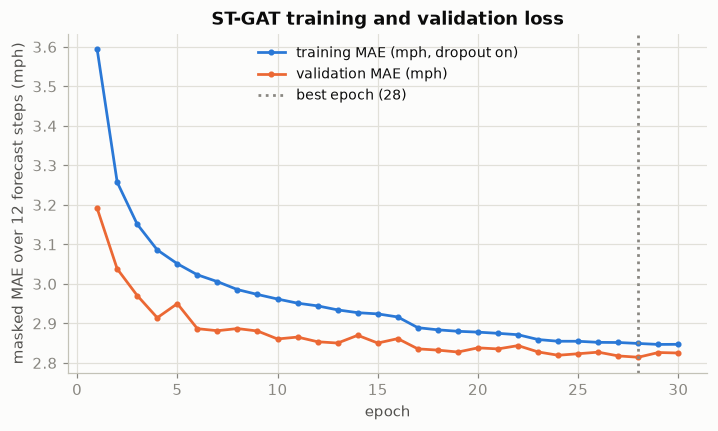

In [7]:
def plot_history(ax, hist, title):
    ep = hist["epoch"]
    ax.plot(ep, np.array(hist["train_loss_scaled"]) * ctx.scaler.std, color="#2a78d6", marker="o", ms=3, label="training MAE (mph, dropout on)")
    ax.plot(ep, hist["val_mae_mph"], color="#eb6834", marker="o", ms=3, label="validation MAE (mph)")
    ax.axvline(hist["best_epoch"], color=viz.INK_MUTED, ls=":", label=f"best epoch ({hist['best_epoch']})")
    ax.set_xlabel("epoch"); ax.set_ylabel("masked MAE over 12 forecast steps (mph)"); ax.set_title(title); ax.legend()

fig, ax = plt.subplots(figsize=(7.5, 4))
plot_history(ax, gat_hist, "ST-GAT training and validation loss")
viz.save_figure(fig, "06_gat_learning_curves"); plt.show()

**Interpretation.** The training and validation curves should decrease together; the dotted line marks the epoch whose weights are
kept. The training MAE is measured with dropout active and averaged over each epoch while the weights change, so it is expected to sit
slightly above or below the validation curve; the two are not strictly comparable.

## 5 · Forecasts at horizons 1, 3, 6, 12 (in mph)

Predictions are produced in scaled units and **inverse-transformed** with the training scaler before they are saved or scored.
Only validation metrics are shown here.

In [8]:
def forecast_and_save(model, key):
    out = {}
    for split, origins in (("val", val_origins), ("test", test_origins)):
        pred = gm.predict_mph(model, data, origins, device, steps=config.HORIZONS)
        assert pred.shape == (len(origins), len(config.HORIZONS), N) and np.isfinite(pred).all()
        # inverse transform check: re-derive from the scaled forecast of the same model
        z = gm.predict_scaled(model, data, origins[:16], device)[:, [h - 1 for h in config.HORIZONS], :]
        assert np.allclose(pred[:16], z * ctx.scaler.std + ctx.scaler.mean, atol=1e-3)
        ev.save_predictions(key, split, pred, origins, config.HORIZONS,
                            {"model": key, "run_mode": config.RUN_MODE, "units": "mph", "target": "speed at origin + h steps"})
        out[split] = pred
    return out

gat_pred = forecast_and_save(gat, "gat")
print({k: v.shape for k, v in gat_pred.items()}, "= [samples, horizons, sensors] in mph")

yv, mv = pp.gather_targets(ctx.speed, ctx.mask, val_origins, config.HORIZONS)
rows = [{"horizon_min": h * 5, **compute_metrics(gat_pred["val"][:, j], yv[:, j], mv[:, j])} for j, h in enumerate(config.HORIZONS)]
print("validation metrics of the ST-GAT:")
display(pd.DataFrame(rows).set_index("horizon_min").round(3))

{'val': (3445, 4, 207), 'test': (6901, 4, 207)} = [samples, horizons, sensors] in mph
validation metrics of the ST-GAT:


,MAE,RMSE,MAPE,n_valid,n_valid_mape
horizon_min,,,,,
5,2.116,3.691,4.960,665707,665705
15,2.513,4.851,6.481,665293,665291
30,2.849,5.796,7.884,664672,664670
60,3.243,6.812,9.502,663840,663838


## 6 · Ablation: the same network without graph edges

`use_graph=False` keeps every layer and the parameter count identical but lets each sensor attend only to **itself**, so the
attention layers collapse to per-sensor linear maps. Any difference from the ST-GAT is therefore attributable to the road
graph, not to model size, capacity or training recipe.

[gat_nograph] reloaded checkpoint gat_nograph.pt; training log of the run that produced it:
epoch   1 | train MAE(scaled) 0.2857 | val MAE 3.3040 mph | lr 2.0e-03 | 104s  *
epoch   2 | train MAE(scaled) 0.2601 | val MAE 3.1341 mph | lr 2.0e-03 | 128s  *
epoch   3 | train MAE(scaled) 0.2508 | val MAE 3.0724 mph | lr 2.0e-03 | 159s  *
epoch   4 | train MAE(scaled) 0.2461 | val MAE 3.0338 mph | lr 2.0e-03 | 168s  *
epoch   5 | train MAE(scaled) 0.2430 | val MAE 3.0479 mph | lr 2.0e-03 | 235s
epoch   6 | train MAE(scaled) 0.2414 | val MAE 3.0095 mph | lr 2.0e-03 | 222s  *
epoch   7 | train MAE(scaled) 0.2398 | val MAE 3.0064 mph | lr 2.0e-03 | 202s  *
epoch   8 | train MAE(scaled) 0.2386 | val MAE 2.9968 mph | lr 2.0e-03 | 216s  *
epoch   9 | train MAE(scaled) 0.2377 | val MAE 3.0044 mph | lr 2.0e-03 | 226s
epoch  10 | train MAE(scaled) 0.2371 | val MAE 3.0009 mph | lr 2.0e-03 | 182s
epoch  11 | train MAE(scaled) 0.2364 | val MAE 2.9880 mph | lr 2.0e-03 | 223s  *
epoch  12 | train MAE(scal

,parameters,best epoch,best validation MAE (mph)
model,,,
ST-GAT (graph),69372,28,2.814
ST-GAT without edges,69372,28,2.952


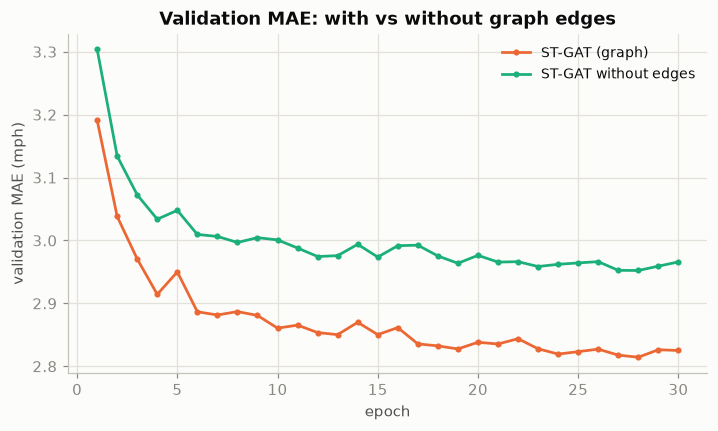

In [9]:
assert gm.count_parameters(gm.build_model(graph.adjacency, params, use_graph=False)) == gm.count_parameters(gat)
if RUN_ABLATION:
    nograph, nograph_hist = fit_or_load("gat_nograph", use_graph=False, seed=params["seed"])
    nograph_pred = forecast_and_save(nograph, "gat_nograph")
    rows = []
    for name, hist in (("ST-GAT (graph)", gat_hist), ("ST-GAT without edges", nograph_hist)):
        rows.append({"model": name, "parameters": hist.get("n_parameters", gm.count_parameters(gat)), "best epoch": hist["best_epoch"],
                     "best validation MAE (mph)": round(hist["best_val_mae_mph"], 3)})
    display(pd.DataFrame(rows).set_index("model"))
    fig, ax = plt.subplots(figsize=(7.5, 4))
    for hist, key, label in ((gat_hist, "gat", "ST-GAT (graph)"), (nograph_hist, "gat_nograph", "ST-GAT without edges")):
        ax.plot(hist["epoch"], hist["val_mae_mph"], color=viz.style(key)["color"], marker="o", ms=3, label=label)
    ax.set_xlabel("epoch"); ax.set_ylabel("validation MAE (mph)"); ax.set_title("Validation MAE: with vs without graph edges"); ax.legend()
    viz.save_figure(fig, "06_gat_vs_nograph_validation"); plt.show()
else:
    print("ablation skipped (RUN_ABLATION = False)")

In [10]:
if RUN_ABLATION:
    g, n_ = np.array(gat_hist["val_mae_mph"]), np.array(nograph_hist["val_mae_mph"])
    k = min(len(g), len(n_))
    gap = 100 * (nograph_hist["best_val_mae_mph"] - gat_hist["best_val_mae_mph"]) / nograph_hist["best_val_mae_mph"]
    below = int((g[:k] < n_[:k]).sum())
    print(f"best validation MAE: with edges {gat_hist['best_val_mae_mph']:.3f} mph, without edges {nograph_hist['best_val_mae_mph']:.3f} mph -> the graph variant is {gap:.1f}% lower")
    print(f"the graph variant has the lower validation MAE in {below} of the {k} epochs both were trained")
    display(ev.report_claims({"the graph variant has the lower best-validation MAE": gap > 0, "it is lower in at least 90% of the epochs": below >= int(0.9 * k)}))

best validation MAE: with edges 2.814 mph, without edges 2.952 mph -> the graph variant is 4.7% lower
the graph variant has the lower validation MAE in 30 of the 30 epochs both were trained


,claim,holds in this run
0,the graph variant has the lower best-validatio...,True
1,it is lower in at least 90% of the epochs,True


**Interpretation (validation period, one training run each).** The two networks are identical except that the second one's attention is restricted to each sensor itself. The version that may use
its road-graph neighbours reaches a lower validation error and stays below the no-edge version through (almost) the whole training, so the gap is not an artefact of picking one epoch. This is
validation evidence from a single seed; the test-period comparison with confidence intervals is in notebook 07.

## 7 · Optional: more seeds

Neural-network results depend on initialisation. If `EXTRA_SEEDS` is non-empty, both models are retrained for each extra seed and saved as
`gat_seed<k>` / `gat_nograph_seed<k>`; notebook 07 reports the spread when those files exist.

In [11]:
for seed in EXTRA_SEEDS:
    for key, use_graph in (("gat", True), ("gat_nograph", False)):
        if key == "gat_nograph" and not RUN_ABLATION:
            continue
        net, hist = fit_or_load(f"{key}_seed{seed}", use_graph, seed)
        forecast_and_save(net, f"{key}_seed{seed}")
        print(f"{key} seed {seed}: best validation MAE {hist['best_val_mae_mph']:.3f} mph")
if not EXTRA_SEEDS:
    print("no extra seeds requested (set EXTRA_SEEDS = (1, 2) to run them)")

[gat_seed1] reloaded checkpoint gat_seed1.pt; training log of the run that produced it:
epoch   1 | train MAE(scaled) 0.2786 | val MAE 3.1868 mph | lr 2.0e-03 | 90s  *
epoch   2 | train MAE(scaled) 0.2551 | val MAE 3.0251 mph | lr 2.0e-03 | 2900s  *
epoch   3 | train MAE(scaled) 0.2463 | val MAE 2.9893 mph | lr 2.0e-03 | 92s  *
epoch   4 | train MAE(scaled) 0.2415 | val MAE 2.9441 mph | lr 2.0e-03 | 91s  *
epoch   5 | train MAE(scaled) 0.2384 | val MAE 2.9273 mph | lr 2.0e-03 | 95s  *
epoch   6 | train MAE(scaled) 0.2362 | val MAE 2.9223 mph | lr 2.0e-03 | 91s  *
epoch   7 | train MAE(scaled) 0.2348 | val MAE 2.9121 mph | lr 2.0e-03 | 85s  *
epoch   8 | train MAE(scaled) 0.2333 | val MAE 2.8737 mph | lr 2.0e-03 | 86s  *
epoch   9 | train MAE(scaled) 0.2321 | val MAE 2.8903 mph | lr 2.0e-03 | 85s
epoch  10 | train MAE(scaled) 0.2312 | val MAE 2.8894 mph | lr 2.0e-03 | 85s
epoch  11 | train MAE(scaled) 0.2304 | val MAE 2.8617 mph | lr 2.0e-03 | 86s  *
epoch  12 | train MAE(scaled) 0.2295

gat seed 1: best validation MAE 2.820 mph
[gat_nograph_seed1] reloaded checkpoint gat_nograph_seed1.pt; training log of the run that produced it:
epoch   1 | train MAE(scaled) 0.2829 | val MAE 3.2864 mph | lr 2.0e-03 | 93s  *
epoch   2 | train MAE(scaled) 0.2603 | val MAE 3.1342 mph | lr 2.0e-03 | 97s  *
epoch   3 | train MAE(scaled) 0.2524 | val MAE 3.1000 mph | lr 2.0e-03 | 91s  *
epoch   4 | train MAE(scaled) 0.2475 | val MAE 3.0463 mph | lr 2.0e-03 | 90s  *
epoch   5 | train MAE(scaled) 0.2443 | val MAE 3.0507 mph | lr 2.0e-03 | 402s
epoch   6 | train MAE(scaled) 0.2423 | val MAE 3.0269 mph | lr 2.0e-03 | 9449s  *
epoch   7 | train MAE(scaled) 0.2411 | val MAE 2.9874 mph | lr 2.0e-03 | 97s  *
epoch   8 | train MAE(scaled) 0.2395 | val MAE 3.0082 mph | lr 2.0e-03 | 99s
epoch   9 | train MAE(scaled) 0.2382 | val MAE 3.0026 mph | lr 2.0e-03 | 103s
epoch  10 | train MAE(scaled) 0.2377 | val MAE 2.9897 mph | lr 1.0e-03 | 87s
epoch  11 | train MAE(scaled) 0.2355 | val MAE 2.9656 mph | lr

gat_nograph seed 1: best validation MAE 2.943 mph
[gat_seed2] reloaded checkpoint gat_seed2.pt; training log of the run that produced it:
epoch   1 | train MAE(scaled) 0.2784 | val MAE 3.2124 mph | lr 2.0e-03 | 94s  *
epoch   2 | train MAE(scaled) 0.2532 | val MAE 3.0365 mph | lr 2.0e-03 | 93s  *
epoch   3 | train MAE(scaled) 0.2448 | val MAE 2.9767 mph | lr 2.0e-03 | 97s  *
epoch   4 | train MAE(scaled) 0.2402 | val MAE 2.9368 mph | lr 2.0e-03 | 92s  *
epoch   5 | train MAE(scaled) 0.2375 | val MAE 2.9361 mph | lr 2.0e-03 | 91s  *
epoch   6 | train MAE(scaled) 0.2356 | val MAE 2.9099 mph | lr 2.0e-03 | 92s  *
epoch   7 | train MAE(scaled) 0.2338 | val MAE 2.8949 mph | lr 2.0e-03 | 91s  *
epoch   8 | train MAE(scaled) 0.2328 | val MAE 2.8865 mph | lr 2.0e-03 | 92s  *
epoch   9 | train MAE(scaled) 0.2315 | val MAE 2.8774 mph | lr 2.0e-03 | 94s  *
epoch  10 | train MAE(scaled) 0.2308 | val MAE 2.8710 mph | lr 2.0e-03 | 93s  *
epoch  11 | train MAE(scaled) 0.2299 | val MAE 2.8885 mph | lr

gat seed 2: best validation MAE 2.807 mph
[gat_nograph_seed2] reloaded checkpoint gat_nograph_seed2.pt; training log of the run that produced it:
epoch   1 | train MAE(scaled) 0.2843 | val MAE 3.3239 mph | lr 2.0e-03 | 96s  *
epoch   2 | train MAE(scaled) 0.2605 | val MAE 3.1473 mph | lr 2.0e-03 | 91s  *
epoch   3 | train MAE(scaled) 0.2516 | val MAE 3.1031 mph | lr 2.0e-03 | 97s  *
epoch   4 | train MAE(scaled) 0.2458 | val MAE 3.0443 mph | lr 2.0e-03 | 93s  *
epoch   5 | train MAE(scaled) 0.2431 | val MAE 3.0335 mph | lr 2.0e-03 | 93s  *
epoch   6 | train MAE(scaled) 0.2412 | val MAE 3.0295 mph | lr 2.0e-03 | 112s  *
epoch   7 | train MAE(scaled) 0.2397 | val MAE 3.0388 mph | lr 2.0e-03 | 127s
epoch   8 | train MAE(scaled) 0.2387 | val MAE 3.0053 mph | lr 2.0e-03 | 115s  *
epoch   9 | train MAE(scaled) 0.2375 | val MAE 3.0014 mph | lr 2.0e-03 | 117s  *
epoch  10 | train MAE(scaled) 0.2370 | val MAE 2.9925 mph | lr 2.0e-03 | 117s  *
epoch  11 | train MAE(scaled) 0.2362 | val MAE 2.999

gat_nograph seed 2: best validation MAE 2.957 mph


## 8 · What does the graph model attend to? (cautious inspection)

We average the attention weights of the first block over a sample of **validation** origins and compare them with the uniform
weights a model with no preference would use (1 / number of neighbours). **Attention weights show how the trained network mixes neighbour
representations; they are not causal evidence that one sensor "causes" congestion at another.**

In [12]:
masks_np = gu.neighbor_masks(graph.adjacency)
sample_origins = pp.evenly_spaced(val_origins, 256)
att_sum = {"in": 0.0, "out": 0.0}; n_seen = 0
gat.eval()
with torch.no_grad():
    for i in range(0, len(sample_origins), 64):
        xb, ab, _, _ = data.batch(sample_origins[i:i + 64], device)
        _, atts = gat(xb, ab, return_attention=True)
        att_sum["in"] = att_sum["in"] + atts[0][0].float().mean(-1).sum(0).cpu().numpy()     # head-averaged, [N, N] (target i, source j)
        att_sum["out"] = att_sum["out"] + atts[0][1].float().mean(-1).sum(0).cpu().numpy()
        n_seen += xb.shape[0]
mean_att = {k: v / n_seen for k, v in att_sum.items()}

rows = []
for name in ("in", "out"):
    m, a = masks_np[name], mean_att[name]
    n_nb = m.sum(1)
    self_att = np.diag(a)
    rows.append({"direction": name, "mean attention on itself": self_att.mean(), "uniform value (1 / neighbourhood size)": (1 / n_nb).mean(),
                 "share of nodes with self-attention above uniform": float((self_att > 1 / n_nb).mean()),
                 "mean neighbourhood size (incl. self)": n_nb.mean()})
display(pd.DataFrame(rows).set_index("direction").round(3))

# How selective is the attention? normalised entropy per sensor: 1 = uniform over its neighbourhood, 0 = all weight on one neighbour
sel_rows = []
for name in ("in", "out"):
    m, a = masks_np[name], mean_att[name]
    ent, ratio = [], []
    for i in range(N):
        nb_idx = np.flatnonzero(m[i])
        if len(nb_idx) < 3:
            continue
        w = a[i, nb_idx] / a[i, nb_idx].sum()
        ent.append(float(-(w * np.log(w + 1e-12)).sum() / np.log(len(nb_idx)))); ratio.append(float(w.max() * len(nb_idx)))
    sel_rows.append({"direction": name, "sensors with >= 3 neighbours": len(ent), "mean normalised entropy (1 = uniform)": np.mean(ent),
                     "share of sensors with entropy < 0.9": float(np.mean(np.array(ent) < 0.9)), "mean (largest weight / uniform weight)": np.mean(ratio)})
selectivity = pd.DataFrame(sel_rows).set_index("direction")
display(selectivity.round(3))
ent_mean = selectivity["mean normalised entropy (1 = uniform)"]
display(ev.report_claims({
    "mean normalised attention entropy is between 0.85 and 1 (mildly selective) in both directions": bool(((ent_mean > 0.85) & (ent_mean < 1.0)).all()),
    "the largest attention weight is on average > 1.2x the uniform weight": bool((selectivity["mean (largest weight / uniform weight)"] > 1.2).all()),
    "a few sensors are strongly selective (entropy < 0.9)": bool((selectivity["share of sensors with entropy < 0.9"] > 0).all()),
}))

,mean attention on itself,uniform value (1 / neighbourhood size),share of nodes with self-attention above uniform,mean neighbourhood size (incl. self)
direction,,,,
in,0.175,0.169,0.449,8.319
out,0.175,0.175,0.483,8.319


,sensors with >= 3 neighbours,mean normalised entropy (1 = uniform),share of sensors with entropy < 0.9,mean (largest weight / uniform weight)
direction,,,,
in,191,0.960,0.016,1.803
out,193,0.974,0.010,1.652


,claim,holds in this run
0,mean normalised attention entropy is between 0...,True
1,the largest attention weight is on average > 1...,True
2,a few sensors are strongly selective (entropy ...,True


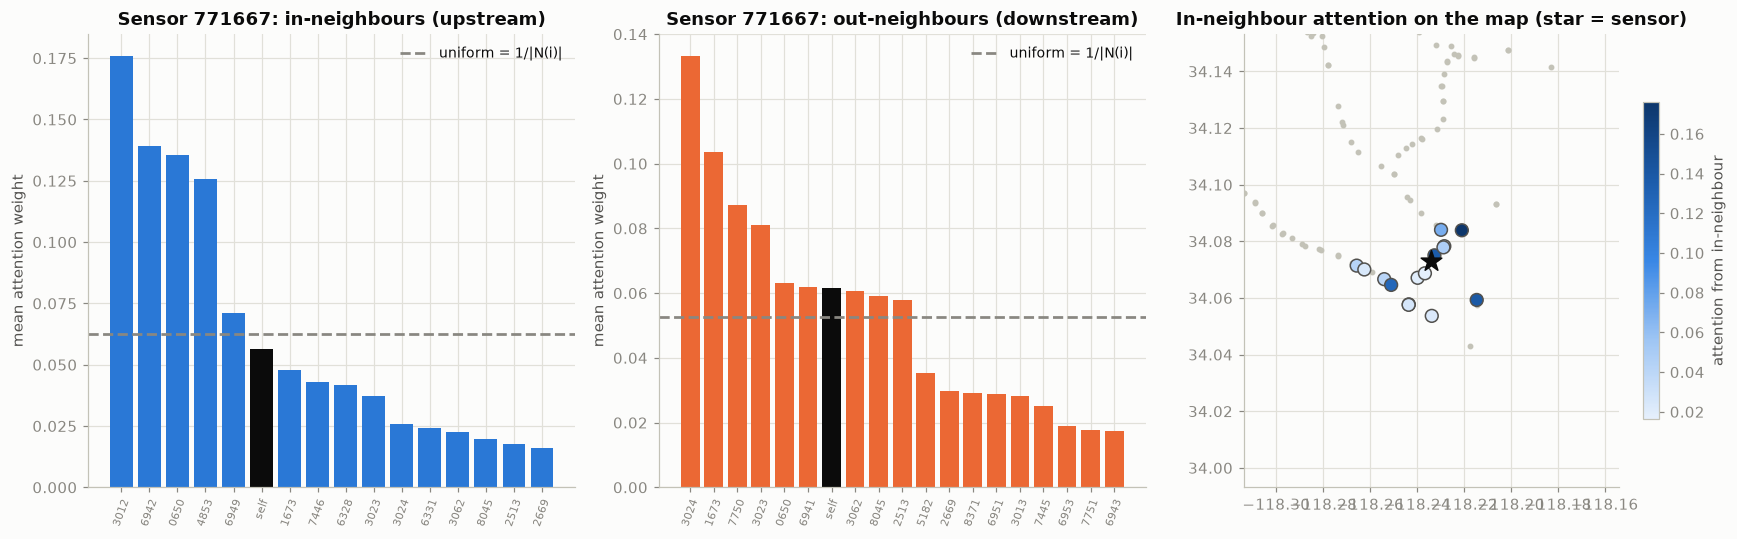

In [13]:
# Attention of one well-connected sensor, averaged over the validation sample
deg = (masks_np["in"].sum(1) + masks_np["out"].sum(1))
hub = int(np.argmax(deg))
loc = graph.locations
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, name, ttl in ((axes[0], "in", "in-neighbours (upstream)"), (axes[1], "out", "out-neighbours (downstream)")):
    w = mean_att[name][hub]; nb_idx = np.flatnonzero(masks_np[name][hub])
    order = nb_idx[np.argsort(-w[nb_idx])]
    ax.bar(range(len(order)), w[order], color=["#0b0b0b" if j == hub else ("#2a78d6" if name == "in" else "#eb6834") for j in order])
    ax.axhline(1 / len(nb_idx), color=viz.INK_MUTED, ls="--", label="uniform = 1/|N(i)|")
    ax.set_xticks(range(len(order)), [("self" if j == hub else graph.sensor_ids[j][-4:]) for j in order], rotation=70, fontsize=7)
    ax.set_ylabel("mean attention weight"); ax.set_title(f"Sensor {graph.sensor_ids[hub]}: {ttl}"); ax.legend()
lon, lat = loc["longitude"].to_numpy(), loc["latitude"].to_numpy()
axes[2].scatter(lon, lat, s=8, color="#c3c2b7")
w_in = mean_att["in"][hub]; nbs = [j for j in np.flatnonzero(masks_np["in"][hub]) if j != hub]
sc = axes[2].scatter(lon[nbs], lat[nbs], c=w_in[nbs], cmap=viz.SPEED_CMAP.reversed(), s=70, edgecolor=viz.INK_2, zorder=3)
axes[2].scatter(lon[hub], lat[hub], marker="*", s=200, color=viz.INK, zorder=4)
axes[2].set_xlim(lon[hub] - 0.08, lon[hub] + 0.08); axes[2].set_ylim(lat[hub] - 0.08, lat[hub] + 0.08)
axes[2].set_aspect(1 / np.cos(np.deg2rad(lat.mean()))); plt.colorbar(sc, ax=axes[2], shrink=0.7, label="attention from in-neighbour")
axes[2].set_title("In-neighbour attention on the map (star = sensor)")
fig.tight_layout(); viz.save_figure(fig, "06_gat_attention_hub"); plt.show()

**Interpretation (cautious).**

* *On average the attention is only mildly selective.* The attention a sensor pays to itself is close to the uniform value (first table), and the normalised entropy over each sensor's neighbours is close to 1 (second table; 1 = perfectly uniform; checked in code):
  the largest weight is on average only about 1.5-2x the uniform weight, and only a small share of sensors is strongly selective.
* *A few sensors are strongly selective.* The hub shown above (the most connected sensor, chosen for its connectivity, **not** because it is typical) concentrates weight on a handful of neighbours and clearly differs from the uniform line.
* So the gain of the graph model over the no-edge ablation should **not** be explained as "sharply picking the right neighbour" for most sensors; it may come largely from mixing neighbour information with only modest re-weighting. That explanation is a hypothesis we did not test.
* These weights are averages over many time steps of a learned, non-causal mixing step (the graph block sits on top of a recurrent encoder and a residual path); we do not read them as influence, flow or causation between roads.
* Whether the graph helps forecasting is answered by the ablation and by the test-set comparison in notebook 07, not by this plot.

## 9 · Summary of this notebook

In [14]:
rows = [{"model": "ST-GAT (graph)", "parameters": f"{gm.count_parameters(gat):,}", "best epoch": gat_hist["best_epoch"],
         "best val MAE (mph)": round(gat_hist["best_val_mae_mph"], 3), "checkpoint": paths("gat")[0].name}]
if RUN_ABLATION:
    rows.append({"model": "ST-GAT without edges", "parameters": f"{gm.count_parameters(nograph):,}", "best epoch": nograph_hist["best_epoch"],
                 "best val MAE (mph)": round(nograph_hist["best_val_mae_mph"], 3), "checkpoint": paths("gat_nograph")[0].name})
display(pd.DataFrame(rows).set_index("model"))
saved = sorted({p.name for p in config.PREDICTIONS_DIR.glob(f"{config.tagged('gat')}*__*.npz")})
print("prediction files:", saved)
if config.IS_SMOKE:
    print("\n*** SMOKE RUN: these numbers come from a tiny debug configuration and are NOT experimental results. ***")
print("\nNext: 07_model_evaluation.ipynb (after notebooks 04 and 05 have produced the baseline / XGBoost predictions)")

,parameters,best epoch,best val MAE (mph),checkpoint
model,,,,
ST-GAT (graph),"69,372",28,2.814,gat.pt
ST-GAT without edges,"69,372",28,2.952,gat_nograph.pt


prediction files: ['gat__test.npz', 'gat__val.npz', 'gat_nograph__test.npz', 'gat_nograph__val.npz', 'gat_nograph_seed1__test.npz', 'gat_nograph_seed1__val.npz', 'gat_nograph_seed2__test.npz', 'gat_nograph_seed2__val.npz', 'gat_seed1__test.npz', 'gat_seed1__val.npz', 'gat_seed2__test.npz', 'gat_seed2__val.npz']

Next: 07_model_evaluation.ipynb (after notebooks 04 and 05 have produced the baseline / XGBoost predictions)


---
---
# Section: `06b_optional_dcrnn`

# 06b · Optional: DCRNN-style comparison

> **Optional extension.** It does not affect the primary results (notebooks 04-07 stand without it). If this notebook is not run, notebook 07 simply reports DCRNN as *not available*.

**Objective.** Add a second graph-based model from the literature, the **Diffusion Convolutional Recurrent Neural Network** (DCRNN, Li et al., ICLR 2018), as a point of comparison for the ST-GAT.

**What this is, and is not.**
* The original implementation is TensorFlow 1 code with obsolete dependencies; installing it into this environment would break the project's modern stack. Instead, `src/dcrnn_model.py` is a **clean PyTorch re-implementation of the idea**: a sequence-to-sequence model whose GRU cells use *diffusion convolutions* over the directed road graph (forward and backward random walks).
* It is **not a port** and has **not been verified to be numerically equivalent** to the original. We make no claim about reproducing the published numbers.
* Differences (documented in the module): plain powers of the random-walk matrices; the decoder starts from the same anchor (last observed speed) and predicts residuals like our other learned models; calendar features of the target time as decoder input; a smaller training budget (stride-3 training windows, at most 30 epochs, linear teacher-forcing decay).

**Methodology.** Same data, split, scaler, windows, masked-MAE loss, validation early stopping and evaluation as the ST-GAT. Only the model differs.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, gat_model as gm, dcrnn_model as dm, evaluation as ev, visualization as viz
from src.metrics import compute_metrics

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)
N, HZ = len(ctx.sensor_ids), config.HORIZONS
device = gm.select_device()
RETRAIN = False                    # True: retrain from scratch (about 1 h per seed on an Apple M3); False: reload saved checkpoints if they exist
EXTRA_SEEDS = (1, 2)               # additional seeds (each saved as dcrnn_seed<k>); () = seed 42 only
params = dict(config.DCRNN_PARAMS)
print("device:", device, "| hyper-parameters:", params)

device: mps | hyper-parameters: {'hidden': 64, 'n_layers': 2, 'k_hops': 2, 'batch_size': 16, 'lr': 0.002, 'weight_decay': 1e-05, 'max_epochs': 30, 'patience': 6, 'grad_clip': 5.0, 'train_stride': 3, 'train_origin_limit': None, 'seed': 42}


## 1 · Diffusion supports from the directed graph

Forward walk `D_O^-1 W` (where traffic goes next) and backward walk `D_I^-1 W^T` (where it came from). Self-loops are removed from `W`; a sensor without out- (or in-) edges has an all-zero row, so it only keeps its own state.

In [3]:
fwd, bwd = dm.random_walk_supports(graph.adjacency)
for name, s in (("forward  D_O^-1 W", fwd), ("backward D_I^-1 W^T", bwd)):
    sums = s.sum(1)
    print(f"{name}: shape {s.shape}, rows summing to 1: {int(np.isclose(sums, 1).sum())}, all-zero rows: {int((sums == 0).sum())}, non-zeros {int((s > 0).sum())}")
    assert np.isfinite(s).all() and set(np.round(sums[sums > 0], 5)) == {1.0}

forward  D_O^-1 W: shape (207, 207), rows summing to 1: 202, all-zero rows: 5, non-zeros 1515
backward D_I^-1 W^T: shape (207, 207), rows summing to 1: 205, all-zero rows: 2, non-zeros 1515


## 2 · Model, tensors and training data

In [4]:
data = gm.GraphData(speed=ctx.speed, mask=ctx.mask, values_scaled=pp.fill_for_model(ctx.speed, ctx.mask, ctx.scaler), time_feats=pp.time_feature_matrix(ctx.timestamps),
                    locf_value=ctx.locf_value, locf_age=ctx.locf_age, scaler=ctx.scaler)
train_origins = pp.evenly_spaced(ctx.origins["train"][::params["train_stride"]], params["train_origin_limit"])
val_origins, test_origins = ctx.origins["val"], ctx.origins["test"]
gm.set_seed(params["seed"])
model = dm.DCRNN(graph.adjacency, in_features=6, hidden=params["hidden"], n_layers=params["n_layers"], k_hops=params["k_hops"])
print(f"parameters: {gm.count_parameters(model):,} | training origins used: {len(train_origins):,} (of {len(ctx.origins['train']):,}) | validation origins: {len(val_origins):,}")

x, anchor, y, valid = data.batch(train_origins[:2], torch.device("cpu"))
dec = dm.decoder_features(data, train_origins[:2], torch.device("cpu"))
model.eval()
with torch.no_grad():
    out = model(x, anchor, dec)
print(f"encoder input {tuple(x.shape)}, decoder calendar features {tuple(dec.shape)} -> prediction {tuple(out.shape)} = [batch, 12 steps, 207 sensors] (scaled)")
assert out.shape == (2, 12, N) and torch.isfinite(out).all()

parameters: 380,033 | training origins used: 7,961 (of 23,881) | validation origins: 3,445
encoder input (2, 12, 207, 6), decoder calendar features (2, 12, 207, 4) -> prediction (2, 12, 207) = [batch, 12 steps, 207 sensors] (scaled)


## 3 · Training (masked MAE; validation early stopping; test untouched)

> **Provenance of the delivered run.** The model was trained once in an earlier execution (up to 30 epochs of ~2 minutes each on an Apple M3, patience 6; training is deterministic). With `RETRAIN = False`, as delivered, the saved checkpoint is reloaded and its original training log is printed; forecasts and scores are recomputed. Whether training ended by early stopping or by the epoch limit is printed in the training log below.

reloaded dcrnn.pt - training log of the run that produced it:
epoch   1 | train MAE(scaled) 0.2376 | val MAE 3.4416 mph | tf 0.50 | 122s  *
epoch   2 | train MAE(scaled) 0.2043 | val MAE 3.3215 mph | tf 0.47 | 128s  *
epoch   3 | train MAE(scaled) 0.2030 | val MAE 3.2622 mph | tf 0.44 | 131s  *
epoch   4 | train MAE(scaled) 0.2014 | val MAE 3.1274 mph | tf 0.42 | 127s  *
epoch   5 | train MAE(scaled) 0.2001 | val MAE 3.1370 mph | tf 0.39 | 130s
epoch   6 | train MAE(scaled) 0.1994 | val MAE 3.0298 mph | tf 0.36 | 131s  *
epoch   7 | train MAE(scaled) 0.1996 | val MAE 3.0184 mph | tf 0.33 | 130s  *
epoch   8 | train MAE(scaled) 0.2000 | val MAE 3.0148 mph | tf 0.31 | 134s  *
epoch   9 | train MAE(scaled) 0.2017 | val MAE 2.9517 mph | tf 0.28 | 134s  *
epoch  10 | train MAE(scaled) 0.2034 | val MAE 2.9001 mph | tf 0.25 | 132s  *
epoch  11 | train MAE(scaled) 0.2102 | val MAE 3.1660 mph | tf 0.22 | 133s
epoch  12 | train MAE(scaled) 0.2156 | val MAE 3.0555 mph | tf 0.19 | 134s
epoch  13 |

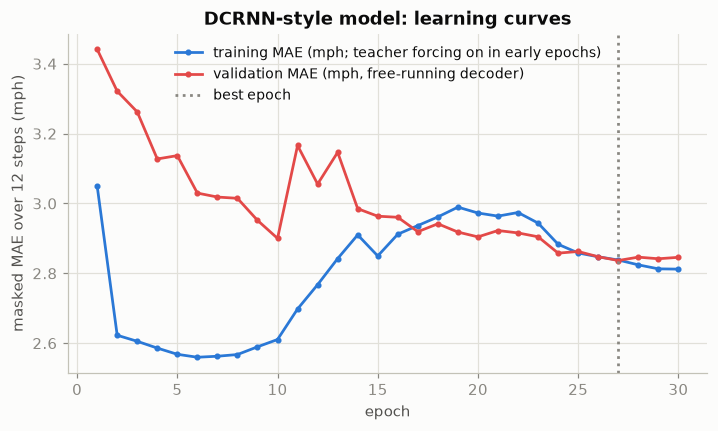

In [5]:
ckpt = config.MODELS_DIR / f"{config.tagged('dcrnn')}.pt"
hist_path = config.METRICS_DIR / f"{config.tagged('dcrnn')}_history.json"
log_path = config.METRICS_DIR / f"{config.tagged('dcrnn')}_train.log"
if not RETRAIN and ckpt.is_file() and hist_path.is_file():
    gm.load_checkpoint(ckpt, model.to(device), device); hist = json.loads(hist_path.read_text())
    print("reloaded", ckpt.name, "- training log of the run that produced it:")
    print(log_path.read_text() if log_path.is_file() else "(log file not found)")
else:
    t0 = time.time()
    with open(log_path, "w") as lf:
        def log(msg):
            print(msg); lf.write(msg + "\n"); lf.flush()
        hist = dm.train_dcrnn(model, data, train_origins, val_origins, device, params, ckpt, log=log)
    hist["train_seconds"] = time.time() - t0; hist["n_parameters"] = gm.count_parameters(model); hist["run_mode"] = config.RUN_MODE
    hist_path.write_text(json.dumps(hist, indent=2))
print(f"DCRNN-style model: best epoch {hist['best_epoch']} | best validation MAE {hist['best_val_mae_mph']:.3f} mph | {hist.get('train_seconds', float('nan')) / 60:.1f} min")
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(hist["epoch"], np.array(hist["train_loss_scaled"]) * ctx.scaler.std, color="#2a78d6", marker="o", ms=3, label="training MAE (mph; teacher forcing on in early epochs)")
ax.plot(hist["epoch"], hist["val_mae_mph"], color=viz.style("dcrnn")["color"], marker="o", ms=3, label="validation MAE (mph, free-running decoder)")
ax.axvline(hist["best_epoch"], color=viz.INK_MUTED, ls=":", label="best epoch"); ax.set_xlabel("epoch"); ax.set_ylabel("masked MAE over 12 steps (mph)")
ax.set_title("DCRNN-style model: learning curves"); ax.legend(); viz.save_figure(fig, "06b_dcrnn_learning_curves"); plt.show()

## 4 · Forecasts and validation comparison

Predictions are saved in the standard layout (mph, horizons 1/3/6/12) as model `dcrnn`; only **validation** metrics are shown here.

In [6]:
saved = {}
for split, origins in (("val", val_origins), ("test", test_origins)):
    pred = dm.predict_mph(model, data, origins, device, steps=HZ)
    assert pred.shape == (len(origins), len(HZ), N) and np.isfinite(pred).all()
    ev.save_predictions("dcrnn", split, pred, origins, HZ, {"model": "dcrnn", "run_mode": config.RUN_MODE, "units": "mph", "note": "PyTorch re-implementation, not the original code"})
    saved[split] = pred
yv, mv = pp.gather_targets(ctx.speed, ctx.mask, val_origins, HZ)
val_preds = {"dcrnn": ev.clip_predictions(saved["val"])}
for other in ("persistence", "xgboost", "gat"):
    try:
        d = ev.load_predictions(other, "val")
        if np.array_equal(d["origins"], val_origins):
            val_preds[other] = d["pred"]
    except FileNotFoundError:
        print(f"({other} validation predictions not available yet)")
valid = ev.common_valid_mask(val_preds, mv)
tab = ev.metrics_by_horizon(val_preds, yv, valid, HZ)
display(tab.pivot(index="model", columns="horizon_min", values=["MAE", "RMSE"]).round(2))
print("The test-period comparison (all models, identical rules) is in notebook 07.")
if config.IS_SMOKE:
    print("*** SMOKE RUN: not final results ***")

MAE                    RMSE                  
horizon_min    5     15    30    60    5     15    30    60
model                                                      
dcrnn        2.15  2.54  2.86  3.26  3.72  4.92  5.88  6.87
gat          2.12  2.51  2.85  3.24  3.69  4.85  5.80  6.81
persistence  2.64  3.24  3.84  4.84  4.38  6.03  7.54  9.67
xgboost      2.16  2.64  3.05  3.50  3.83  5.26  6.29  7.22

The test-period comparison (all models, identical rules) is in notebook 07.


## 5 · Extra seeds

The same model and budget trained with further seeds (`EXTRA_SEEDS`), saved as `dcrnn_seed<k>`; notebook 07 reports the seed spread. Each seed is reloaded if its checkpoint exists.

In [7]:
seed_rows = [{"run": "dcrnn (seed 42)", "best epoch": hist["best_epoch"], "best validation MAE (mph)": hist["best_val_mae_mph"]}]
for seed in EXTRA_SEEDS:
    key = f"dcrnn_seed{seed}"
    ck = config.MODELS_DIR / f"{config.tagged(key)}.pt"; hp = config.METRICS_DIR / f"{config.tagged(key)}_history.json"; lp = config.METRICS_DIR / f"{config.tagged(key)}_train.log"
    gm.set_seed(seed)
    net = dm.DCRNN(graph.adjacency, in_features=6, hidden=params["hidden"], n_layers=params["n_layers"], k_hops=params["k_hops"])
    if not RETRAIN and ck.is_file() and hp.is_file():
        gm.load_checkpoint(ck, net.to(device), device); h_ = json.loads(hp.read_text())
        print(f"[{key}] reloaded; training log:"); print(lp.read_text() if lp.is_file() else "(log not found)")
    else:
        t0 = time.time()
        with open(lp, "w") as lf:
            def log(msg):
                print(msg); lf.write(msg + "\n"); lf.flush()
            h_ = dm.train_dcrnn(net, data, train_origins, val_origins, device, dict(params, seed=seed), ck, log=log)
        h_["train_seconds"] = time.time() - t0; h_["seed"] = seed
        hp.write_text(json.dumps(h_, indent=2))
    for split, origins in (("val", val_origins), ("test", test_origins)):
        pred = dm.predict_mph(net, data, origins, device, steps=HZ)
        assert pred.shape == (len(origins), len(HZ), N) and np.isfinite(pred).all()
        ev.save_predictions(key, split, pred, origins, HZ, {"model": key, "seed": seed, "units": "mph"})
    seed_rows.append({"run": key, "best epoch": h_["best_epoch"], "best validation MAE (mph)": h_["best_val_mae_mph"]})
display(pd.DataFrame(seed_rows).set_index("run").round(3))

epoch   1 | train MAE(scaled) 0.2392 | val MAE 3.4796 mph | tf 0.50 | 136s  *


epoch   2 | train MAE(scaled) 0.2060 | val MAE 3.3077 mph | tf 0.47 | 133s  *


epoch   3 | train MAE(scaled) 0.2018 | val MAE 3.2278 mph | tf 0.44 | 134s  *


epoch   4 | train MAE(scaled) 0.2012 | val MAE 3.1597 mph | tf 0.42 | 130s  *


epoch   5 | train MAE(scaled) 0.1997 | val MAE 3.1802 mph | tf 0.39 | 137s


epoch   6 | train MAE(scaled) 0.1992 | val MAE 3.0574 mph | tf 0.36 | 136s  *


... (45 outputs left out)

epoch  28 | train MAE(scaled) 0.2155 | val MAE 2.8170 mph | tf 0.00 | 147s  *


epoch  29 | train MAE(scaled) 0.2148 | val MAE 2.8469 mph | tf 0.00 | 138s


epoch  30 | train MAE(scaled) 0.2139 | val MAE 2.8223 mph | tf 0.00 | 141s


,best epoch,best validation MAE (mph)
run,,
dcrnn (seed 42),27,2.837
dcrnn_seed1,9,2.914
dcrnn_seed2,28,2.817


---
---
# Section: `07_model_evaluation`

# 07 · Rigorous model evaluation

**Objective.** Compare every model on the **same test period, horizons, targets and rules**, answer the research question
*"does using the road graph improve multi-step forecasting compared with treating sensors independently?"*, and look at where the answer holds or fails
(peak vs off-peak, sensor by sensor).

**Inputs.** Saved test predictions of persistence, rolling mean, seasonal average, XGBoost, ST-GAT, the no-edge ST-GAT ablation and, if it was run, DCRNN.
**A model without a prediction file is reported as missing; its metrics are never invented.**

**Metrics** (`src/metrics.py`). A point is valid if its true speed was observed and every compared model produced a finite forecast
(*common valid mask*).
* **MAE** = mean(|ŷ − y|), **RMSE** = sqrt(mean((ŷ − y)²)), both in mph, pooled over all valid (sample, sensor) points of a horizon.
* **MAPE** = 100·mean(|ŷ − y| / y) in %, only for true speeds ≥ 1 mph (near-zero policy); `n_valid_mape` is reported next to it.
* Predictions of every model are clipped to the physical range 0-70 mph before scoring (identical rule for all).
* **Improvement of model B over model A** = `100 × (error_A − error_B) / error_A`. **Positive means B has the lower error (B is better).**
  Confidence intervals come from a **day-block bootstrap** (whole days resampled, 2,000 draws), because errors within a day are strongly correlated.

**Peak vs off-peak** were defined *before* any model ran (`config.PEAK_WINDOWS`): weekdays 07:00-10:00 and 15:00-19:00, judged on the **forecast target time**,
assuming timestamps are Pacific local time (notebook 01). Everything else (other weekday hours and all weekend hours) is off-peak.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, evaluation as ev, visualization as viz
from src.metrics import compute_metrics, improvement_pct

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)
N, HZ = len(ctx.sensor_ids), config.HORIZONS
if config.IS_SMOKE:
    print("*** SMOKE RUN - evaluating tiny debug predictions; do not report these numbers ***")

## 1 · Load and align the predictions

In [3]:
CANDIDATES = ["persistence", "rolling_mean", "seasonal_avg", "xgboost", "xgboost_spatial", "gat_nograph", "gat", "dcrnn"]
preds, y, ymask, origins, horizons, missing_models = ev.load_aligned(CANDIDATES, "test", ctx.speed, ctx.mask)
MODELS = [m for m in CANDIDATES if m in preds]

print("models evaluated :", MODELS)
print("models NOT available (no prediction file; reported as missing, nothing invented):", missing_models or "none")
assert np.array_equal(origins, ctx.origins["test"]) and horizons == HZ, "predictions do not use the shared test origins/horizons"
valid = ev.common_valid_mask({m: preds[m] for m in MODELS}, ymask)
print(f"test samples: {len(origins):,} origins x {len(HZ)} horizons x {N} sensors = {valid.size:,} cells")
print(f"observed targets: {int(ymask.sum()):,} ({ymask.mean():.1%}) | valid for ALL models: {int(valid.sum()):,} ({valid.mean():.1%})")
display(pd.DataFrame({m: {"finite predictions": f"{np.isfinite(preds[m]).mean():.2%}", "min (mph)": float(np.nanmin(preds[m])), "max (mph)": float(np.nanmax(preds[m]))} for m in MODELS}).T.round(2))

models evaluated : ['persistence', 'rolling_mean', 'seasonal_avg', 'xgboost', 'xgboost_spatial', 'gat_nograph', 'gat', 'dcrnn']
models NOT available (no prediction file; reported as missing, nothing invented): none
test samples: 6,901 origins x 4 horizons x 207 sensors = 5,714,028 cells
observed targets: 5,026,522 (88.0%) | valid for ALL models: 5,026,522 (88.0%)


,finite predictions,min (mph),max (mph)
persistence,100.00%,0.75,70.0
rolling_mean,100.00%,1.0,70.0
seasonal_avg,100.00%,4.786616,70.0
xgboost,100.00%,0.167528,70.0
xgboost_spatial,100.00%,0.0,70.0
gat_nograph,100.00%,0.0,70.0
gat,100.00%,0.0,70.0
dcrnn,100.00%,0.0,70.0


In [4]:
# Fairness checklist - everything programmatically verifiable is asserted
meta = {}
for m in MODELS:
    d = ev.load_predictions(m, "test")
    meta[m] = d["meta"]
hist_path = lambda k: config.METRICS_DIR / f"{config.tagged(k)}_history.json"
xgb_hp = config.MODELS_DIR / f"{config.tagged('xgb')}_hyperparameters.json"
gat_hist = json.loads(hist_path("gat").read_text()) if hist_path("gat").is_file() else None
table_check = ev.metrics_by_horizon({m: preds[m] for m in MODELS}, y, valid, HZ)
checks = {
    "same chronological test period (all models use the identical origins)": all(np.array_equal(ev.load_predictions(m, "test")["origins"], origins) for m in MODELS),
    "same forecast horizons": all(ev.load_predictions(m, "test")["horizons"] == HZ for m in MODELS),
    "same target variables (one `y` gathered from the observed speeds at origin + h)": y.shape == (len(origins), len(HZ), N),
    "test targets lie inside the test period": int((origins + max(HZ)).max()) < ctx.splits.test[1] and int((origins + 1).min()) >= ctx.splits.test[0],
    "common valid mask only contains observed targets (missing targets are never scored)": int((valid & ~ymask).sum()) == 0,
    "every model is scored on exactly the same number of points at each horizon": bool((table_check.groupby("horizon_steps")["n_valid"].nunique() == 1).all()),
    "XGBoost fit record shows early stopping on a non-empty validation set": ("xgboost" in missing_models) or (xgb_hp.is_file() and all(v["val_rows"] > 0 and v["best_iteration"] <= int(config.XGB_PARAMS["n_estimators"]) for v in json.loads(xgb_hp.read_text())["fit_info"].values())),
    "ST-GAT kept the epoch with the lowest VALIDATION MAE": ("gat" in missing_models) or (gat_hist is not None and gat_hist["best_epoch"] == int(np.argmin(gat_hist["val_mae_mph"])) + 1),
    "run mode is the full run (not a smoke test)": not config.IS_SMOKE,
}
display(pd.DataFrame({"fairness requirement": list(checks), "verified": ["yes" if v else "NO" for v in checks.values()]}))
assert all(v for k, v in checks.items() if "full run" not in k), "fairness check failed"
print("Guaranteed by construction rather than checked here: every model is scored by the same functions (src/metrics.py, src/evaluation.py) with the same clipping;")
print("no future information in the features (asserted in notebook 02 and tests/test_splits.py); all learned models read the same 12-step window (config.INPUT_LEN);")
print("the baselines have no tuned parameters.")

,fairness requirement,verified
0,same chronological test period (all models use...,yes
1,same forecast horizons,yes
2,same target variables (one `y` gathered from t...,yes
3,test targets lie inside the test period,yes
4,common valid mask only contains observed targe...,yes
5,every model is scored on exactly the same numb...,yes
6,XGBoost fit record shows early stopping on a n...,yes
7,ST-GAT kept the epoch with the lowest VALIDATI...,yes
8,run mode is the full run (not a smoke test),yes


Guaranteed by construction rather than checked here: every model is scored by the same functions (src/metrics.py, src/evaluation.py) with the same clipping;
no future information in the features (asserted in notebook 02 and tests/test_splits.py); all learned models read the same 12-step window (config.INPUT_LEN);
the baselines have no tuned parameters.


## 2 · Main metrics table (test period)

In [5]:
table = ev.metrics_by_horizon({m: preds[m] for m in MODELS}, y, valid, HZ)
table.to_csv(config.METRICS_DIR / f"{config.tagged('test_metrics_by_horizon')}.csv", index=False)
labels = {m: viz.style(m)["label"] for m in MODELS}
wide = table.pivot(index="model", columns="horizon_min", values=["MAE", "RMSE", "MAPE"]).reindex(MODELS)
wide.index = [labels[m] for m in wide.index]
display(wide.round(2))
print("valid points per horizon (identical for every model, by construction of the common mask):")
display(table[table.model == MODELS[0]][["horizon_min", "n_valid", "n_valid_mape"]].set_index("horizon_min").T)

MAE                    RMSE              \
horizon_min                        5     15    30    60    5     15    30   
Persistence                      2.82  3.49  4.19  5.35  4.61  6.38  7.98   
Rolling mean (60 min)            3.44  3.92  4.55  5.66  6.52  7.58  8.85   
Seasonal average                 4.18  4.18  4.18  4.18  7.83  7.83  7.83   
XGBoost                          2.30  2.83  3.25  3.66  4.04  5.54  6.57   
XGBoost + neighbour features     2.22  2.74  3.16  3.60  3.81  5.24  6.28   
ST-GAT without edges (ablation)  2.31  2.81  3.19  3.56  4.06  5.51  6.53   
ST-GAT                           2.26  2.70  3.05  3.47  3.91  5.13  6.07   
DCRNN (optional)                 2.31  2.76  3.14  3.59  3.96  5.26  6.30   

                                         MAPE                       
horizon_min                         60     5      15     30     60  
Persistence                      10.25   6.47   8.57  10.79  14.42  
Rolling mean (60 min)            10.80   9.11  10.59  12.55  15.96  
Seasonal average                  7.83  12.97  12.97  12.97  12.97  
XGBoost                           7.44   5.63   7.59   9.47  11.40  
XGBoost + neighbour features      7.21   5.29   7.26   9.06  11.01  
ST-GAT without edges (ablation)   7.49   5.68   7.59   9.23  10.76  
ST-GAT                            7.14   5.43   7.03   8.47  10.18  
DCRNN (optional)                  7.39   5.46   7.09   8.65  10.50

valid points per horizon (identical for every model, by construction of the common mask):


horizon_min,5,15,30,60
n_valid,1256654,1256644,1256629,1256595
n_valid_mape,1256652,1256642,1256627,1256593


In [6]:
best = table.loc[table.groupby("horizon_min")["MAE"].idxmin(), ["horizon_min", "model", "MAE"]].set_index("horizon_min")
best["model"] = best["model"].map(labels)
print("lowest test MAE per horizon:"); display(best.round(2))

lowest test MAE per horizon:


,model,MAE
horizon_min,,
5,XGBoost + neighbour features,2.22
15,ST-GAT,2.70
30,ST-GAT,3.05
60,ST-GAT,3.47


## 3 · Error versus forecast horizon

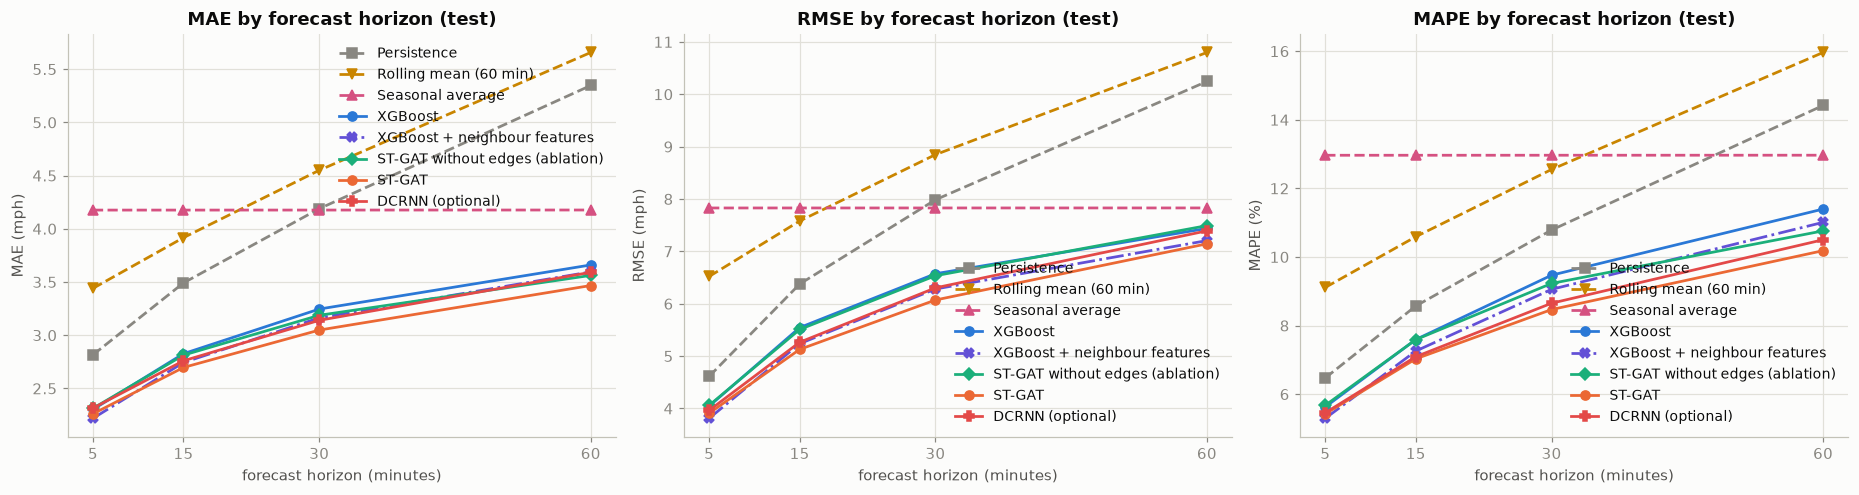

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, metric in zip(axes, ("MAE", "RMSE", "MAPE")):
    viz.plot_metric_vs_horizon(ax, table, metric, MODELS, title=f"{metric} by forecast horizon (test)")
fig.tight_layout(); viz.save_figure(fig, "07_metrics_vs_horizon"); plt.show()

**Reading the figure.** Every model's error grows with the horizon except the seasonal average, which is horizon-independent. The ordering of the
learned models relative to the baselines at each horizon is in the table above; the statistical comparison of the graph model with XGBoost follows.

## 4 · Does the graph help? Improvement of ST-GAT over XGBoost (and over its own no-edge ablation)

`improvement = 100 × (error_reference − error_ST-GAT) / error_reference`; **positive = ST-GAT has the lower error.**
The no-edge ablation is the cleanest test of the graph itself: identical architecture, parameter count and training recipe, edges removed.

In [8]:
target_time = ctx.timestamps.values[origins[:, None] + np.array(HZ)[None, :]]                 # [S, H]
day_index = ((pd.DatetimeIndex(target_time.ravel()).normalize() - pd.Timestamp(ctx.timestamps[ctx.splits.test[0]]).normalize()).days.to_numpy()).reshape(target_time.shape)

def improvement_with_ci(reference, candidate, metric="MAE"):
    rows = []
    for j, h in enumerate(HZ):
        out = ev.day_block_bootstrap_improvement(preds[reference][:, j], preds[candidate][:, j], y[:, j], valid[:, j], day_index[:, j], n_boot=2000, metric=metric)
        ref_m = table[(table.model == reference) & (table.horizon_steps == h)].iloc[0]; new_m = table[(table.model == candidate) & (table.horizon_steps == h)].iloc[0]
        rows.append({"horizon_min": h * 5, f"{metric} {reference}": ref_m[metric], f"{metric} {candidate}": new_m[metric], "improvement_%": out["improvement_pct"],
                     "95% CI low": out["ci_low"], "95% CI high": out["ci_high"], "bootstrap share > 0": out["share_boot_positive"]})
    return pd.DataFrame(rows).set_index("horizon_min")

comparisons = {}
if {"xgboost", "gat"} <= set(MODELS):
    comparisons["gat_vs_xgboost"] = ("xgboost", "gat")
if {"gat_nograph", "gat"} <= set(MODELS):
    comparisons["gat_vs_nograph"] = ("gat_nograph", "gat")
if {"persistence", "gat"} <= set(MODELS):
    comparisons["gat_vs_persistence"] = ("persistence", "gat")
if {"xgboost", "gat_nograph"} <= set(MODELS):
    comparisons["nograph_vs_xgboost"] = ("xgboost", "gat_nograph")
if {"xgboost_spatial", "gat"} <= set(MODELS):
    comparisons["gat_vs_xgboost_spatial"] = ("xgboost_spatial", "gat")
if {"xgboost_spatial", "xgboost"} <= set(MODELS):
    comparisons["spatial_vs_xgboost"] = ("xgboost", "xgboost_spatial")
imp = {}
for name, (ref, cand) in comparisons.items():
    for metric in ("MAE", "RMSE"):
        imp[(name, metric)] = improvement_with_ci(ref, cand, metric)
        imp[(name, metric)].to_csv(config.METRICS_DIR / f"{config.tagged('improvement_' + name + '_' + metric.lower())}.csv")
    print(f"\n=== {labels[cand]} vs {labels[ref]}  (positive = {labels[cand]} better) ===")
    display(pd.concat({k: imp[(name, k)][["improvement_%", "95% CI low", "95% CI high"]] for k in ("MAE", "RMSE")}, axis=1).round(2))


=== ST-GAT vs XGBoost  (positive = ST-GAT better) ===


MAE                                 RMSE             \
            improvement_% 95% CI low 95% CI high improvement_% 95% CI low   
horizon_min                                                                 
5                    1.79       1.57        2.01          3.36       3.03   
15                   4.58       4.11        5.08          7.51       6.68   
30                   6.09       5.30        6.78          7.63       6.50   
60                   5.28       4.42        6.10          3.95       2.83   

                         
            95% CI high  
horizon_min              
5                  3.71  
15                 8.30  
30                 8.63  
60                 5.04


=== ST-GAT vs ST-GAT without edges (ablation)  (positive = ST-GAT better) ===


MAE                                 RMSE             \
            improvement_% 95% CI low 95% CI high improvement_% 95% CI low   
horizon_min                                                                 
5                    2.23       2.00        2.48          3.72       3.37   
15                   4.12       3.65        4.64          6.90       6.15   
30                   4.36       3.79        4.90          7.10       6.18   
60                   2.67       2.04        3.21          4.64       3.85   

                         
            95% CI high  
horizon_min              
5                  4.11  
15                 7.69  
30                 7.95  
60                 5.35


=== ST-GAT vs Persistence  (positive = ST-GAT better) ===


MAE                                 RMSE             \
            improvement_% 95% CI low 95% CI high improvement_% 95% CI low   
horizon_min                                                                 
5                   19.69      19.20       20.11         15.26      14.63   
15                  22.76      22.06       23.38         19.57      18.34   
30                  27.23      25.92       28.39         23.97      22.06   
60                  35.16      32.99       36.94         30.27      27.63   

                         
            95% CI high  
horizon_min              
5                 15.80  
15                20.61  
30                25.63  
60                32.48

... (2 outputs left out)


=== ST-GAT vs XGBoost + neighbour features  (positive = ST-GAT better) ===


MAE                                 RMSE             \
            improvement_% 95% CI low 95% CI high improvement_% 95% CI low   
horizon_min                                                                 
5                   -1.92      -2.11       -1.71         -2.55      -2.77   
15                   1.69       1.37        2.03          2.09       1.48   
30                   3.62       2.97        4.20          3.34       2.35   
60                   3.57       2.91        4.14          0.86      -0.02   

                         
            95% CI high  
horizon_min              
5                 -2.30  
15                 2.70  
30                 4.23  
60                 1.62


=== XGBoost + neighbour features vs XGBoost  (positive = XGBoost + neighbour features better) ===


MAE                                 RMSE             \
            improvement_% 95% CI low 95% CI high improvement_% 95% CI low   
horizon_min                                                                 
5                    3.63       3.30        3.96          5.76       5.35   
15                   2.94       2.67        3.21          5.54       5.20   
30                   2.56       2.22        2.90          4.44       4.04   
60                   1.77       1.40        2.16          3.12       2.64   

                         
            95% CI high  
horizon_min              
5                  6.17  
15                 5.87  
30                 4.80  
60                 3.61

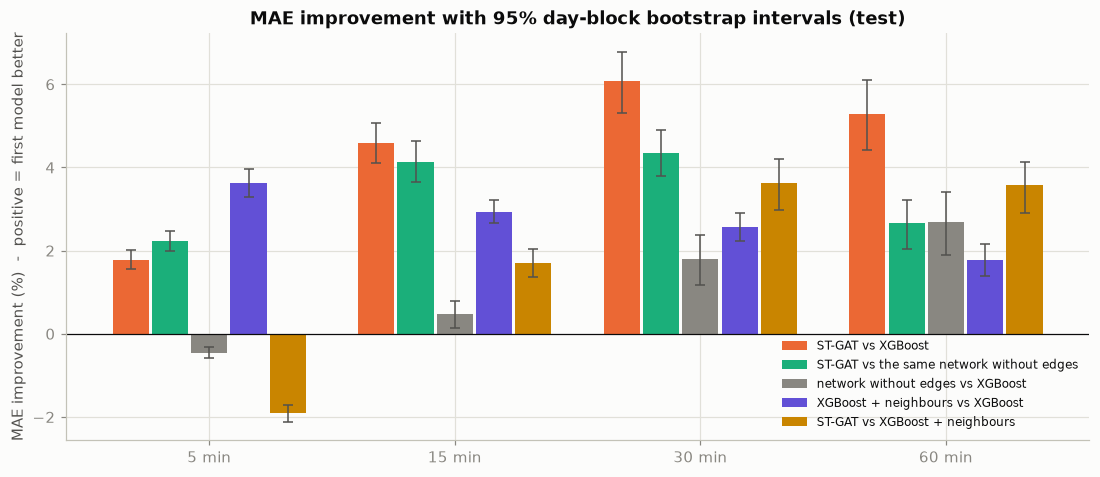

In [9]:
if comparisons:
    fig, ax = plt.subplots(figsize=(12, 4.8))
    names = [n for n in ("gat_vs_xgboost", "gat_vs_nograph", "nograph_vs_xgboost", "spatial_vs_xgboost", "gat_vs_xgboost_spatial") if n in comparisons]
    colors = {"gat_vs_xgboost": "#eb6834", "gat_vs_nograph": "#1baf7a", "nograph_vs_xgboost": "#898781", "spatial_vs_xgboost": "#6250d6", "gat_vs_xgboost_spatial": "#c98500"}
    text = {"gat_vs_xgboost": "ST-GAT vs XGBoost", "gat_vs_nograph": "ST-GAT vs the same network without edges", "nograph_vs_xgboost": "network without edges vs XGBoost",
            "spatial_vs_xgboost": "XGBoost + neighbours vs XGBoost", "gat_vs_xgboost_spatial": "ST-GAT vs XGBoost + neighbours"}
    w = 0.8 / len(names)
    x = np.arange(len(HZ))
    for k, n in enumerate(names):
        d = imp[(n, "MAE")]
        ax.bar(x + (k - (len(names) - 1) / 2) * w, d["improvement_%"], width=w * 0.92, color=colors[n], label=text[n],
               yerr=[d["improvement_%"] - d["95% CI low"], d["95% CI high"] - d["improvement_%"]], error_kw=dict(ecolor=viz.INK_2, lw=1, capsize=3))
    ax.axhline(0, color=viz.INK, lw=0.8)
    ax.set_xticks(x, [f"{h * 5} min" for h in HZ]); ax.set_ylabel("MAE improvement (%)  -  positive = first model better")
    ax.set_title("MAE improvement with 95% day-block bootstrap intervals (test)"); ax.legend(fontsize=8)
    viz.save_figure(fig, "07_improvement_over_xgboost"); plt.show()
else:
    print("ST-GAT / XGBoost predictions missing: improvement analysis skipped")

In [10]:
# Machine-generated verdict (no hand-typed numbers)
verdict_lines = []
for name, (ref, cand) in comparisons.items():
    d = imp[(name, "MAE")]
    sig_better = [int(h) for h in d.index if d.loc[h, "95% CI low"] > 0]
    sig_worse = [int(h) for h in d.index if d.loc[h, "95% CI high"] < 0]
    inconclusive = [int(h) for h in d.index if d.loc[h, "95% CI low"] <= 0 <= d.loc[h, "95% CI high"]]
    fmt = lambda hs: (", ".join(map(str, hs)) + " min") if hs else "none of the horizons"
    verdict_lines.append(f"{labels[cand]} vs {labels[ref]} (MAE): clearly better at {fmt(sig_better)}; clearly worse at {fmt(sig_worse)}; "
                         f"inconclusive at {fmt(inconclusive)} (95% day-block bootstrap, single training run).")
print("\n".join(verdict_lines))

ST-GAT vs XGBoost (MAE): clearly better at 5, 15, 30, 60 min; clearly worse at none of the horizons; inconclusive at none of the horizons (95% day-block bootstrap, single training run).
ST-GAT vs ST-GAT without edges (ablation) (MAE): clearly better at 5, 15, 30, 60 min; clearly worse at none of the horizons; inconclusive at none of the horizons (95% day-block bootstrap, single training run).
ST-GAT vs Persistence (MAE): clearly better at 5, 15, 30, 60 min; clearly worse at none of the horizons; inconclusive at none of the horizons (95% day-block bootstrap, single training run).
ST-GAT without edges (ablation) vs XGBoost (MAE): clearly better at 15, 30, 60 min; clearly worse at 5 min; inconclusive at none of the horizons (95% day-block bootstrap, single training run).
ST-GAT vs XGBoost + neighbour features (MAE): clearly better at 15, 30, 60 min; clearly worse at 5 min; inconclusive at none of the horizons (95% day-block bootstrap, single training run).
XGBoost + neighbour features vs 

**Reading the results.** A horizon counts as "clearly better" only if the whole 95% interval is above zero. The bootstrap accounts for day-to-day variation in the 24
test days but **not** for differences between training runs: the models were trained once (one seed) unless the extra-seed experiment in section 9 was run.
The comparison with the same network *without* edges isolates the effect of the road graph; the comparison with XGBoost mixes the graph effect with the
effect of the different model family (recurrent network vs trees).

## 5 · Peak versus off-peak

In [11]:
peak = ev.peak_flags_sh(ctx.timestamps, origins, HZ)                       # [S, H], by forecast target time
groups = {"peak": peak, "off-peak": ~peak}
print(f"definition: weekday hours {config.PEAK_WINDOWS} local time of the forecast target (fixed before any model was evaluated)")
grp = ev.metrics_by_group({m: preds[m] for m in MODELS}, y, valid, HZ, groups)
grp.to_csv(config.METRICS_DIR / f"{config.tagged('test_metrics_peak_offpeak')}.csv", index=False)
share = {g: float((valid & f[:, :, None]).sum() / valid.sum()) for g, f in groups.items()}
print("share of valid test points:", {k: f"{v:.1%}" for k, v in share.items()})
view = grp.assign(order=grp["model"].map({m: i for i, m in enumerate(MODELS)}), model=grp["model"].map(labels))
view = view.pivot_table(index=["group", "order", "model"], columns="horizon_min", values=["MAE", "RMSE"]).droplevel("order")
display(view.round(2))

definition: weekday hours ((7, 10), (15, 19)) local time of the forecast target (fixed before any model was evaluated)


share of valid test points: {'peak': '23.3%', 'off-peak': '76.7%'}


MAE                     RMSE  \
horizon_min                                 5     15    30    60     5    
group    model                                                            
off-peak Persistence                      2.66  3.16  3.69  4.62   4.30   
         Rolling mean (60 min)            2.99  3.37  3.88  4.83   5.71   
         Seasonal average                 3.46  3.46  3.46  3.46   6.74   
         XGBoost                          2.11  2.48  2.76  3.05   3.66   
         XGBoost + neighbour features     2.06  2.42  2.72  3.02   3.50   
         ST-GAT without edges (ablation)  2.12  2.47  2.74  2.99   3.68   
         ST-GAT                           2.09  2.39  2.64  2.93   3.57   
         DCRNN (optional)                 2.14  2.45  2.71  3.04   3.62   
peak     Persistence                      3.31  4.59  5.82  7.74   5.51   
         Rolling mean (60 min)            4.91  5.73  6.76  8.39   8.67   
         Seasonal average                 6.52  6.52  6.52  6.52  10.65   
         XGBoost                          2.92  3.98  4.83  5.67   5.11   
         XGBoost + neighbour features     2.74  3.79  4.63  5.50   4.68   
         ST-GAT without edges (ablation)  2.94  3.94  4.67  5.43   5.12   
         ST-GAT                           2.83  3.70  4.38  5.23   4.85   
         DCRNN (optional)                 2.88  3.79  4.55  5.40   4.93   

                                                               
horizon_min                                  15     30     60  
group    model                                                 
off-peak Persistence                       5.69   7.04   8.99  
         Rolling mean (60 min)             6.61   7.70   9.45  
         Seasonal average                  6.74   6.74   6.74  
         XGBoost                           4.81   5.61   6.35  
         XGBoost + neighbour features      4.60   5.42   6.20  
         ST-GAT without edges (ablation)   4.80   5.66   6.43  
         ST-GAT                            4.53   5.31   6.17  
         DCRNN (optional)                  4.63   5.46   6.35  
peak     Persistence                       8.24  10.51  13.58  
         Rolling mean (60 min)            10.14  11.86  14.37  
         Seasonal average                 10.65  10.65  10.65  
         XGBoost                           7.47   9.05  10.24  
         XGBoost + neighbour features      6.94   8.51   9.82  
         ST-GAT without edges (ablation)   7.36   8.82  10.23  
         ST-GAT                            6.74   8.09   9.68  
         DCRNN (optional)                  6.96   8.51  10.08

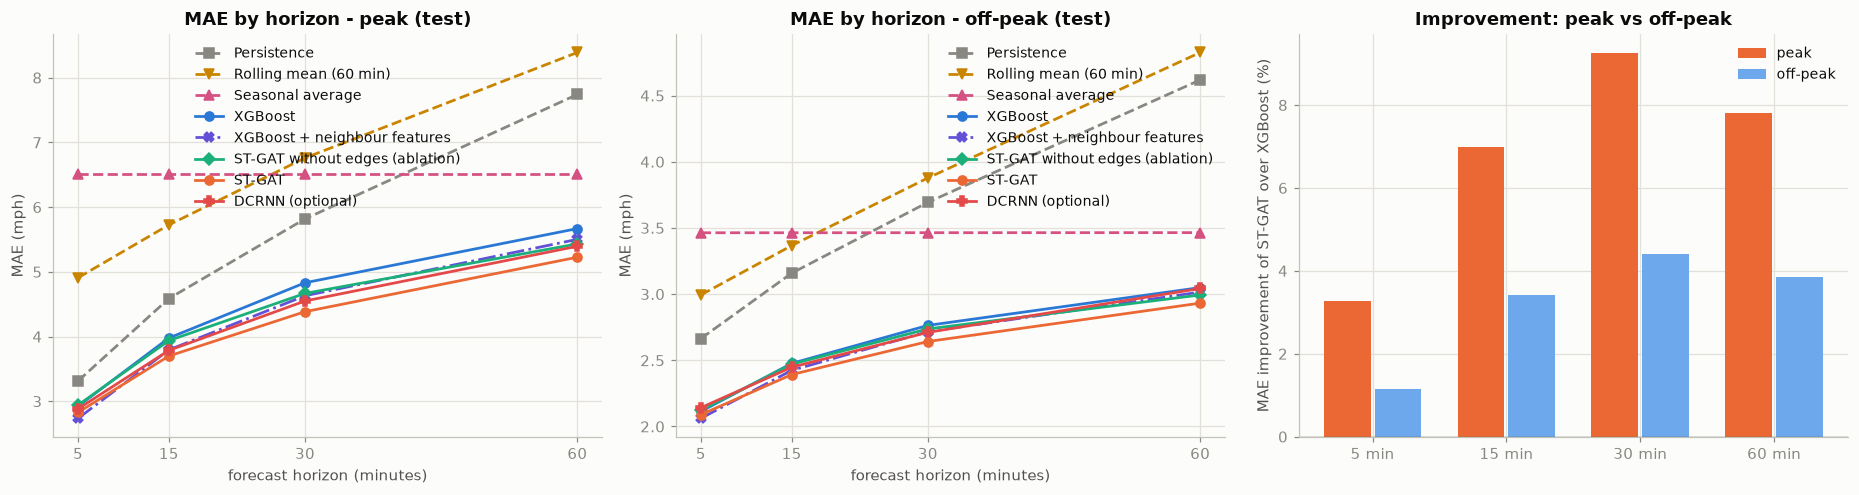

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, g in zip(axes[:2], ("peak", "off-peak")):
    viz.plot_metric_vs_horizon(ax, grp[grp.group == g], "MAE", MODELS, title=f"MAE by horizon - {g} (test)")
if {"xgboost", "gat"} <= set(MODELS):
    xs = np.arange(len(HZ)); w = 0.38
    for k, g in enumerate(("peak", "off-peak")):
        sub = grp[grp.group == g]
        ref = sub[sub.model == "xgboost"].sort_values("horizon_steps")["MAE"].to_numpy(); new = sub[sub.model == "gat"].sort_values("horizon_steps")["MAE"].to_numpy()
        axes[2].bar(xs + (k - 0.5) * w, 100 * (ref - new) / ref, width=w * 0.92, color=["#eb6834", "#6da7ec"][k], label=g)
    axes[2].axhline(0, color=viz.INK, lw=0.8); axes[2].set_xticks(xs, [f"{h * 5} min" for h in HZ])
    axes[2].set_ylabel("MAE improvement of ST-GAT over XGBoost (%)"); axes[2].set_title("Improvement: peak vs off-peak"); axes[2].legend()
fig.tight_layout(); viz.save_figure(fig, "07_peak_vs_offpeak"); plt.show()

In [13]:
if {"xgboost", "gat"} <= set(MODELS):
    rows = []
    for g, flag in groups.items():
        for j, h in enumerate(HZ):
            sel_valid = valid[:, j] & flag[:, j, None]
            sel_days = day_index[:, j]
            out = ev.day_block_bootstrap_improvement(preds["xgboost"][:, j], preds["gat"][:, j], y[:, j], sel_valid, sel_days, n_boot=1000)
            rows.append({"group": g, "horizon_min": h * 5, "improvement_%": out["improvement_pct"], "95% CI low": out["ci_low"], "95% CI high": out["ci_high"]})
    peak_imp = pd.DataFrame(rows)
    peak_imp.to_csv(config.METRICS_DIR / f"{config.tagged('improvement_peak_offpeak')}.csv", index=False)
    display(peak_imp.pivot(index="group", columns="horizon_min", values=["improvement_%", "95% CI low", "95% CI high"]).round(2))

improvement_%                   95% CI low                    \
horizon_min            5     15    30    60         5     15    30    60   
group                                                                      
off-peak             1.16  3.41  4.40  3.85       1.00  3.01  3.67  2.95   
peak                 3.28  6.99  9.25  7.81       2.96  6.31  8.34  6.64   

            95% CI high                     
horizon_min          5     15     30    60  
group                                       
off-peak           1.33  3.85   5.23  4.86  
peak               3.61  7.64  10.15  9.03

## 6 · Sensor-level analysis (where does the graph help?)

For each sensor we compare the ST-GAT with XGBoost on the test period. We then ask whether the per-sensor difference is related to
(a) the sensor's **graph degree** (in + out neighbours), (b) its **missing-data share** in the test period, and (c) its **historical variability**
(standard deviation of its *training* speeds). Relations are reported as Spearman rank correlations; they are descriptive, not causal.

In [14]:
if {"xgboost", "gat"} <= set(MODELS):
    per = {m: ev.per_sensor_metrics(preds[m], y, valid, HZ, ctx.sensor_ids) for m in ("xgboost", "gat")}
    deg = gu.graph_stats(graph.adjacency)
    a, b = ctx.splits.train
    tr_obs = ctx.mask[a:b]; tr_std = np.sqrt(np.where(tr_obs, (ctx.speed[a:b] - ctx.scaler.sensor_mean) ** 2, 0).sum(0) / np.maximum(tr_obs.sum(0), 1))
    t0, t1 = ctx.splits.test
    info = pd.DataFrame({"node": np.arange(N), "sensor_id": ctx.sensor_ids, "degree_total": deg["in_degree"] + deg["out_degree"],
                         "test_missing_%": 100 * (~ctx.mask[t0:t1]).mean(0), "train_speed_std": tr_std}).set_index("node")
    sensor_tables = {}
    for h in HZ:
        a_ = per["xgboost"][per["xgboost"].horizon_steps == h].set_index("node"); g_ = per["gat"][per["gat"].horizon_steps == h].set_index("node")
        t = info.copy(); t["MAE_xgboost"] = a_["MAE"]; t["MAE_gat"] = g_["MAE"]
        t["improvement_%"] = 100 * (t["MAE_xgboost"] - t["MAE_gat"]) / t["MAE_xgboost"]
        sensor_tables[h] = t
    pd.concat({h * 5: t for h, t in sensor_tables.items()}, names=["horizon_min"]).to_csv(config.METRICS_DIR / f"{config.tagged('sensor_level_improvement')}.csv")
    rows = []
    for h, t in sensor_tables.items():
        rows.append({"horizon_min": h * 5, "sensors where ST-GAT is better": int((t["improvement_%"] > 0).sum()), "sensors where it is worse": int((t["improvement_%"] < 0).sum()),
                     "median improvement_%": t["improvement_%"].median(), "10th pct": t["improvement_%"].quantile(.1), "90th pct": t["improvement_%"].quantile(.9)})
    display(pd.DataFrame(rows).set_index("horizon_min").round(2))

,sensors where ST-GAT is better,sensors where it is worse,median improvement_%,10th pct,90th pct
horizon_min,,,,,
5,146,61,0.93,-0.83,4.67
15,176,31,3.26,-0.34,9.00
30,181,26,4.76,-0.21,11.81
60,156,51,3.20,-1.31,12.53


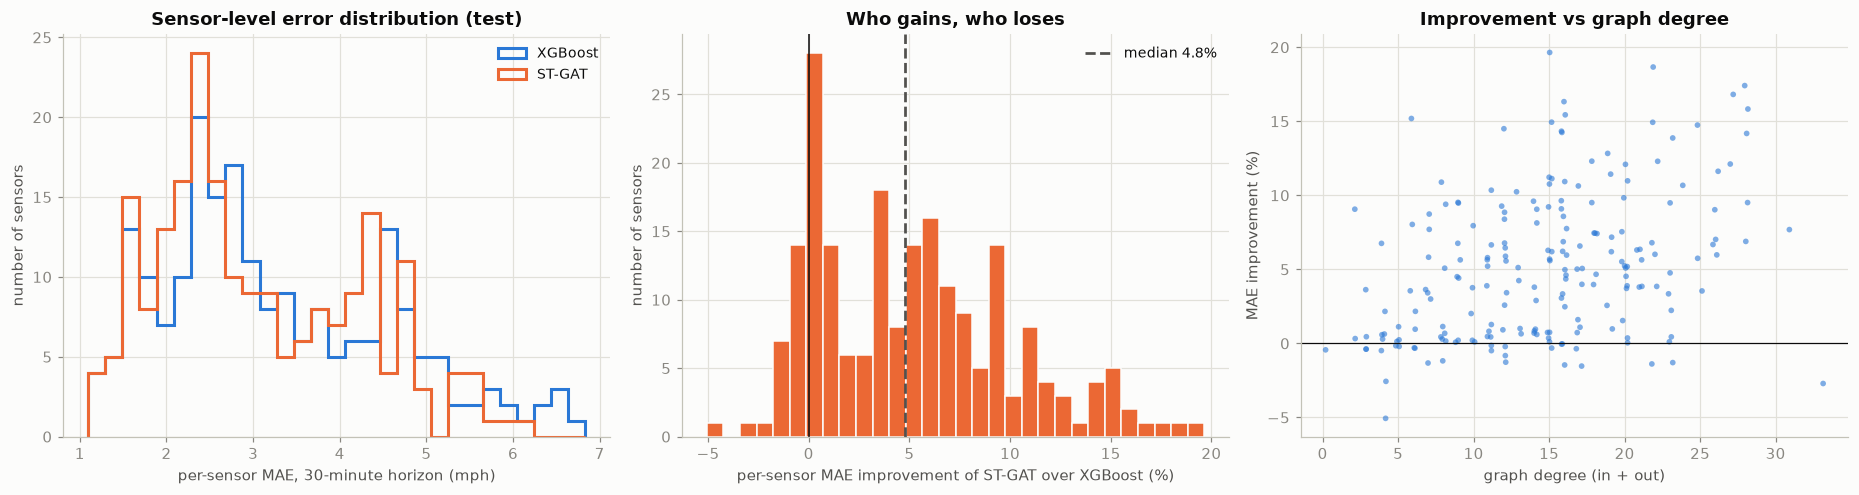

horizon_min,5,15,30,60
sensor property,,,,
graph degree,0.30,0.37,0.37,0.32
historical variability,0.51,0.59,0.66,0.65
test-period missing %,-0.06,-0.12,-0.15,-0.13


the sensor properties are themselves correlated (Spearman) - the single correlations above are confounded with each other:


,degree_total,test_missing_%,train_speed_std
degree_total,1.00,-0.12,0.31
test_missing_%,-0.12,1.00,0.04
train_speed_std,0.31,0.04,1.00



30-minute horizon - sensors where ST-GAT helps MOST:


,sensor_id,degree_total,test_missing_%,train_speed_std,MAE_xgboost,MAE_gat,improvement_%
node,,,,,,,
79,718066,16,9.64,10.21,2.34,1.96,16.33
163,717462,27,9.68,23.61,6.61,5.50,16.81
160,717461,28,19.47,22.47,6.11,5.05,17.41
127,717472,22,13.28,20.52,5.87,4.78,18.66
199,774204,15,9.64,13.39,3.82,3.07,19.65


30-minute horizon - sensors where ST-GAT performs WORST relative to XGBoost:


,sensor_id,degree_total,test_missing_%,train_speed_std,MAE_xgboost,MAE_gat,improvement_%
node,,,,,,,
90,716571,4,11.33,3.37,1.38,1.45,-5.06
16,771667,33,19.70,5.64,1.74,1.78,-2.71
194,759772,4,10.45,8.24,3.72,3.82,-2.56
168,717583,17,9.64,5.96,2.42,2.46,-1.53
40,768066,16,9.92,11.62,2.23,2.26,-1.46


isolated sensor(s) in the road graph (no neighbours to use):


,sensor_id,MAE_xgboost,MAE_gat,improvement_%
node,,,,
26,717804,4.4,4.42,-0.44


In [15]:
if {"xgboost", "gat"} <= set(MODELS):
    jh = 6 if 6 in HZ else HZ[len(HZ) // 2]
    t = sensor_tables[jh]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    # (a) distribution of per-sensor MAE of both models
    bins = np.linspace(min(t["MAE_xgboost"].min(), t["MAE_gat"].min()), max(t["MAE_xgboost"].max(), t["MAE_gat"].max()), 30)
    for m, col in (("xgboost", "MAE_xgboost"), ("gat", "MAE_gat")):
        axes[0].hist(t[col], bins=bins, histtype="step", lw=2, color=viz.style(m)["color"], label=viz.style(m)["label"])
    axes[0].set_xlabel(f"per-sensor MAE, {jh * 5}-minute horizon (mph)"); axes[0].set_ylabel("number of sensors"); axes[0].set_title("Sensor-level error distribution (test)"); axes[0].legend()
    # (b) per-sensor improvement distribution
    axes[1].hist(t["improvement_%"], bins=30, color="#eb6834", edgecolor=viz.SURFACE)
    axes[1].axvline(0, color=viz.INK, lw=1); axes[1].axvline(t["improvement_%"].median(), color=viz.INK_2, ls="--", label=f"median {t['improvement_%'].median():.1f}%")
    axes[1].set_xlabel("per-sensor MAE improvement of ST-GAT over XGBoost (%)"); axes[1].set_ylabel("number of sensors"); axes[1].set_title("Who gains, who loses"); axes[1].legend()
    # (c) improvement vs degree
    axes[2].scatter(t["degree_total"] + np.random.default_rng(0).uniform(-0.2, 0.2, len(t)), t["improvement_%"], s=14, alpha=0.6, color="#2a78d6", edgecolor="none")
    axes[2].axhline(0, color=viz.INK, lw=0.8); axes[2].set_xlabel("graph degree (in + out)"); axes[2].set_ylabel("MAE improvement (%)"); axes[2].set_title("Improvement vs graph degree")
    fig.tight_layout(); viz.save_figure(fig, "07_sensor_level"); plt.show()

    rows = []
    for h, tt in sensor_tables.items():
        for col, name in (("degree_total", "graph degree"), ("test_missing_%", "test-period missing %"), ("train_speed_std", "historical variability")):
            rho, p = stats.spearmanr(tt[col], tt["improvement_%"])
            rows.append({"horizon_min": h * 5, "sensor property": name, "Spearman rho": rho, "p-value": p})
    corr = pd.DataFrame(rows)
    display(corr.pivot(index="sensor property", columns="horizon_min", values="Spearman rho").round(2))
    props = sensor_tables[HZ[0]][["degree_total", "test_missing_%", "train_speed_std"]]
    print("the sensor properties are themselves correlated (Spearman) - the single correlations above are confounded with each other:")
    display(props.corr(method="spearman").round(2))
    corr.to_csv(config.METRICS_DIR / f"{config.tagged('sensor_level_correlations')}.csv", index=False)
    top = t.sort_values("improvement_%")
    print(f"\n{jh * 5}-minute horizon - sensors where ST-GAT helps MOST:"); display(top.tail(5)[["sensor_id", "degree_total", "test_missing_%", "train_speed_std", "MAE_xgboost", "MAE_gat", "improvement_%"]].round(2))
    print(f"{jh * 5}-minute horizon - sensors where ST-GAT performs WORST relative to XGBoost:"); display(top.head(5)[["sensor_id", "degree_total", "test_missing_%", "train_speed_std", "MAE_xgboost", "MAE_gat", "improvement_%"]].round(2))
    iso = [i for i in deg["isolated_nodes"]]
    if iso:
        print("isolated sensor(s) in the road graph (no neighbours to use):"); display(t.loc[iso, ["sensor_id", "MAE_xgboost", "MAE_gat", "improvement_%"]].round(2))

In [16]:
# degree buckets (terciles of the graph degree), mean improvement
if {"xgboost", "gat"} <= set(MODELS):
    rows = []
    for h, tt in sensor_tables.items():
        buckets = pd.qcut(tt["degree_total"].rank(method="first"), 3, labels=["low degree", "mid degree", "high degree"])
        for b, g in tt.groupby(buckets, observed=True):
            rows.append({"horizon_min": h * 5, "degree group": b, "degree range": f"{int(g.degree_total.min())}-{int(g.degree_total.max())}", "median improvement_%": g["improvement_%"].median()})
    display(pd.DataFrame(rows).pivot(index=["degree group", "degree range"], columns="horizon_min", values="median improvement_%").round(2))

,horizon_min,5,15,30,60
degree group,degree range,,,,
high degree,17-33,2.11,5.16,6.19,4.61
low degree,0-12,0.36,1.24,1.12,0.70
mid degree,12-17,1.00,4.28,5.59,4.19


**Reading the sensor-level results.** The tables count how many sensors benefit, how large the spread is, and whether the benefit correlates with
how connected, how incomplete or how variable a sensor is. With 207 sensors a Spearman |rho| below roughly 0.14 is not distinguishable from zero at the
5% level; the reported p-values should be read with that in mind, and none of this establishes a causal mechanism.

## 7 · Selected actual-versus-predicted time series (test)

Two representative sensors (rule fixed on **training** statistics) on a test weekday, at the 15- and 60-minute horizons. Gaps in the black line are missing observations.

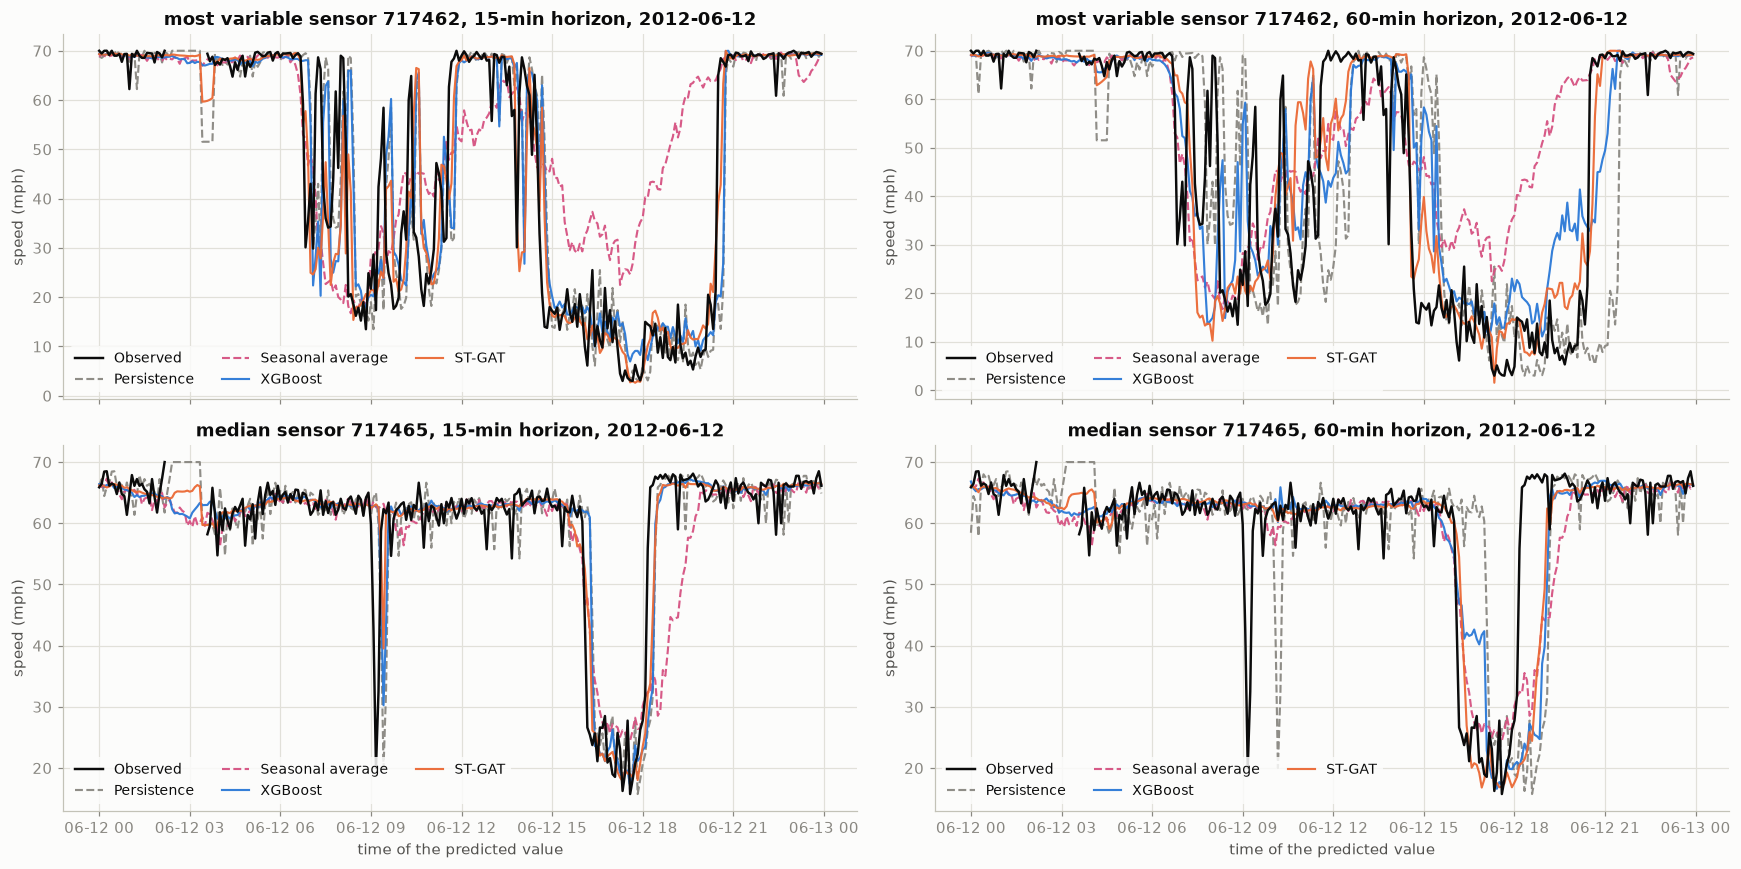

In [17]:
rep = ev.select_representative_sensors(ctx.speed, ctx.mask, ctx.splits.train, ctx.sensor_ids)
show = [m for m in ("persistence", "seasonal_avg", "xgboost", "gat") if m in MODELS]
day = pd.Timestamp("2012-06-12")                                           # a Tuesday in the test period
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True)
for col, hz in enumerate((3, 12)):
    j = HZ.index(hz); tt = ctx.timestamps[origins + hz]
    sel = np.flatnonzero((tt >= day) & (tt < day + pd.Timedelta(days=1)))
    for row, key in enumerate(("most_variable", "median")):
        n = rep[key]
        viz.plot_actual_vs_predicted(axes[row, col], tt[sel], y[sel, j, n], {m: preds[m][sel, j, n] for m in show},
                                     f"{key.replace('_', ' ')} sensor {ctx.sensor_ids[n]}, {hz * 5}-min horizon, {day.date()}")
for ax in axes[-1]:
    ax.set_xlabel("time of the predicted value")
fig.tight_layout(); viz.save_figure(fig, "07_actual_vs_predicted"); plt.show()

## 8 · Overall picture across all horizons (average over the four horizons)

In [18]:
avg = table.groupby("model")[["MAE", "RMSE", "MAPE"]].mean().reindex(MODELS)
avg.index = [labels[m] for m in avg.index]
display(avg.round(2).sort_values("MAE"))

,MAE,RMSE,MAPE
ST-GAT,2.87,5.56,7.78
XGBoost + neighbour features,2.93,5.63,8.15
DCRNN (optional),2.95,5.73,7.93
ST-GAT without edges (ablation),2.97,5.90,8.31
XGBoost,3.01,5.90,8.52
Persistence,3.96,7.30,10.06
Seasonal average,4.18,7.83,12.97
Rolling mean (60 min),4.39,8.44,12.05


## 9 · Seed robustness (only if extra seeds were trained in notebook 06)

In [19]:
seed_keys = {base: [base] + sorted(p.name.split("__")[0].replace(config.tagged(""), "") for p in config.PREDICTIONS_DIR.glob(f"{config.tagged(base + '_seed')}*__test.npz")) for base in ("gat", "gat_nograph", "dcrnn")}
rows = []
for base, keys in seed_keys.items():
    for k in keys:
        try:
            d = ev.load_predictions(k, "test")
        except FileNotFoundError:
            continue
        for j, h in enumerate(HZ):
            rows.append({"model": base, "run": k, "horizon_min": h * 5, "MAE": compute_metrics(d["pred"][:, j], y[:, j], valid[:, j])["MAE"]})
seed_table = pd.DataFrame(rows)
if seed_table.groupby("model")["run"].nunique().max() > 1:
    summary = seed_table.groupby(["model", "horizon_min"])["MAE"].agg(["mean", "std", "min", "max", "count"])
    display(summary.round(3)); seed_table.to_csv(config.METRICS_DIR / f"{config.tagged('seed_robustness')}.csv", index=False)
    # paired by seed: improvement of each ST-GAT run over (a) the single XGBoost model and (b) the no-edge run with the SAME seed
    xgb_mae = table[table.model == "xgboost"].set_index("horizon_min")["MAE"] if "xgboost" in MODELS else None
    rows = []
    for k in seed_keys["gat"]:
        if k not in set(seed_table.run):
            continue
        twin = k.replace("gat", "gat_nograph", 1)
        for h in HZ:
            g = seed_table[(seed_table.run == k) & (seed_table.horizon_min == h * 5)]["MAE"].iloc[0]
            n_ = seed_table[(seed_table.run == twin) & (seed_table.horizon_min == h * 5)]["MAE"]
            rows.append({"run": k, "horizon_min": h * 5, "MAE ST-GAT": g,
                         "improvement over XGBoost %": improvement_pct(xgb_mae[h * 5], g) if xgb_mae is not None else np.nan,
                         "improvement over same-seed no-edge %": improvement_pct(n_.iloc[0], g) if len(n_) else np.nan})
    paired = pd.DataFrame(rows)
    display(paired.pivot(index="run", columns="horizon_min", values="improvement over XGBoost %").round(2).rename_axis("ST-GAT improvement over XGBoost (%), by seed"))
    display(paired.pivot(index="run", columns="horizon_min", values="improvement over same-seed no-edge %").round(2).rename_axis("ST-GAT improvement over the no-edge network of the same seed (%)"))
    paired.to_csv(config.METRICS_DIR / f"{config.tagged('seed_paired_improvements')}.csv", index=False)
    seed_claims = {
        "[seeds] every ST-GAT seed beats XGBoost in MAE at every horizon": bool((paired["improvement over XGBoost %"] > 0).all()),
        "[seeds] every ST-GAT seed beats the no-edge network of the same seed at every horizon": bool((paired["improvement over same-seed no-edge %"] > 0).all()),
        "[seeds] the seed-to-seed std of ST-GAT test MAE is below 0.05 mph at every horizon": bool((summary.loc["gat", "std"] < 0.05).all()),
        "[seeds] the smallest per-seed gain over the no-edge network exceeds the largest seed std of ST-GAT and its ablation": bool(paired["improvement over same-seed no-edge %"].min() / 100 * summary.loc["gat", "mean"].min() > summary.loc[["gat", "gat_nograph"], "std"].max()),
    }
    if "dcrnn" in summary.index.get_level_values(0) and summary.loc["dcrnn", "count"].min() > 1:
        seed_claims["[seeds] averaged over seeds, ST-GAT has lower MAE than the DCRNN-style model at every horizon"] = bool((summary.loc["gat", "mean"] < summary.loc["dcrnn", "mean"]).all())
        seed_claims["[seeds] the DCRNN-style model varies much more between seeds than ST-GAT (std larger at every horizon)"] = bool((summary.loc["dcrnn", "std"] > 2 * summary.loc["gat", "std"]).all())
    display(ev.report_claims(seed_claims))
else:
    seed_claims = {}
    print("only one training run per model is available: seed-to-seed variability was NOT measured; treat small differences between models with caution.")

mean    std    min    max  count
model       horizon_min                                   
dcrnn       5            2.284  0.028  2.262  2.315      3
            15           2.759  0.023  2.737  2.782      3
            30           3.165  0.063  3.118  3.236      3
            60           3.659  0.151  3.554  3.832      3
gat         5            2.261  0.004  2.257  2.265      3
            15           2.695  0.004  2.690  2.697      3
            30           3.045  0.009  3.035  3.052      3
            60           3.464  0.012  3.450  3.474      3
gat_nograph 5            2.318  0.005  2.313  2.323      3
            15           2.820  0.009  2.813  2.830      3
            30           3.191  0.004  3.187  3.194      3
            60           3.571  0.008  3.562  3.577      3

horizon_min,5,15,30,60
"ST-GAT improvement over XGBoost (%), by seed",,,,
gat,1.79,4.58,6.09,5.28
gat_seed1,1.64,4.57,5.96,5.10
gat_seed2,1.97,4.81,6.51,5.74


horizon_min,5,15,30,60
ST-GAT improvement over the no-edge network of the same seed (%),,,,
gat,2.23,4.12,4.36,2.67
gat_seed1,2.30,4.30,4.44,2.90
gat_seed2,2.83,4.92,4.89,3.43


,claim,holds in this run
0,[seeds] every ST-GAT seed beats XGBoost in MAE...,True
1,[seeds] every ST-GAT seed beats the no-edge ne...,True
2,[seeds] the seed-to-seed std of ST-GAT test MA...,True
3,[seeds] the smallest per-seed gain over the no...,True
4,"[seeds] averaged over seeds, ST-GAT has lower ...",True
5,[seeds] the DCRNN-style model varies much more...,True


In [20]:
SEED_TEXT = "**Seed robustness** (three training runs, seeds 42, 1 and 2, for both the ST-GAT and its no-edge twin; XGBoost is deterministic and was fitted once).\n\n* The ST-GAT's test MAE varies by only about a hundredth of a mph between seeds, far less than its gap to XGBoost or to the no-edge network.\n* **Every** seed beats XGBoost at every horizon and beats the no-edge network trained with the same seed at every horizon, so the graph effect reported above is not an accident of one initialisation.\n* Three seeds is still a small sample; it shows the effect is stable, not a precise estimate of its size."
from IPython.display import Markdown
if seed_claims and all(seed_claims.values()):
    display(Markdown(SEED_TEXT))
elif seed_claims:
    print("some seed claims do not hold in this run: read the seed tables directly")

**Seed robustness** (three training runs, seeds 42, 1 and 2, for both the ST-GAT and its no-edge twin; XGBoost is deterministic and was fitted once).

* The ST-GAT's test MAE varies by only about a hundredth of a mph between seeds, far less than its gap to XGBoost or to the no-edge network.
* **Every** seed beats XGBoost at every horizon and beats the no-edge network trained with the same seed at every horizon, so the graph effect reported above is not an accident of one initialisation.
* Three seeds is still a small sample; it shows the effect is stable, not a precise estimate of its size.

## 10 · Final comparison summary (generated from the tables)

In [21]:
lines = []
for j, h in enumerate(HZ):
    row = table[table.horizon_steps == h].set_index("model")["MAE"]
    order = [labels[m] for m in row.sort_values().index]
    lines.append(f"{h * 5:>2d} min: " + " < ".join(f"{labels[m]} {row[m]:.2f}" for m in row.sort_values().index))
print("Test MAE ranking per horizon (lower is better):"); print("\n".join(lines))
print()
print("\n".join(verdict_lines))
if config.IS_SMOKE:
    print("\n*** SMOKE RUN: not final results ***")

Test MAE ranking per horizon (lower is better):
 5 min: XGBoost + neighbour features 2.22 < ST-GAT 2.26 < XGBoost 2.30 < ST-GAT without edges (ablation) 2.31 < DCRNN (optional) 2.31 < Persistence 2.82 < Rolling mean (60 min) 3.44 < Seasonal average 4.18
15 min: ST-GAT 2.70 < XGBoost + neighbour features 2.74 < DCRNN (optional) 2.76 < ST-GAT without edges (ablation) 2.81 < XGBoost 2.83 < Persistence 3.49 < Rolling mean (60 min) 3.92 < Seasonal average 4.18
30 min: ST-GAT 3.05 < DCRNN (optional) 3.14 < XGBoost + neighbour features 3.16 < ST-GAT without edges (ablation) 3.19 < XGBoost 3.25 < Seasonal average 4.18 < Persistence 4.19 < Rolling mean (60 min) 4.55
60 min: ST-GAT 3.47 < ST-GAT without edges (ablation) 3.56 < DCRNN (optional) 3.59 < XGBoost + neighbour features 3.60 < XGBoost 3.66 < Seasonal average 4.18 < Persistence 5.35 < Rolling mean (60 min) 5.66

ST-GAT vs XGBoost (MAE): clearly better at 5, 15, 30, 60 min; clearly worse at none of the horizons; inconclusive at none of th

## 10b · Findings (claims checked against this run)

The statements in the next cell are the ones the interpretation below relies on. A warning is printed if any of them does not hold in your run (for example after retraining with another seed).

In [22]:
claims = {}
edge_share = None
if {"gat", "gat_nograph", "xgboost"} <= set(MODELS):
    edge_share = (imp[("gat_vs_nograph", "MAE")]["improvement_%"] / imp[("gat_vs_xgboost", "MAE")]["improvement_%"]).rename("graph-edge share of the ST-GAT gain over XGBoost")
    claims["the edge-attributable share of the gain over XGBoost shrinks with the horizon"] = bool(edge_share.is_monotonic_decreasing)
if {"xgboost", "gat"} <= set(MODELS):
    ix = imp[("gat_vs_xgboost", "MAE")]
    main_models = [m for m in ("persistence", "rolling_mean", "seasonal_avg", "xgboost", "gat_nograph", "gat") if m in MODELS]
    main_best = table[table.model.isin(main_models)].loc[lambda d: d.groupby("horizon_min")["MAE"].idxmin()]
    claims["ST-GAT has the lowest test MAE among the main-experiment models at every horizon"] = bool((main_best["model"] == "gat").all())
    claims["ST-GAT beats XGBoost at every horizon (95% interval entirely above 0)"] = bool((ix["95% CI low"] > 0).all())
    claims["ST-GAT's gain over XGBoost is smallest at the 5-minute horizon"] = bool(ix["improvement_%"].idxmin() == 5)
    claims["the absolute MAE gap to XGBoost never exceeds 0.3 mph"] = bool(((table[table.model == "xgboost"].set_index("horizon_min")["MAE"] - table[table.model == "gat"].set_index("horizon_min")["MAE"]).abs() < 0.3).all())
if {"gat_nograph", "gat"} <= set(MODELS):
    ig = imp[("gat_vs_nograph", "MAE")]
    claims["ST-GAT beats its own no-edge ablation at every horizon (95% interval entirely above 0)"] = bool((ig["95% CI low"] > 0).all())
if {"gat_nograph", "xgboost"} <= set(MODELS):
    inx = imp[("nograph_vs_xgboost", "MAE")]
    claims["the no-edge network is within 3.5% (MAE) of XGBoost at every horizon, i.e. roughly on par"] = bool((inx["improvement_%"].abs() < 3.5).all())
if "peak_imp" in globals():
    p_, o_ = peak_imp[peak_imp.group == "peak"].set_index("horizon_min"), peak_imp[peak_imp.group == "off-peak"].set_index("horizon_min")
    claims["ST-GAT's gain over XGBoost is larger at peak than off-peak at every horizon (intervals do not overlap)"] = bool((p_["95% CI low"] > o_["95% CI high"]).all())
if "sensor_tables" in globals():
    claims["ST-GAT has the lower MAE than XGBoost at a clear majority (> 60%) of sensors at every horizon"] = bool(all((tt["improvement_%"] > 0).mean() > 0.6 for tt in sensor_tables.values()))
    claims["the per-sensor gain correlates positively with historical variability (rho > 0.3 at every horizon)"] = bool((corr[corr["sensor property"] == "historical variability"]["Spearman rho"] > 0.3).all())
    claims["the per-sensor gain correlates positively with graph degree (rho > 0.2 at every horizon)"] = bool((corr[corr["sensor property"] == "graph degree"]["Spearman rho"] > 0.2).all())
if {"dcrnn", "gat", "xgboost", "gat_nograph"} <= set(MODELS):
    mae_ = table.pivot(index="horizon_min", columns="model", values="MAE"); rmse_ = table.pivot(index="horizon_min", columns="model", values="RMSE"); mape_ = table.pivot(index="horizon_min", columns="model", values="MAPE")
    claims["[DCRNN] the DCRNN-style graph model beats XGBoost in MAE at 15, 30 and 60 min"] = bool((mae_.loc[[15, 30, 60], "dcrnn"] < mae_.loc[[15, 30, 60], "xgboost"]).all())
    claims["[DCRNN] at 5 min it is within 1% of XGBoost (a tie)"] = bool(abs(mae_.loc[5, "dcrnn"] / mae_.loc[5, "xgboost"] - 1) < 0.01)
    claims["[DCRNN] ST-GAT has lower MAE, RMSE and MAPE than the DCRNN-style model at every horizon"] = bool((mae_["gat"] < mae_["dcrnn"]).all() and (rmse_["gat"] < rmse_["dcrnn"]).all() and (mape_["gat"] < mape_["dcrnn"]).all())
    claims["[DCRNN] the DCRNN-style MAE is within 5% of the ST-GAT's at every horizon"] = bool(((mae_["dcrnn"] / mae_["gat"] - 1).abs() < 0.05).all())
    claims["[DCRNN] at 60 min it is within 1% of the no-edge network (no gain from its graph there)"] = bool(abs(mae_.loc[60, "dcrnn"] / mae_.loc[60, "gat_nograph"] - 1) < 0.01)
if {"xgboost_spatial", "xgboost", "gat"} <= set(MODELS):
    isx, igs = imp[("spatial_vs_xgboost", "MAE")], imp[("gat_vs_xgboost_spatial", "MAE")]
    tab5 = table[table.horizon_min == 5].set_index("model")
    claims["[spatial] neighbour features improve XGBoost at every horizon (95% interval above 0)"] = bool((isx["95% CI low"] > 0).all())
    claims["[spatial] at 5 min the spatial XGBoost has the lowest MAE, RMSE and MAPE of all models"] = bool(all(tab5[m].idxmin() == "xgboost_spatial" for m in ("MAE", "RMSE", "MAPE")))
    claims["[spatial] at 5 min it is clearly better than the ST-GAT (interval below 0 for ST-GAT's improvement)"] = bool(igs.loc[5, "95% CI high"] < 0)
    claims["[spatial] the ST-GAT beats the spatial XGBoost at 15, 30 and 60 min (intervals above 0)"] = bool((igs.loc[[15, 30, 60], "95% CI low"] > 0).all())
display(ev.report_claims(claims))
if edge_share is not None:
    print("ratio of (ST-GAT vs no-edge) to (ST-GAT vs XGBoost) improvement, per horizon - a descriptive ratio of two single-seed estimates, not a variance decomposition:")
    display(edge_share.round(2).to_frame())

,claim,holds in this run
0,the edge-attributable share of the gain over X...,True
1,ST-GAT has the lowest test MAE among the main-...,True
2,ST-GAT beats XGBoost at every horizon (95% int...,True
3,ST-GAT's gain over XGBoost is smallest at the ...,True
4,the absolute MAE gap to XGBoost never exceeds ...,True
5,ST-GAT beats its own no-edge ablation at every...,True
6,the no-edge network is within 3.5% (MAE) of XG...,True
7,ST-GAT's gain over XGBoost is larger at peak t...,True
8,ST-GAT has the lower MAE than XGBoost at a cle...,True
9,the per-sensor gain correlates positively with...,True


ratio of (ST-GAT vs no-edge) to (ST-GAT vs XGBoost) improvement, per horizon - a descriptive ratio of two single-seed estimates, not a variance decomposition:


,graph-edge share of the ST-GAT gain over XGBoost
horizon_min,
5,1.25
15,0.90
30,0.72
60,0.51


**Findings (delivered run, 24 test days; the main tables use seed 42, the seed section covers seeds 42, 1 and 2).**

1. **Model ranking (main experiment).** Among the baselines, XGBoost, the ST-GAT and its no-edge ablation, the ST-GAT has the lowest test MAE at every horizon, followed by XGBoost and the no-edge network, which are close to each other. All three learned models beat persistence clearly; the seasonal average only beats persistence at long horizons. In absolute terms the ST-GAT's advantage over XGBoost is small: a few hundredths to about two tenths of a mph of MAE, i.e. a few percent.
2. **Does the graph help?** Within the same architecture, parameter count and training recipe, restricting attention to the sensor itself (no edges) is clearly worse than letting it use its road-graph neighbours, at every horizon, with intervals above zero. The no-edge network is roughly on par with XGBoost. Together this suggests that most of the ST-GAT's advantage over the independent-sensor models is associated with using the neighbouring sensors rather than with the neural architecture alone. The ratio of the two improvements (ST-GAT vs no-edge divided by ST-GAT vs XGBoost, shown in notebook 07 section 10b; its decrease with the horizon is one of the checked claims) indicates that the share attributable to the edges is largest at short horizons and smallest at 60 minutes; this is a descriptive ratio of two single-seed estimates, not a decomposition.
3. **Peak vs off-peak.** The graph model's gain over XGBoost is clearly larger at peak (weekday commute) hours than off-peak, at every horizon, which is when congestion forms and propagates.
4. **Sensors.** The ST-GAT has the lower error at a clear majority of sensors at every horizon, but not at all of them: a minority gets slightly worse, and the one sensor that is isolated in the road graph (no neighbours to use) shows no gain (slightly negative at the 30-minute horizon shown in the notebook). The per-sensor gain is positively correlated with the sensor's historical variability and, less strongly, with its graph degree; the two properties are themselves correlated, so these single correlations do not separate their effects.
5. **What is *not* established.** The bootstrap intervals cover only day-to-day variation of the 24 test days; training randomness is covered only by the seed section (a small number of seeds, where they were trained). The graph-agnostic XGBoost is complemented by a tree model that is given neighbour features (notebook 05b, paragraph below), so the spatial effect is checked for two model families, not just one. The test period has much more missing data than the training period, and everything is 119 days of one city. Attention weights are not causal evidence.

In [23]:
SPATIAL_TEXT = '**Spatial tree baseline: XGBoost with road-graph neighbour features** (notebook 05b: the same XGBoost plus upstream/downstream neighbour speeds).\n\n* Giving the tree model its neighbours\' speeds improves it at **every** horizon, so the value of spatial information is not specific to graph neural networks.\n* At **5 minutes** this spatial XGBoost is the **best model of all** on MAE, RMSE and MAPE, clearly ahead of the ST-GAT: for the very short term, "current speeds of the sensor and its neighbours fed to a tree model" is hard to beat.\n* From **15 to 60 minutes** the ST-GAT is clearly better than the spatial XGBoost; its advantage there is what the learned spatio-temporal representation adds on top of simple neighbour features.\n* Revised reading of the research question: **using connected sensors helps** (for both model families and at every horizon); the graph *neural network* adds value specifically beyond the shortest horizon.'
from IPython.display import Markdown
spatial_claims = {k: v for k, v in claims.items() if k.startswith("[spatial]")}
if spatial_claims and all(spatial_claims.values()):
    display(Markdown(SPATIAL_TEXT))
elif spatial_claims:
    print("some [spatial] claims do not hold in this run: read the spatial-XGBoost rows from the tables")
else:
    print("spatial XGBoost predictions not available (notebook 05b not run)")

**Spatial tree baseline: XGBoost with road-graph neighbour features** (notebook 05b: the same XGBoost plus upstream/downstream neighbour speeds).

* Giving the tree model its neighbours' speeds improves it at **every** horizon, so the value of spatial information is not specific to graph neural networks.
* At **5 minutes** this spatial XGBoost is the **best model of all** on MAE, RMSE and MAPE, clearly ahead of the ST-GAT: for the very short term, "current speeds of the sensor and its neighbours fed to a tree model" is hard to beat.
* From **15 to 60 minutes** the ST-GAT is clearly better than the spatial XGBoost; its advantage there is what the learned spatio-temporal representation adds on top of simple neighbour features.
* Revised reading of the research question: **using connected sensors helps** (for both model families and at every horizon); the graph *neural network* adds value specifically beyond the shortest horizon.

In [24]:
DCRNN_TEXT = '**Optional DCRNN-style comparison** (only present when notebook 06b was run; a PyTorch re-implementation, not the original DCRNN, trained on one third of the training windows with the same 30-epoch budget as the ST-GAT; three seeds, see the seed section).\n\n* A second, architecturally different graph model beats the independent-sensor XGBoost at 15, 30 and 60 minutes and ties it at 5 minutes (seed-42 run), consistent with neighbouring sensors helping beyond the shortest horizon.\n* The ST-GAT is better than the DCRNN-style model on every metric and horizon in the seed-42 run, and **averaged over three seeds** its MAE is lower at every horizon (checked in the seed section).\n* The DCRNN-style model is much less stable between seeds than the ST-GAT (its seed-to-seed spread is several times larger, especially at 60 minutes). This explains why an earlier, superseded DCRNN run once looked slightly ahead of the ST-GAT on MAPE: single DCRNN runs are noisy.\n* At 60 minutes the seed-42 DCRNN run is about on par with the no-edge network, i.e. it shows no gain from its graph there.'
from IPython.display import Markdown
if "dcrnn" in MODELS and all(v for k, v in claims.items() if k.startswith("[DCRNN]")):
    display(Markdown(DCRNN_TEXT))
elif "dcrnn" in MODELS:
    print("some [DCRNN] claims do not hold in this run: the DCRNN paragraph is not shown - interpret the DCRNN rows from the tables")
else:
    print("DCRNN predictions not available (notebook 06b not run): no DCRNN findings")

**Optional DCRNN-style comparison** (only present when notebook 06b was run; a PyTorch re-implementation, not the original DCRNN, trained on one third of the training windows with the same 30-epoch budget as the ST-GAT; three seeds, see the seed section).

* A second, architecturally different graph model beats the independent-sensor XGBoost at 15, 30 and 60 minutes and ties it at 5 minutes (seed-42 run), consistent with neighbouring sensors helping beyond the shortest horizon.
* The ST-GAT is better than the DCRNN-style model on every metric and horizon in the seed-42 run, and **averaged over three seeds** its MAE is lower at every horizon (checked in the seed section).
* The DCRNN-style model is much less stable between seeds than the ST-GAT (its seed-to-seed spread is several times larger, especially at 60 minutes). This explains why an earlier, superseded DCRNN run once looked slightly ahead of the ST-GAT on MAPE: single DCRNN runs are noisy.
* At 60 minutes the seed-42 DCRNN run is about on par with the no-edge network, i.e. it shows no gain from its graph there.

## 11 · Write `reports/results_summary.md`

The summary is **generated from the tables computed above** (no number is typed by hand). Anything that was not run is listed as such. Smoke runs do not overwrite the report.

In [25]:
FINDINGS = "**Findings (delivered run, 24 test days; the main tables use seed 42, the seed section covers seeds 42, 1 and 2).**\n\n1. **Model ranking (main experiment).** Among the baselines, XGBoost, the ST-GAT and its no-edge ablation, the ST-GAT has the lowest test MAE at every horizon, followed by XGBoost and the no-edge network, which are close to each other. All three learned models beat persistence clearly; the seasonal average only beats persistence at long horizons. In absolute terms the ST-GAT's advantage over XGBoost is small: a few hundredths to about two tenths of a mph of MAE, i.e. a few percent.\n2. **Does the graph help?** Within the same architecture, parameter count and training recipe, restricting attention to the sensor itself (no edges) is clearly worse than letting it use its road-graph neighbours, at every horizon, with intervals above zero. The no-edge network is roughly on par with XGBoost. Together this suggests that most of the ST-GAT's advantage over the independent-sensor models is associated with using the neighbouring sensors rather than with the neural architecture alone. The ratio of the two improvements (ST-GAT vs no-edge divided by ST-GAT vs XGBoost, shown in notebook 07 section 10b; its decrease with the horizon is one of the checked claims) indicates that the share attributable to the edges is largest at short horizons and smallest at 60 minutes; this is a descriptive ratio of two single-seed estimates, not a decomposition.\n3. **Peak vs off-peak.** The graph model's gain over XGBoost is clearly larger at peak (weekday commute) hours than off-peak, at every horizon, which is when congestion forms and propagates.\n4. **Sensors.** The ST-GAT has the lower error at a clear majority of sensors at every horizon, but not at all of them: a minority gets slightly worse, and the one sensor that is isolated in the road graph (no neighbours to use) shows no gain (slightly negative at the 30-minute horizon shown in the notebook). The per-sensor gain is positively correlated with the sensor's historical variability and, less strongly, with its graph degree; the two properties are themselves correlated, so these single correlations do not separate their effects.\n5. **What is *not* established.** The bootstrap intervals cover only day-to-day variation of the 24 test days; training randomness is covered only by the seed section (a small number of seeds, where they were trained). The graph-agnostic XGBoost is complemented by a tree model that is given neighbour features (notebook 05b, paragraph below), so the spatial effect is checked for two model families, not just one. The test period has much more missing data than the training period, and everything is 119 days of one city. Attention weights are not causal evidence."
SPATIAL_TEXT = '**Spatial tree baseline: XGBoost with road-graph neighbour features** (notebook 05b: the same XGBoost plus upstream/downstream neighbour speeds).\n\n* Giving the tree model its neighbours\' speeds improves it at **every** horizon, so the value of spatial information is not specific to graph neural networks.\n* At **5 minutes** this spatial XGBoost is the **best model of all** on MAE, RMSE and MAPE, clearly ahead of the ST-GAT: for the very short term, "current speeds of the sensor and its neighbours fed to a tree model" is hard to beat.\n* From **15 to 60 minutes** the ST-GAT is clearly better than the spatial XGBoost; its advantage there is what the learned spatio-temporal representation adds on top of simple neighbour features.\n* Revised reading of the research question: **using connected sensors helps** (for both model families and at every horizon); the graph *neural network* adds value specifically beyond the shortest horizon.'

import datetime

def md_table(df, fmt="{:.2f}", index=True):
    d = df.reset_index() if index else df.copy()
    cols = [str(c) if not isinstance(c, tuple) else " ".join(str(x) for x in c) for c in d.columns]
    rows = [[fmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in r] for r in d.itertuples(index=False)]
    return "\n".join(["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"] + ["| " + " | ".join(r) + " |" for r in rows])

main_cols = lambda metric: table.pivot(index="model", columns="horizon_min", values=metric).reindex(MODELS).rename(index=labels).rename(columns=lambda h: f"{h} min")
sumo_ran = (config.METRICS_DIR / "sumo_signal_control_results.csv").is_file()
n_seed_runs = int(seed_table.groupby("model")["run"].nunique().max()) if len(seed_table) else 1
parts = []
parts.append("# Results summary\n")
parts.append(f"*Generated by `notebooks/07_model_evaluation.ipynb` on {datetime.date.today()} from the saved predictions and metric tables; run mode: **{config.RUN_MODE}**. "
             "Every number below was computed by that notebook; nothing was typed by hand.*\n")
parts.append("## What was and was not run\n")
parts.append(f"* Models scored on the test period: {', '.join(labels[m] for m in MODELS)}.")
parts.append(f"* Models without prediction files (reported missing, nothing invented): {', '.join(viz.style(m)['label'] for m in missing_models) or 'none'}.")
parts.append(f"* Training runs per neural model: {n_seed_runs} (seed-to-seed variability {'was measured, see below' if n_seed_runs > 1 else 'was NOT measured'}).")
parts.append(f"* SUMO signal-control simulation: {'executed (see the simulation section below)' if sumo_ran else '**not executed** (SUMO was not installed); there are no simulation results'}.")
parts.append(f"* Test period: {ctx.splits.first_timestamp['test']} to {ctx.splits.last_timestamp['test']}; {len(origins):,} forecast origins x {N} sensors x {len(HZ)} horizons; "
             f"{int(valid.sum()):,} valid points scored (targets observed for all models; {1 - ymask.mean():.1%} of target cells are missing and excluded).\n")
parts.append("## Test-period metrics by forecast horizon\n")
for metric, unit in (("MAE", "mph"), ("RMSE", "mph"), ("MAPE", "%")):
    parts.append(f"**{metric} ({unit})**\n\n" + md_table(main_cols(metric)) + "\n")
parts.append("## Does the graph help? Improvement of ST-GAT (positive = ST-GAT has the lower error)\n")
for name, (ref, cand) in comparisons.items():
    parts.append(f"**{labels[cand]} vs {labels[ref]}**, improvement in % with 95% day-block bootstrap interval\n\n" +
                 md_table(pd.concat({m: imp[(name, m)][["improvement_%", "95% CI low", "95% CI high"]] for m in ("MAE", "RMSE")}, axis=1)) + "\n")
parts.append("**Machine-generated verdict (MAE):**\n\n" + "\n".join(f"* {v}" for v in verdict_lines) + "\n")
if "peak_imp" in globals():
    parts.append("## Peak vs off-peak (ST-GAT vs XGBoost, MAE improvement %)\n\n" + md_table(peak_imp.pivot(index="group", columns="horizon_min", values="improvement_%").rename(columns=lambda h: f"{h} min")) + "\n")
    parts.append(f"Peak = weekdays {config.PEAK_WINDOWS} local time of the forecast target (fixed before any model ran); share of valid points: " + ", ".join(f"{k} {v:.1%}" for k, v in share.items()) + ".\n")
if "sensor_tables" in globals():
    rows = [{"horizon": f"{h * 5} min", "sensors ST-GAT better": int((tt["improvement_%"] > 0).sum()), "sensors worse": int((tt["improvement_%"] < 0).sum()),
             "median improvement %": tt["improvement_%"].median()} for h, tt in sensor_tables.items()]
    parts.append("## Sensor-level (ST-GAT vs XGBoost)\n\n" + md_table(pd.DataFrame(rows), index=False) + "\n")
    parts.append("Spearman correlation of the per-sensor improvement with sensor properties (descriptive only):\n\n" + md_table(corr.pivot(index="sensor property", columns="horizon_min", values="Spearman rho").rename(columns=lambda h: f"{h} min")) + "\n")
parts.append("## Findings\n\n" + (FINDINGS if all(claims.values()) else "*Some interpretation claims do not hold in this run (see notebook 07, section 10b); the findings text is therefore omitted.*") + "\n")
if {"xgboost_spatial", "xgboost", "gat"} <= set(MODELS) and all(v for k, v in claims.items() if k.startswith("[spatial]")):
    parts.append(SPATIAL_TEXT + "\n")
if "dcrnn" in MODELS and all(v for k, v in claims.items() if k.startswith("[DCRNN]")):
    parts.append(DCRNN_TEXT + "\n")
if "paired" in globals() and len(paired):
    seed_mae = seed_table.groupby(["model", "horizon_min"])["MAE"].agg(["mean", "std", "min", "max", "count"]).round(3)
    parts.append("## Seed robustness (test MAE, mph)\n\n" + md_table(seed_mae, fmt="{:.3f}") + "\n")
    parts.append("ST-GAT improvement (%) per seed over XGBoost (single XGBoost model; it is deterministic):\n\n" + md_table(paired.pivot(index="run", columns="horizon_min", values="improvement over XGBoost %").rename(columns=lambda h: f"{h} min")) + "\n")
    parts.append("ST-GAT improvement (%) per seed over the no-edge network trained with the **same** seed:\n\n" + md_table(paired.pivot(index="run", columns="horizon_min", values="improvement over same-seed no-edge %").rename(columns=lambda h: f"{h} min")) + "\n")
    if "SEED_TEXT" in globals() and seed_claims and all(seed_claims.values()):
        parts.append(SEED_TEXT + "\n")
sumo_csv = config.METRICS_DIR / "sumo_signal_control_paired.csv"
if sumo_csv.is_file():
    sumo_tab = pd.read_csv(sumo_csv).set_index(["comparison", "metric"])[["mean reference", "mean queue-aware", "mean difference", "95% CI low", "95% CI high", "relative change %", "seeds where queue-aware is lower"]]
    parts.append("## Optional simulation: queue-aware vs two fixed-time plans (SUMO, one synthetic intersection)\n\n"
                 "Paired over seeds with identical demand (notebook 09); negative difference = queue-aware lower. `fixed` = naive 30 s / 30 s plan, `fixed_webster` = time-of-day plan tuned to the demand with Webster's method. "
                 "Queue-aware beats the naive plan but loses to the tuned plan on every seed. Simulation only; the METR-LA forecasts are not used by the controller.\n\n"
                 + md_table(sumo_tab) + "\n")
parts.append("## Caveats\n")
parts.append("* One city, 119 days in 2012, speed only; no claim about other networks or periods.\n"
             "* The bootstrap covers variation across the 24 test days, **not** training randomness; unless several seeds were trained (see above), differences of a few percent between neural models should be read with caution.\n"
             "* XGBoost vs ST-GAT mixes the effect of the graph with the effect of a different model family; the ST-GAT-without-edges ablation isolates the graph.\n"
             "* The test period contains much more missing data than the training period; missing targets are excluded for every model, but test inputs are also more often incomplete.\n"
             "* Attention weights are not causal evidence; a low-speed sensor does not identify a specific incident.\n"
             "* Signal control was simulated at most; nothing here controls real traffic.\n")
text = "\n".join(parts)
if config.IS_SMOKE:
    print("smoke run: reports/results_summary.md NOT overwritten")
else:
    (config.REPORTS_DIR / "results_summary.md").write_text(text)
    print("wrote reports/results_summary.md", f"({len(text):,} characters)")

wrote reports/results_summary.md (16,596 characters)


---
---
# Section: `08_congestion_visualization`

# 08 · Congestion and geographic visualisation

**Objective.** Look at the forecasts on the map: where was traffic observed to be slow, where did the models predict slow traffic, and where were they wrong?

> **Important.** Everything here is a **retrospective analysis of historical 2012 sensor data and model predictions**. It is *not* live traffic, and a low
> speed at a sensor does **not** by itself identify a particular accident or cause.

**Conventions used in every map.**
* One fixed speed colour scale for all maps, **0-70 mph, dark navy = slow / congested, pale = free flow**, so maps from different times, horizons and models are directly comparable.
* **Missing readings are grey crosses**, never coloured as a speed (so "no data" cannot be mistaken for "slow").
* Error maps show **predicted − actual** on a diverging scale: red = speed over-predicted, blue = speed under-predicted, grey cross = no ground truth.
* Sensor positions are real coordinates from `graph_sensor_locations.csv`.

**Methodology.**
1. Pick illustrative cases by a fixed rule (not by model performance) and draw observed vs predicted maps.
2. Rank the predicted-most-congested locations and compare with what was observed.
3. Quantify congestion flagging over the whole test period with a threshold fixed in advance.
4. Map where the errors (and the graph model's gain over XGBoost) are largest.
5. Provide an interactive map with a time slider.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, evaluation as ev, visualization as viz

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)
loc = graph.locations
N, HZ = len(ctx.sensor_ids), config.HORIZONS

WANT = ["persistence", "xgboost", "gat"]
preds, y, ymask, origins, horizons, missing = ev.load_aligned(WANT, "test", ctx.speed, ctx.mask)
MODELS = [m for m in WANT if m in preds]
print("models available for the maps:", MODELS, "| missing:", missing or "none")
assert {"xgboost", "gat"} <= set(MODELS), "run notebooks 05 and 06 first"
if config.IS_SMOKE:
    print("*** SMOKE RUN: predictions come from a tiny debug configuration ***")

models available for the maps: ['persistence', 'xgboost', 'gat'] | missing: none


## 1 · Cases and helper functions

Two illustrative cases are fixed **in advance** (not selected by looking at where a model does well): a weekday evening rush hour and a Sunday late morning,
both inside the test period, forecast 30 minutes ahead. `case(origin_timestamp, horizon_steps)` returns everything needed for any other timestamp or
horizon of your choice (the nearest available forecast origin is used).

In [3]:
H_DEFAULT = 6                                                      # 30 minutes ahead
CASES = {"weekday evening peak": "2012-06-12 17:00", "Sunday late morning": "2012-06-10 11:00"}

def case(origin_timestamp, horizon_steps=H_DEFAULT):
    """Arrays for one forecast: observed speed at the origin, the actual speed at origin + h, and every model's prediction."""
    ts = pd.Timestamp(origin_timestamp)
    k = int(np.argmin(np.abs((ctx.timestamps[origins] - ts).total_seconds())))          # nearest available origin
    o, j = int(origins[k]), horizons.index(horizon_steps)
    out = {"origin_time": ctx.timestamps[o], "target_time": ctx.timestamps[o + horizon_steps], "h": horizon_steps,
           "observed_now": ctx.speed[o], "actual": ctx.speed[o + horizon_steps], "actual_observed": ctx.mask[o + horizon_steps],
           "pred": {m: preds[m][k, j] for m in MODELS}, "k": k}
    return out

c = case(CASES["weekday evening peak"])
print(f"origin {c['origin_time']} -> forecast for {c['target_time']} ({c['h'] * 5} min ahead)")
print(f"sensors with an observed value at the target time: {int(c['actual_observed'].sum())} of {N}")

origin 2012-06-12 17:00:00 -> forecast for 2012-06-12 17:30:00 (30 min ahead)
sensors with an observed value at the target time: 198 of 207


## 2 · Observed versus predicted maps

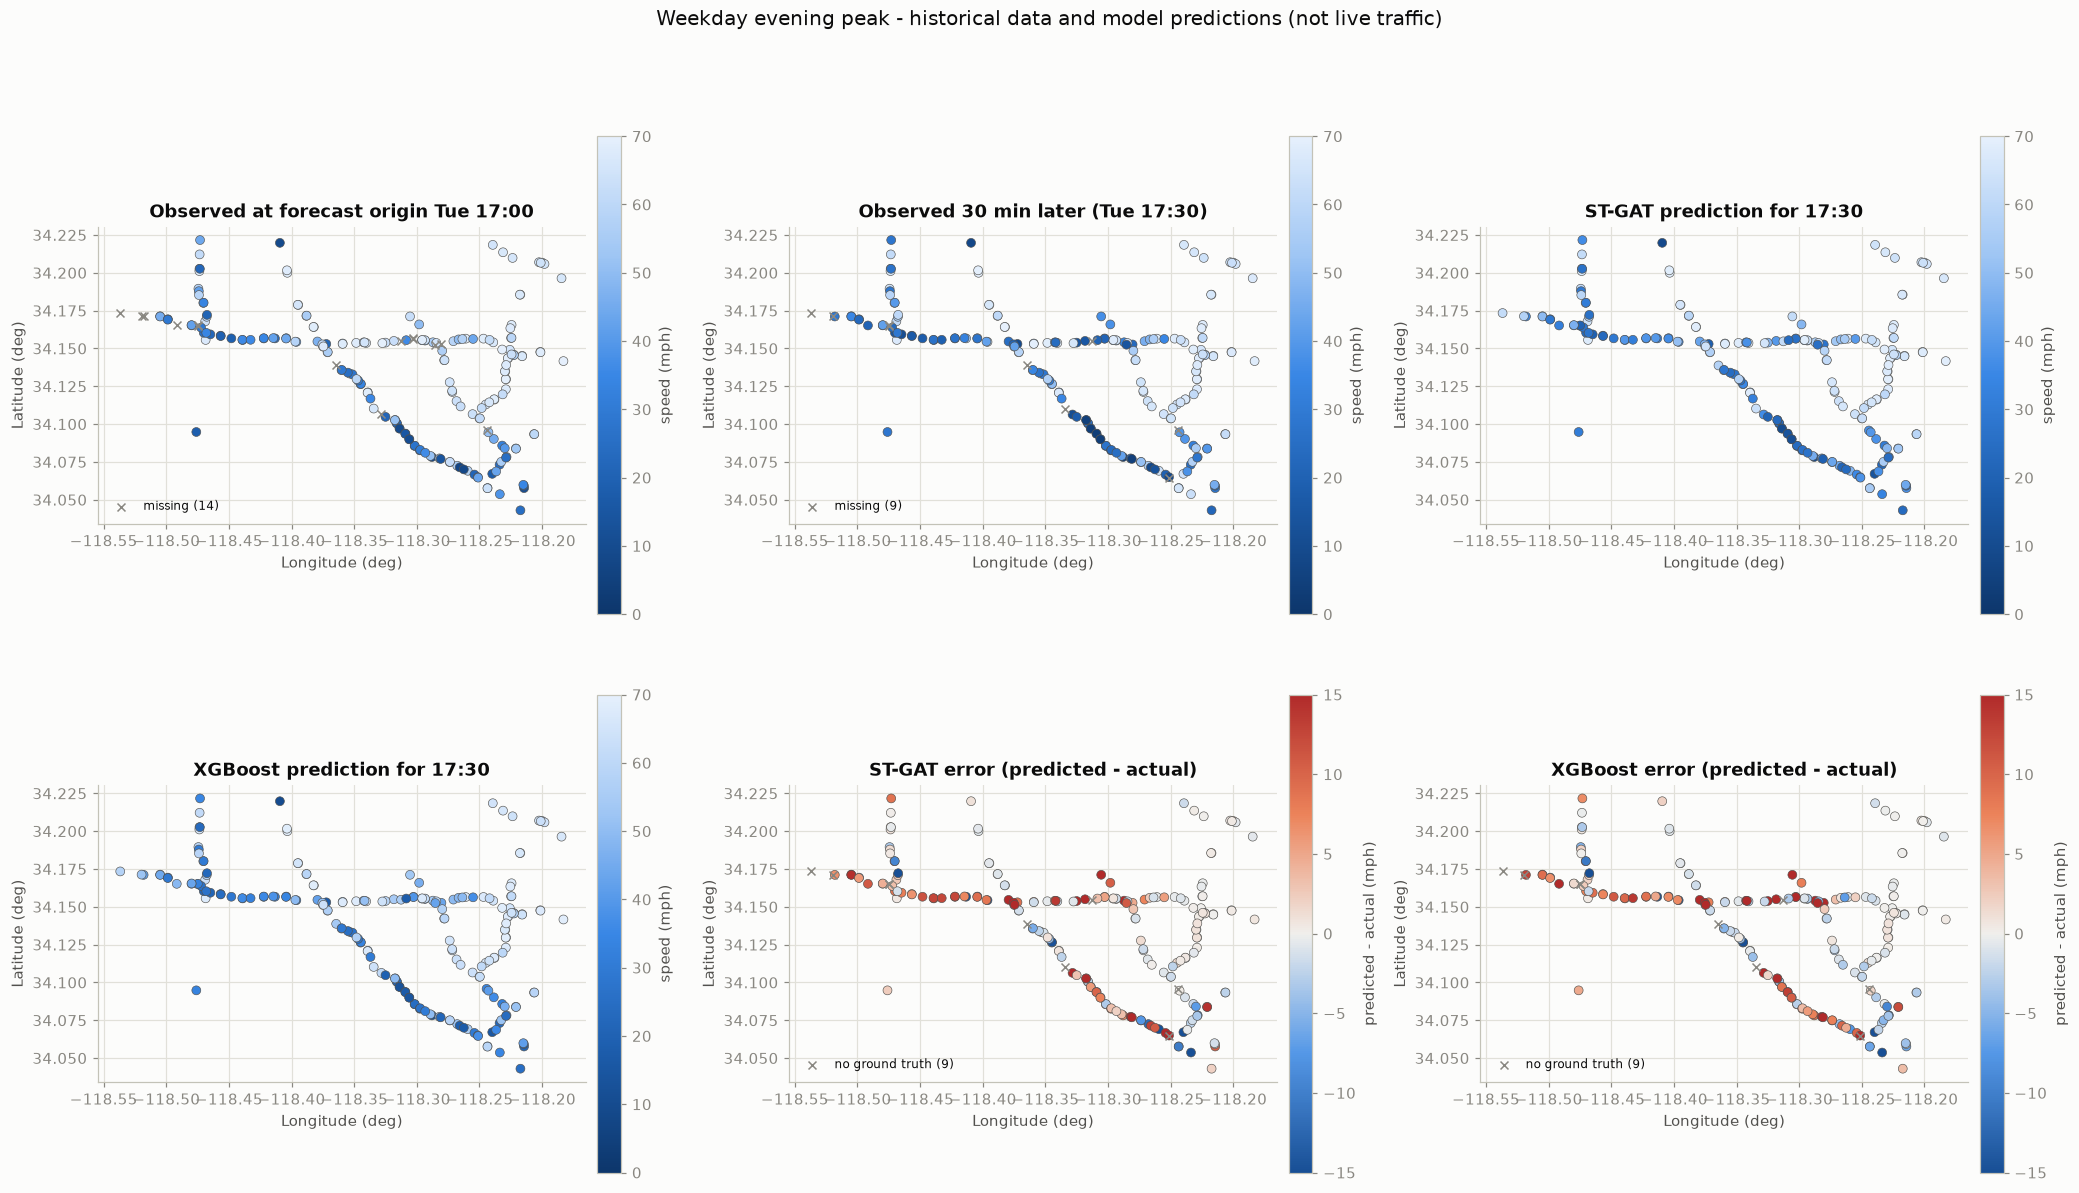

ST-GAT    : mean |error| over the 198 observed sensors = 5.87 mph
XGBoost   : mean |error| over the 198 observed sensors = 6.93 mph


In [4]:
def draw_case(c, title_prefix=""):
    fig, axes = plt.subplots(2, 3, figsize=(19, 11.5))
    now_ok = np.isfinite(c["observed_now"])
    viz.plot_speed_map(axes[0, 0], loc, c["observed_now"], f"Observed at forecast origin {c['origin_time']:%a %H:%M}", observed=now_ok)
    viz.plot_speed_map(axes[0, 1], loc, c["actual"], f"Observed {c['h'] * 5} min later ({c['target_time']:%a %H:%M})", observed=c["actual_observed"])
    viz.plot_speed_map(axes[0, 2], loc, c["pred"]["gat"], f"ST-GAT prediction for {c['target_time']:%H:%M}")
    viz.plot_speed_map(axes[1, 0], loc, c["pred"]["xgboost"], f"XGBoost prediction for {c['target_time']:%H:%M}")
    err = lambda m: np.where(c["actual_observed"], c["pred"][m] - c["actual"], np.nan)
    viz.plot_error_map(axes[1, 1], loc, err("gat"), "ST-GAT error (predicted - actual)")
    viz.plot_error_map(axes[1, 2], loc, err("xgboost"), "XGBoost error (predicted - actual)")
    fig.suptitle(f"{title_prefix} - historical data and model predictions (not live traffic)", fontsize=13, y=0.995)
    fig.tight_layout()
    return fig

name = "weekday evening peak"
c = case(CASES[name]); fig = draw_case(c, name.capitalize())
viz.save_figure(fig, "08_map_weekday_evening_peak"); plt.show()
for m in ("gat", "xgboost"):
    e = np.abs(c["pred"][m] - c["actual"])[c["actual_observed"]]
    print(f"{viz.style(m)['label']:10s}: mean |error| over the {int(c['actual_observed'].sum())} observed sensors = {e.mean():.2f} mph")

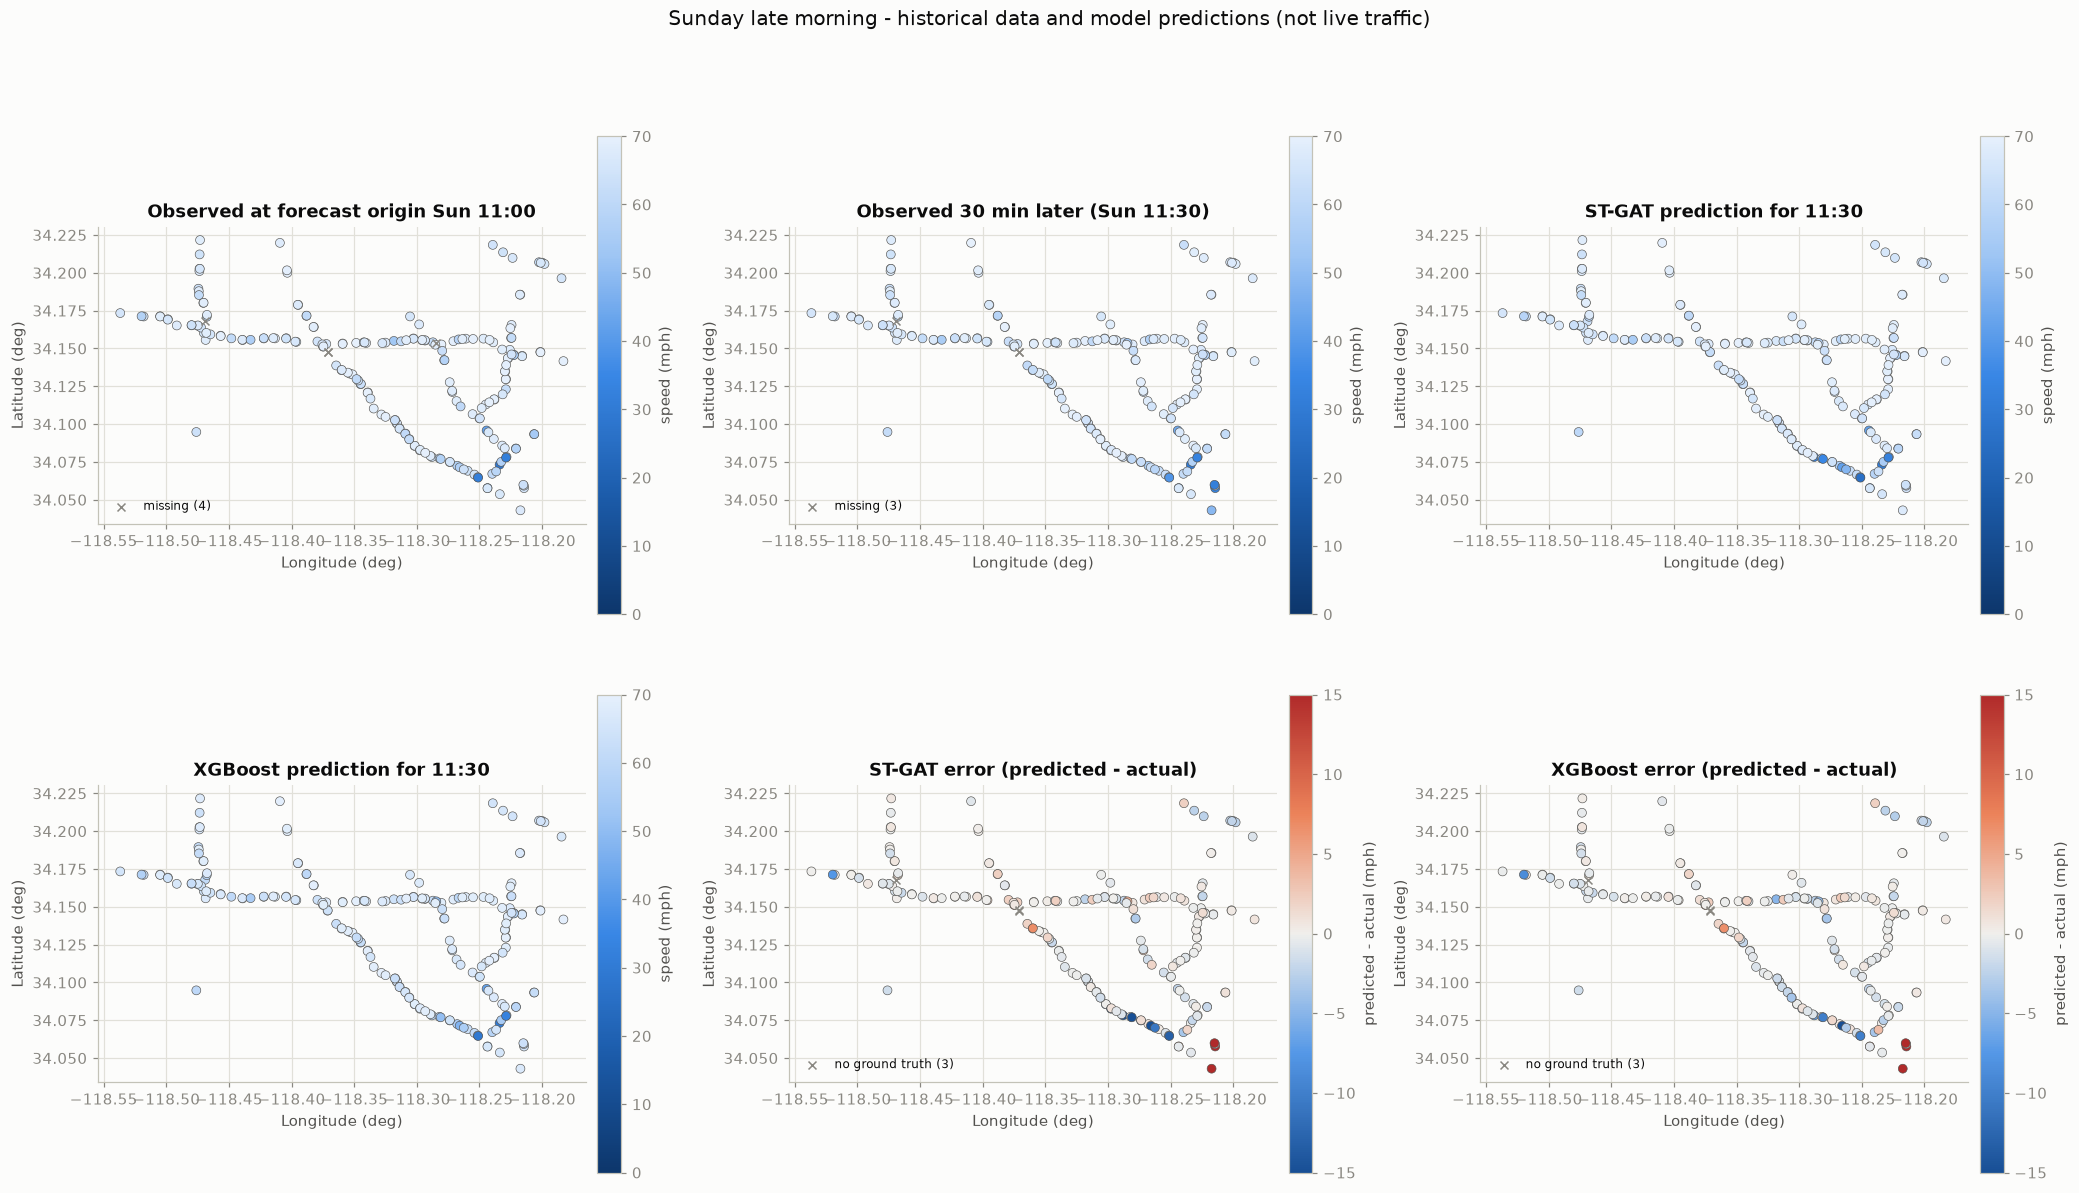

ST-GAT    : mean |error| over the 204 observed sensors = 2.10 mph
XGBoost   : mean |error| over the 204 observed sensors = 1.78 mph


In [5]:
name = "Sunday late morning"
c2 = case(CASES[name]); fig = draw_case(c2, name.capitalize())
viz.save_figure(fig, "08_map_sunday_late_morning"); plt.show()
for m in ("gat", "xgboost"):
    e = np.abs(c2["pred"][m] - c2["actual"])[c2["actual_observed"]]
    print(f"{viz.style(m)['label']:10s}: mean |error| over the {int(c2['actual_observed'].sum())} observed sensors = {e.mean():.2f} mph")

**Reading the maps.** The first two panels show how the observed pattern changes in 30 minutes; the third and fourth show what the models predicted for that
later time on the same colour scale; the bottom-right panels show where each model over- or under-estimated speed. These are two cases, not statistics: the
whole-period quantitative comparison is in notebook 07 and section 4 below.

## 3 · Which locations are predicted to be most congested?

In [6]:
def rank_table(c, model, top=10):
    pred = c["pred"][model]
    df = pd.DataFrame({"sensor_id": ctx.sensor_ids, "latitude": loc["latitude"].to_numpy(), "longitude": loc["longitude"].to_numpy(),
                       "predicted_mph": pred, "observed_mph": c["actual"], "observed_available": c["actual_observed"]})
    return df.sort_values("predicted_mph").head(top).reset_index(drop=True)

for m in ("gat", "xgboost"):
    print(f"--- {viz.style(m)['label']}: 10 lowest predicted speeds for {c['target_time']} (30 min ahead) ---")
    display(rank_table(c, m).round(2))

def overlap_at_k(c, model, k=10):
    obs = np.where(c["actual_observed"], c["actual"], np.inf)
    truly = set(np.argsort(obs)[:k][np.isfinite(np.sort(obs)[:k])])
    return len(truly & set(np.argsort(c["pred"][model])[:k])), len(truly)
for m in ("persistence", "xgboost", "gat"):
    hit, tot = overlap_at_k(c, m)
    print(f"{viz.style(m)['label']:12s}: {hit} of the {tot} truly slowest observed sensors are among its 10 predicted-slowest")

--- ST-GAT: 10 lowest predicted speeds for 2012-06-12 17:30:00 (30 min ahead) ---


,sensor_id,latitude,longitude,predicted_mph,observed_mph,observed_available
0,763995,34.22,-118.41,8.990000,8.00,True
1,717468,34.10,-118.31,9.790000,4.00,True
2,717472,34.10,-118.32,10.430000,4.12,True
3,716339,34.08,-118.29,10.760000,3.75,True
4,717461,34.09,-118.30,10.920000,4.25,True
5,717458,34.08,-118.30,11.200000,3.38,True
6,717462,34.09,-118.31,11.320000,3.62,True
7,718045,34.07,-118.24,13.700000,64.75,True
8,717466,34.09,-118.31,13.770000,3.75,True
9,769372,34.10,-118.32,16.190001,15.00,True


--- XGBoost: 10 lowest predicted speeds for 2012-06-12 17:30:00 (30 min ahead) ---


,sensor_id,latitude,longitude,predicted_mph,observed_mph,observed_available
0,763995,34.22,-118.41,10.04,8.00,True
1,716339,34.08,-118.29,12.57,3.75,True
2,717468,34.10,-118.31,12.85,4.00,True
3,717458,34.08,-118.30,12.88,3.38,True
4,717462,34.09,-118.31,14.28,3.62,True
5,717461,34.09,-118.30,14.53,4.25,True
6,718045,34.07,-118.24,15.09,64.75,True
7,769372,34.10,-118.32,16.42,15.00,True
8,717466,34.09,-118.31,16.99,3.75,True
9,716331,34.07,-118.26,17.49,12.88,True


Persistence : 6 of the 10 truly slowest observed sensors are among its 10 predicted-slowest
XGBoost     : 6 of the 10 truly slowest observed sensors are among its 10 predicted-slowest
ST-GAT      : 7 of the 10 truly slowest observed sensors are among its 10 predicted-slowest


## 4 · Congestion flagging over the whole test period

Retrospective check of how well *"predicted speed below a threshold"* identifies sensors that were actually slow. The threshold (**35 mph**, a commonly used
freeway congestion convention) was fixed before looking at any result and is the same for all models. This evaluates speed-threshold flags only; it does
not identify incidents.

precision                      recall                          F1  \
horizon_min        5      15     30     60     5      15     30     60     5    
model                                                                           
persistence     0.868  0.806  0.744  0.637  0.868  0.803  0.739  0.631  0.868   
xgboost         0.889  0.863  0.855  0.844  0.867  0.781  0.692  0.595  0.878   
gat             0.894  0.876  0.856  0.824  0.873  0.799  0.741  0.676  0.883   

                                  
horizon_min     15     30     60  
model                             
persistence  0.804  0.741  0.634  
xgboost      0.820  0.765  0.698  
gat          0.836  0.795  0.743

base rate (share of valid points that are truly below the threshold): {5: 0.102, 15: 0.102, 30: 0.102, 60: 0.102}


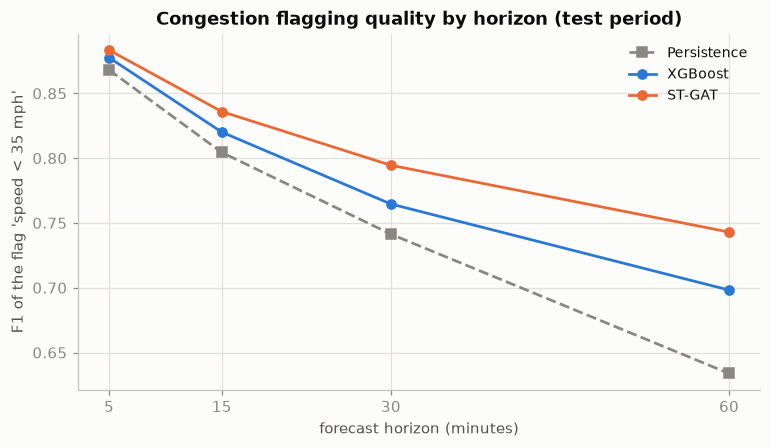

In [7]:
THRESHOLD = 35.0
all_pred = {m: ev.clip_predictions(preds[m]) for m in MODELS}
valid = ev.common_valid_mask(all_pred, ymask)
rows = []
for m in MODELS:
    for j, h in enumerate(HZ):
        v = valid[:, j]; actual_slow = (y[:, j] < THRESHOLD) & v; flagged = (all_pred[m][:, j] < THRESHOLD) & v
        tp = int((actual_slow & flagged).sum()); fp = int((~actual_slow & flagged & v).sum()); fn = int((actual_slow & ~flagged).sum())
        prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
        rows.append({"model": m, "horizon_min": h * 5, "precision": prec, "recall": rec, "F1": 2 * prec * rec / max(prec + rec, 1e-9),
                     "share of valid points actually < 35 mph": actual_slow.sum() / v.sum()})
flag = pd.DataFrame(rows)
flag.to_csv(config.METRICS_DIR / f"{config.tagged('congestion_flagging')}.csv", index=False)
display(flag.pivot(index="model", columns="horizon_min", values=["precision", "recall", "F1"]).reindex(MODELS).round(3))
print("base rate (share of valid points that are truly below the threshold):", flag.groupby("horizon_min")["share of valid points actually < 35 mph"].first().round(3).to_dict())

fig, ax = plt.subplots(figsize=(8, 4.2))
for m in MODELS:
    d = flag[flag.model == m]; st = viz.style(m)
    ax.plot(d["horizon_min"], d["F1"], color=st["color"], marker=st["marker"], ls=st["ls"], label=st["label"])
ax.set_xlabel("forecast horizon (minutes)"); ax.set_ylabel("F1 of the flag 'speed < 35 mph'"); ax.set_xticks([h * 5 for h in HZ])
ax.set_title("Congestion flagging quality by horizon (test period)"); ax.legend()
viz.save_figure(fig, "08_congestion_flag_f1"); plt.show()

In [8]:
# Ranking quality: how many of the 10 truly slowest observed sensors does each model place among its 10 predicted-slowest?
K = 10; rows = []
for j, h in enumerate(HZ):
    obs_rank = np.where(ymask[:, j], y[:, j], np.inf)                                # [S, N]
    enough = (ymask[:, j].sum(1) >= 2 * K)
    truly = np.argpartition(obs_rank, K, axis=1)[:, :K]
    for m in MODELS:
        top_pred = np.argpartition(all_pred[m][:, j], K, axis=1)[:, :K]
        hits = np.array([len(set(a) & set(b)) for a, b in zip(truly[enough], top_pred[enough])])
        rows.append({"model": m, "horizon_min": h * 5, "mean overlap (of 10)": hits.mean(), "origins used": int(enough.sum())})
display(pd.DataFrame(rows).pivot(index="model", columns="horizon_min", values="mean overlap (of 10)").reindex(MODELS).round(2))

horizon_min,5,15,30,60
model,,,,
persistence,6.81,6.19,5.56,4.73
xgboost,7.22,6.69,6.21,5.68
gat,7.26,6.79,6.36,5.95


**Reading the tables.** Precision is the share of flagged sensors that really were below 35 mph, recall the share of truly slow sensors that were flagged.
The overlap table asks the ranking question directly. Both are retrospective, per-sensor speed statements; a low-speed sensor is not evidence of a specific incident.

## 5 · Where are the errors? (per-sensor maps, test period)

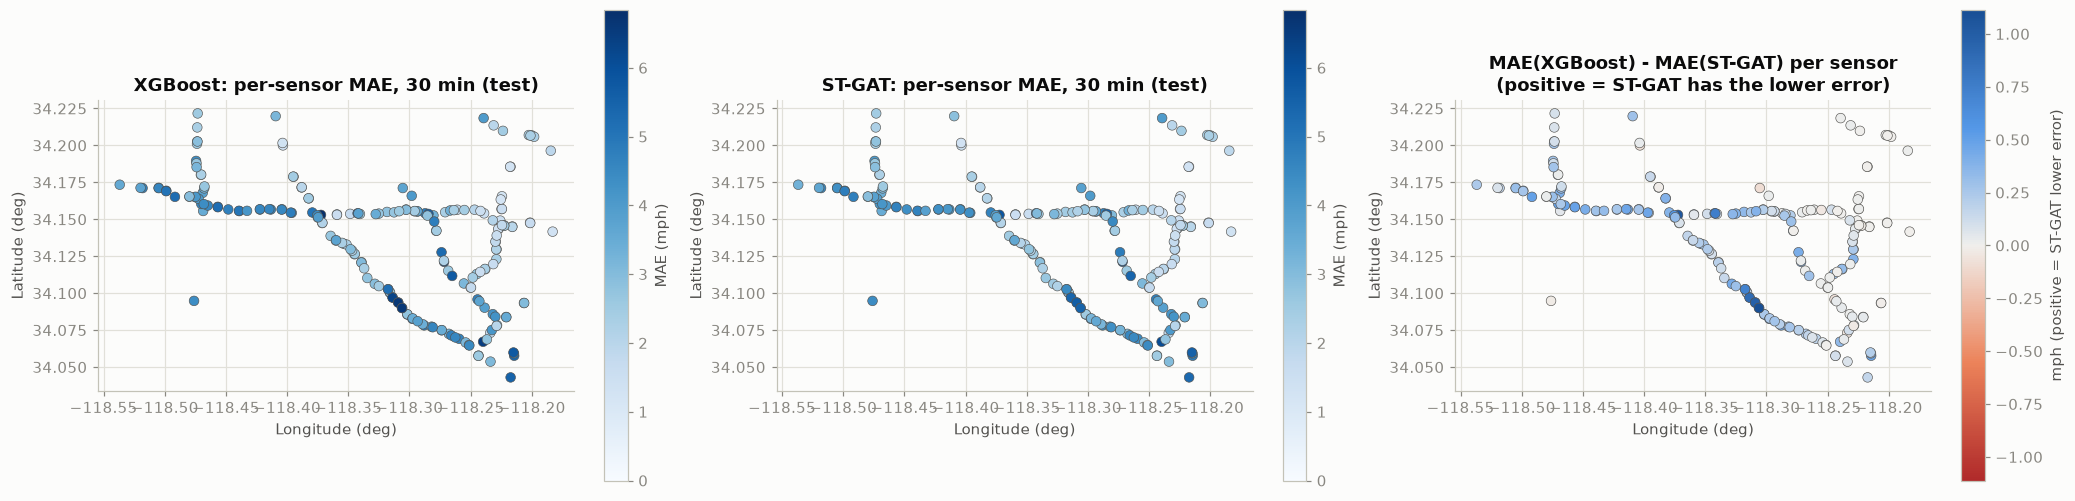

sensors where ST-GAT has the lower MAE at 30 min: 181 of 207; median difference 0.149 mph


In [9]:
j = HZ.index(H_DEFAULT)
per = {m: ev.per_sensor_metrics(all_pred[m], y, valid, HZ, ctx.sensor_ids) for m in ("xgboost", "gat")}
mae = {m: per[m][per[m].horizon_steps == H_DEFAULT].set_index("node")["MAE"].to_numpy() for m in per}
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
vmax = float(max(mae["xgboost"].max(), mae["gat"].max()))
for ax, m in zip(axes[:2], ("xgboost", "gat")):
    lon, lat = loc["longitude"].to_numpy(), loc["latitude"].to_numpy()
    sc = ax.scatter(lon, lat, c=mae[m], cmap="Blues", vmin=0, vmax=vmax, s=40, edgecolor=viz.INK_2, linewidth=0.4)
    ax.set_title(f"{viz.style(m)['label']}: per-sensor MAE, {H_DEFAULT * 5} min (test)"); ax.set_aspect(1 / np.cos(np.deg2rad(lat.mean())))
    ax.set_xlabel("Longitude (deg)"); ax.set_ylabel("Latitude (deg)"); plt.colorbar(sc, ax=ax, shrink=0.75, label="MAE (mph)")
diff = mae["xgboost"] - mae["gat"]                                       # positive = ST-GAT has the lower error at that sensor
lim = float(np.nanmax(np.abs(diff)))
sc = axes[2].scatter(lon, lat, c=diff, cmap=viz.ERROR_CMAP.reversed(), vmin=-lim, vmax=lim, s=40, edgecolor=viz.INK_2, linewidth=0.4)
axes[2].set_title("MAE(XGBoost) - MAE(ST-GAT) per sensor\n(positive = ST-GAT has the lower error)")
axes[2].set_aspect(1 / np.cos(np.deg2rad(lat.mean()))); axes[2].set_xlabel("Longitude (deg)"); axes[2].set_ylabel("Latitude (deg)")
plt.colorbar(sc, ax=axes[2], shrink=0.75, label="mph (positive = ST-GAT lower error)")
fig.tight_layout(); viz.save_figure(fig, "08_error_maps"); plt.show()
print(f"sensors where ST-GAT has the lower MAE at {H_DEFAULT * 5} min: {int((diff > 0).sum())} of {N}; median difference {np.median(diff):.3f} mph")

## 6 · Interactive map (time slider)

Three linked maps for the weekday of case 1: **observed** speed at the target time, the **XGBoost** prediction and the **ST-GAT** prediction, with a slider over forecast
origins (every 30 minutes) and the horizon fixed per figure. Grey markers are missing observations. The figure is also saved as a standalone HTML file
(`artifacts/figures/08_interactive_forecast_map_*.html`; base-map tiles need an internet connection when the HTML is opened).

In [10]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from matplotlib.colors import to_hex

colorscale = [[p, to_hex(viz.SPEED_CMAP(p))] for p in np.linspace(0, 1, 8)]

def interactive_map(horizon_steps, day="2012-06-12", every_minutes=30):
    d0 = pd.Timestamp(day)
    ks = [k for k in range(len(origins)) if d0 <= ctx.timestamps[origins[k]] < d0 + pd.Timedelta(days=1) and ctx.timestamps[origins[k]].minute % every_minutes == 0]
    if not ks:
        print("no forecast origins on that day (smoke mode keeps only a subset)"); return None
    j = horizons.index(horizon_steps)
    lon, lat = loc["longitude"].to_numpy(), loc["latitude"].to_numpy()
    def frame_traces(k):
        o = int(origins[k]); tgt = ctx.speed[o + horizon_steps]; ok = ctx.mask[o + horizon_steps]
        text = lambda v: [f"sensor {s}<br>{x:.1f} mph" for s, x in zip(ctx.sensor_ids, v)]
        mk = lambda c: dict(color=c, colorscale=colorscale, cmin=0, cmax=70, size=9, showscale=False)
        return [
            go.Scattermap(lon=lon[ok], lat=lat[ok], mode="markers", marker=mk(tgt[ok]), text=np.array(text(tgt))[ok], hoverinfo="text", name="observed"),
            go.Scattermap(lon=lon[~ok], lat=lat[~ok], mode="markers", marker=dict(color=viz.MISSING_COLOR, size=9), text=["missing observation"] * int((~ok).sum()), hoverinfo="text", name="missing"),
            go.Scattermap(lon=lon, lat=lat, mode="markers", marker=mk(ev.clip_predictions(preds["xgboost"][k, j])), text=text(ev.clip_predictions(preds["xgboost"][k, j])), hoverinfo="text", name="XGBoost"),
            go.Scattermap(lon=lon, lat=lat, mode="markers", marker=mk(ev.clip_predictions(preds["gat"][k, j])), text=text(ev.clip_predictions(preds["gat"][k, j])), hoverinfo="text", name="ST-GAT"),
        ]
    fig = make_subplots(rows=1, cols=3, specs=[[{"type": "map"}] * 3], subplot_titles=("Observed (historical)", "XGBoost forecast", "ST-GAT forecast"), horizontal_spacing=0.01)
    first = frame_traces(ks[0])
    for tr, col in zip(first, (1, 1, 2, 3)):
        fig.add_trace(tr, row=1, col=col)
    fig.frames = [go.Frame(data=frame_traces(k), traces=[0, 1, 2, 3], name=str(i)) for i, k in enumerate(ks)]
    centre = dict(lat=float(lat.mean()), lon=float(lon.mean()))
    fig.update_layout(map=dict(style="carto-positron", center=centre, zoom=9.2), map2=dict(style="carto-positron", center=centre, zoom=9.2), map3=dict(style="carto-positron", center=centre, zoom=9.2),
                      margin=dict(l=5, r=5, t=60, b=5), height=520, showlegend=False,
                      title=f"{horizon_steps * 5}-minute-ahead forecasts vs observed speed - historical data, not live traffic (colour: 0 mph dark -> 70 mph pale; grey = missing)",
                      sliders=[dict(active=0, pad=dict(t=10), currentvalue=dict(prefix="forecast origin: "),
                                    steps=[dict(method="animate", label=f"{ctx.timestamps[origins[k]]:%H:%M}", args=[[str(i)], dict(mode="immediate", frame=dict(duration=0, redraw=True), transition=dict(duration=0))]) for i, k in enumerate(ks)])])
    return fig

for hs in (3, 6):
    figi = interactive_map(hs)
    if figi is not None:
        path = config.FIGURES_DIR / f"{config.tagged('08_interactive_forecast_map')}_h{hs}.html"
        figi.write_html(path, include_plotlyjs="cdn")
        print("saved", path.relative_to(config.PROJECT_ROOT))
        if hs == 6:
            figi.show()

saved artifacts/figures/08_interactive_forecast_map_h3.html
saved artifacts/figures/08_interactive_forecast_map_h6.html


**Reading the interactive map.** Drag the slider to move through the day: the left map shows what was observed at the target time, the other two what each model forecast for
that time from data available 15 or 30 minutes earlier. Hover over a marker for the sensor id and speed. As everywhere in this notebook the maps describe sensor speeds only
and say nothing about specific incidents.

## 7 · Summary

In [11]:
print("figures written:", sorted(p.name for p in config.FIGURES_DIR.glob(f"{config.tagged('08_')}*")))
print("metrics written:", sorted(p.name for p in config.METRICS_DIR.glob(f"{config.tagged('congestion_flagging')}*")))
print("\nNext: 09_optional_sumo_simulation.ipynb (optional) - and review reports/results_summary.md")

figures written: ['08_congestion_flag_f1.png', '08_error_maps.png', '08_interactive_forecast_map_h3.html', '08_interactive_forecast_map_h6.html', '08_map_sunday_late_morning.png', '08_map_weekday_evening_peak.png']
metrics written: ['congestion_flagging.csv']

Next: 09_optional_sumo_simulation.ipynb (optional) - and review reports/results_summary.md


---
---
# Section: `09_optional_sumo_simulation`

# 09 · Optional: simulated traffic-signal control with SUMO

> **Scope and honesty statement.**
> * This is a **simulation only**. Nothing in this project connects to real traffic signals, detectors or live traffic feeds.
> * METR-LA alone does **not** contain an intersection, signal plans, turning movements, queues or vehicle counts, so its sensor graph cannot be used directly as a SUMO signal network.
>   We therefore use a small synthetic intersection and illustrate *how* forecasts could inform a policy.
> * **If SUMO is not installed, no simulation results are produced.** The notebook then validates everything that can be validated without SUMO (network and demand files, policy safety logic)
>   and clearly reports the experiment as **not executed**. No numbers are ever filled in by hand.

**Objective.** Compare two **fixed-time** signal plans (a naive one and one tuned to the demand with Webster's method) with a **queue-aware** policy on one simulated intersection under identical, seeded demand, using waiting time,
queue length, throughput and travel time.

**Methodology.**
1. Check whether SUMO, `netconvert` and TraCI are available.
2. Generate the network files and seeded Poisson demand; validate them.
3. Implement both policies on a state machine that enforces signal safety (min/max green, yellow, all-red, no conflicting greens) and test it.
4. *If SUMO is available:* run both policies over several seeds and compare. *Otherwise:* report the experiment as not executed.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import shutil, os, importlib.util, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from src import visualization as viz, evaluation as ev
viz.apply_style()

SIM = config.PROJECT_ROOT / "simulation"
sys.path.insert(0, str(SIM))
import signal_policies as sp
import run_sumo_experiment as rs

## 1 · Is SUMO available?

In [3]:
from importlib import metadata
status = {
    "`sumo` executable": "found" if rs.sumo_binary("sumo") else None,
    "`netconvert` executable": "found" if rs.sumo_binary("netconvert") else None,
    "python package `traci`": "installed" if importlib.util.find_spec("traci") else None,
    "SUMO version (pip `eclipse-sumo`)": metadata.version("eclipse-sumo") if importlib.util.find_spec("sumo") else None,
}
display(pd.DataFrame({"component": list(status), "found": [v if v else "NOT FOUND" for v in status.values()]}))
SUMO_AVAILABLE = all(status[k] for k in ("`sumo` executable", "`netconvert` executable", "python package `traci`"))
print("SUMO usable for the experiment:", SUMO_AVAILABLE)
if not SUMO_AVAILABLE:
    print("-> The simulation sections below will be reported as NOT EXECUTED. See simulation/README.md for installation instructions.")

,component,found
0,`sumo` executable,found
1,`netconvert` executable,found
2,python package `traci`,installed
3,SUMO version (pip `eclipse-sumo`),1.28.0


SUMO usable for the experiment: True


## 2 · Network and demand (generated and validated without SUMO)

A 4-way intersection with one lane per approach (250 m arms, 50 km/h) and **straight-through movements only**, so that two phases (north-south, east-west)
never conflict inside a phase. Demand is seeded Poisson arrivals: the first half-hour is heavier on north-south (500 veh/h per approach vs 200), the second half reversed,
so a pre-timed plan cannot be optimal for both halves.

In [4]:
files = rs.write_network_files()
for p in files:
    root = ET.parse(p).getroot()                                       # raises if the XML is not well formed
    print(f"{p.relative_to(config.PROJECT_ROOT)}: <{root.tag}> with {len(root)} elements")
nodes = ET.parse(rs.CFG / "intersection.nod.xml").getroot()
assert sum(n.get("type") == "traffic_light" for n in nodes) == 1
edges = {e.get("id") for e in ET.parse(rs.CFG / "intersection.edg.xml").getroot()}
assert edges == {f"{a}2C" for a in "NSEW"} | {f"C2{a}" for a in "NSEW"}
cons = [(c.get("from"), c.get("to")) for c in ET.parse(rs.CFG / "intersection.con.xml").getroot()]
assert all(f in edges and t in edges for f, t in cons) and len(cons) == 4
print("network files are well formed and internally consistent (edges referenced by every connection exist)")

simulation/sumo_config/intersection.nod.xml: <nodes> with 5 elements
simulation/sumo_config/intersection.edg.xml: <edges> with 8 elements
simulation/sumo_config/intersection.con.xml: <connections> with 4 elements
network files are well formed and internally consistent (edges referenced by every connection exist)


In [5]:
# Demand check: generated arrivals versus the intended Poisson means
rows = []
for seed in range(5):
    path, counts = rs.generate_routes(seed, 3600)
    rows.append({"seed": seed, **{f"{a}": n for a, n in counts.items()}})
gen = pd.DataFrame(rows).set_index("seed")
expected = {a: sum(rate[a] * (end - start) / 3600 for start, end, rate in rs.demand_profile(3600)) for a in "NSEW"}
print("expected vehicles per approach over 3600 s:", {k: round(v) for k, v in expected.items()})
display(gen)
for a in "NSEW":      # every count within 4 standard deviations of the Poisson mean
    assert abs(gen[a].mean() - expected[a]) < 4 * np.sqrt(expected[a] / len(gen)) + 1, a
print("generated demand matches the intended arrival rates; each seed uses its own random stream:", len({tuple(r) for r in gen.values}) == len(gen))
route_file = rs.OUT / "routes_seed0.rou.xml"
departs = [float(v.get("depart")) for v in ET.parse(route_file).getroot().findall("vehicle")]
assert departs == sorted(departs) and max(departs) < 3600

expected vehicles per approach over 3600 s: {'N': 350, 'S': 350, 'E': 350, 'W': 350}


,N,S,E,W
seed,,,,
0,346,356,332,348
1,345,334,347,354
2,349,330,357,345
3,323,373,352,366
4,343,307,355,353


generated demand matches the intended arrival rates; each seed uses its own random stream: True


## 3 · Signal policies and their safety logic

* **Fixed-time (naive):** 30 s north-south / 30 s east-west, regardless of traffic.
* **Fixed-time, tuned (Webster):** a time-of-day pretimed plan: for each half hour of the demand profile, cycle length and green split from Webster's formula
  (critical flows of each phase, saturation flow assumed 1,800 veh/h/lane, lost time = yellow + all-red per phase), clipped to the same min/max green. This is the fair
  pretimed baseline: it is designed from the known (historical) demand pattern, exactly how fixed plans are set in practice.
* **Queue-aware:** a green ends when the current approach group has no queue while the other has one (gap-out), or when the other queue exceeds the current one by more than a margin.
  An optional `forecast` hook lets a demand forecast add expected arrivals to the pressure (not used in the baseline experiment).
* **Safety, for both:** the controller (not the policy) enforces minimum green 10 s, maximum green 60 s, yellow 3 s, all-red 2 s and never shows green/yellow to both phases at once.
  The check below runs both policies on scripted and random queue sequences and verifies every constraint on the resulting signal traces.

*The plot shows policy logic on scripted queue counts. It is a unit demonstration, not a performance result.*

all safety constraints hold on 200 random + 1 scripted trace per policy (no conflicting greens, min/max green, yellow, all-red)


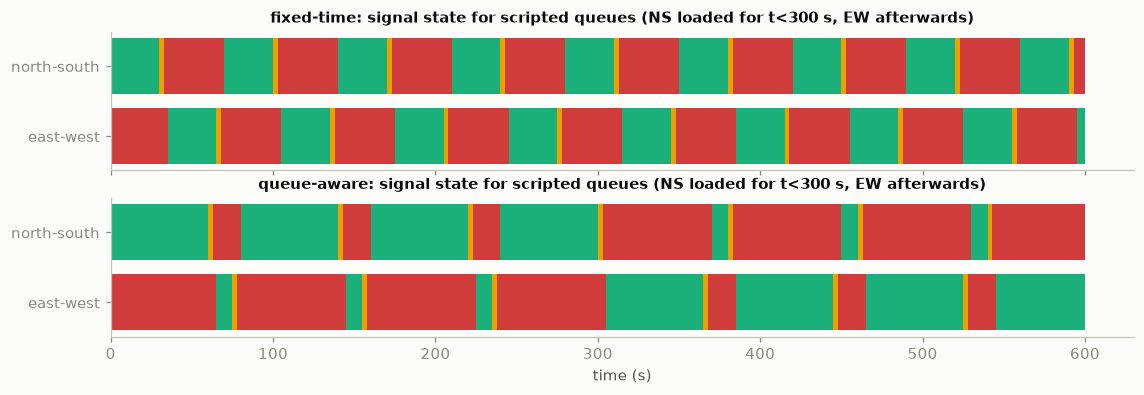

In [6]:
timings = sp.Timings()
scripted = lambda t: {sp.NS: 12 if t < 300 else 1, sp.EW: 1 if t < 300 else 12}      # NS loaded first, EW loaded later
traces = {"fixed-time": sp.run_trace(sp.FixedTimePolicy(30, 30), scripted, 600, timings),
          "queue-aware": sp.run_trace(sp.QueueAwarePolicy(margin=2), scripted, 600, timings)}
rng = np.random.default_rng(0)
for name, policy_factory in (("fixed-time", lambda: sp.FixedTimePolicy(30, 30)), ("queue-aware", lambda: sp.QueueAwarePolicy())):
    for _ in range(200):                                                              # random queue sequences
        q = {t: {sp.NS: int(rng.integers(0, 30)), sp.EW: int(rng.integers(0, 30))} for t in range(1200)}
        sp.check_trace_is_safe(sp.run_trace(policy_factory(), lambda t: q[t], 1200, timings), timings)
    sp.check_trace_is_safe(traces[name], timings)
print("all safety constraints hold on 200 random + 1 scripted trace per policy (no conflicting greens, min/max green, yellow, all-red)")

fig, axes = plt.subplots(2, 1, figsize=(12, 3.6), sharex=True)
colour = {"G": "#1baf7a", "y": "#eda100", "r": "#d03b3b"}
for ax, (name, tr) in zip(axes, traces.items()):
    for k, (phase, y0) in enumerate(((sp.NS, 1), (sp.EW, 0))):
        for t, s in enumerate(tr):
            ax.barh(y0, 1, left=t, color=colour[s[phase]], height=0.8, linewidth=0)
    ax.set_yticks([0, 1], ["east-west", "north-south"]); ax.set_title(f"{name}: signal state for scripted queues (NS loaded for t<300 s, EW afterwards)", fontsize=10); ax.grid(False)
axes[-1].set_xlabel("time (s)")
viz.save_figure(fig, "09_policy_logic_demo"); plt.show()

**Reading the demonstration.** The fixed-time plan alternates 30 s / 30 s whatever the queues are. The queue-aware controller holds the minimum green, keeps serving the loaded approach
until the other queue clearly dominates, and always passes through yellow and all-red before the other phase turns green. Whether this *improves* anything must be measured in the simulator.

## 4 · Simulation experiment

Runs only when SUMO, `netconvert` and TraCI are installed; otherwise it is skipped and **no results are shown**.
Settings: 3,600 s of simulated time, **20 seeds**, all three policies on identical demand per seed (same route file, same SUMO seed).
Every simulation step asserts that SUMO displays exactly the signal state chosen by our controller.

In [7]:
SEEDS = range(20)
results = None
if SUMO_AVAILABLE:
    rs.convert_network()
    rows = [rs.run_episode(policy, seed) for seed in SEEDS for policy in rs.POLICIES]
    results = pd.DataFrame(rows)
    results.to_csv(config.METRICS_DIR / "sumo_signal_control_results.csv", index=False)
    print("simulation finished:", len(results), "episodes")
else:
    print("NOT EXECUTED: SUMO is not installed in this environment, so there are no simulation results.")

simulation finished: 60 episodes


Webster time-of-day plan (end of period s, green NS s, green EW s): [(1800, 16, 10), (3600, 10, 16)]


mean_waiting_time_s       mean_travel_time_s        \
                             mean   std               mean   std   
policy                                                             
fixed                       11.72  0.38              58.04  0.50   
fixed_webster                7.15  0.26              53.62  0.44   
queue_aware                  8.26  0.45              55.95  0.77   

              mean_queue_vehicles       max_queue_vehicles        \
                             mean   std               mean   std   
policy                                                             
fixed                        4.54  0.18              19.70  1.42   
fixed_webster                2.77  0.14              14.35  2.43   
queue_aware                  3.20  0.22              16.90  1.68   

              completed_trips         
                         mean    std  
policy                                
fixed                 1377.35  31.16  
fixed_webster         1375.30  30.77  
queue_aware           1376.40  31.45

paired over 20 seeds (identical demand per seed); negative difference = queue-aware has the lower value


mean reference  \
comparison                  metric                                
queue_aware - fixed         mean_waiting_time_s          11.723   
                            mean_travel_time_s           58.041   
                            mean_queue_vehicles           4.539   
                            max_queue_vehicles           19.700   
                            completed_trips            1377.350   
queue_aware - fixed_webster mean_waiting_time_s           7.148   
                            mean_travel_time_s           53.624   
                            mean_queue_vehicles           2.772   
                            max_queue_vehicles           14.350   
                            completed_trips            1375.300   

                                                 mean queue-aware  \
comparison                  metric                                  
queue_aware - fixed         mean_waiting_time_s             8.260   
                            mean_travel_time_s             55.950   
                            mean_queue_vehicles             3.201   
                            max_queue_vehicles             16.900   
                            completed_trips              1376.400   
queue_aware - fixed_webster mean_waiting_time_s             8.260   
                            mean_travel_time_s             55.950   
                            mean_queue_vehicles             3.201   
                            max_queue_vehicles             16.900   
                            completed_trips              1376.400   

                                                 mean difference  95% CI low  \
comparison                  metric                                             
queue_aware - fixed         mean_waiting_time_s           -3.463      -3.709   
                            mean_travel_time_s            -2.091      -2.458   
                            mean_queue_vehicles           -1.338      -1.431   
                            max_queue_vehicles            -2.800      -3.942   
                            completed_trips               -0.950      -2.678   
queue_aware - fixed_webster mean_waiting_time_s            1.112       0.890   
                            mean_travel_time_s             2.326       1.973   
                            mean_queue_vehicles            0.429       0.341   
                            max_queue_vehicles             2.550       1.222   
                            completed_trips                1.100      -0.348   

                                                 95% CI high  \
comparison                  metric                             
queue_aware - fixed         mean_waiting_time_s       -3.217   
                            mean_travel_time_s        -1.724   
                            mean_queue_vehicles       -1.245   
                            max_queue_vehicles        -1.658   
                            completed_trips            0.778   
queue_aware - fixed_webster mean_waiting_time_s        1.334   
                            mean_travel_time_s         2.679   
                            mean_queue_vehicles        0.517   
                            max_queue_vehicles         3.878   
                            completed_trips            2.548   

                                                 relative change %  \
comparison                  metric                                   
queue_aware - fixed         mean_waiting_time_s            -29.540   
                            mean_travel_time_s              -3.603   
                            mean_queue_vehicles            -29.475   
                            max_queue_vehicles             -14.213   
                            completed_trips                 -0.069   
queue_aware - fixed_webster mean_waiting_time_s             15.560   
                            mean_travel_time_s               4.337   
                            mean_queue_vehicles        

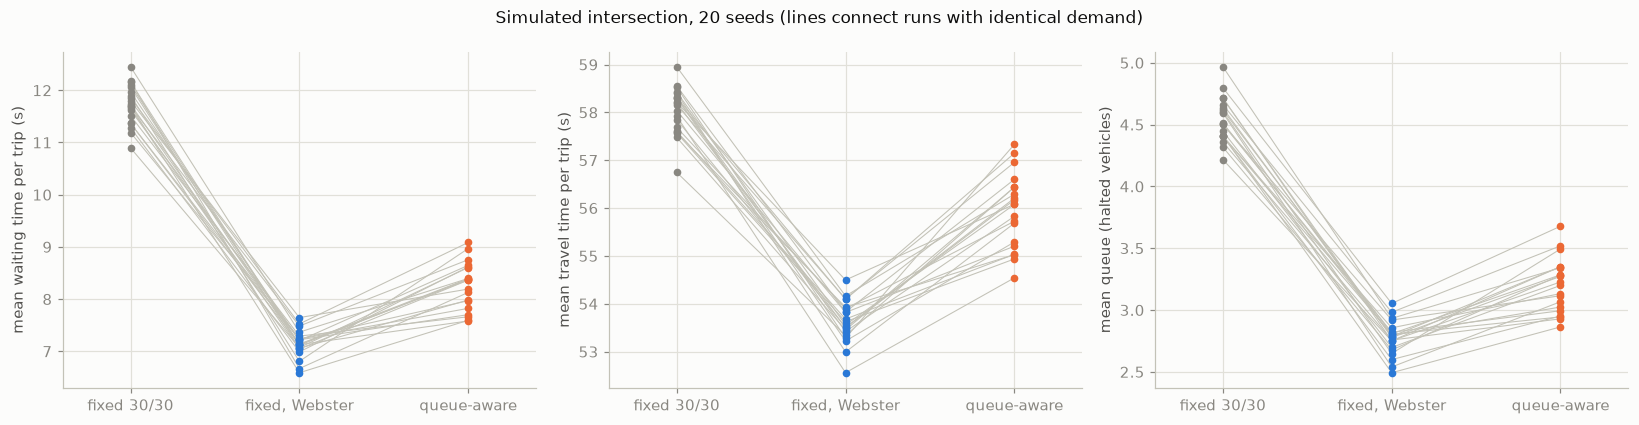

In [8]:
from scipy import stats as st
paired_stats = None
if results is not None:
    print("Webster time-of-day plan (end of period s, green NS s, green EW s):", rs.webster_schedule())
    metrics_cols = ["mean_waiting_time_s", "mean_travel_time_s", "mean_queue_vehicles", "max_queue_vehicles", "completed_trips"]
    display(results.groupby("policy")[metrics_cols].agg(["mean", "std"]).round(2))
    wide = results.pivot(index="seed", columns="policy")
    rows = []
    for ref in ("fixed", "fixed_webster"):
        for m in metrics_cols:
            d = wide[(m, "queue_aware")] - wide[(m, ref)]                    # paired by seed: same demand
            lo, hi = st.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=d.std(ddof=1) / np.sqrt(len(d)))
            rows.append({"comparison": f"queue_aware - {ref}", "metric": m, "mean reference": wide[(m, ref)].mean(), "mean queue-aware": wide[(m, "queue_aware")].mean(),
                         "mean difference": d.mean(), "95% CI low": lo, "95% CI high": hi, "relative change %": 100 * d.mean() / wide[(m, ref)].mean(),
                         "seeds where queue-aware is lower": int((d < 0).sum())})
    paired_stats = pd.DataFrame(rows).set_index(["comparison", "metric"])
    print(f"paired over {len(wide)} seeds (identical demand per seed); negative difference = queue-aware has the lower value")
    display(paired_stats.round(3))
    paired_stats.to_csv(config.METRICS_DIR / "sumo_signal_control_paired.csv")

    names = {"fixed": "fixed 30/30", "fixed_webster": "fixed, Webster", "queue_aware": "queue-aware"}
    colors = {"fixed": "#898781", "fixed_webster": "#2a78d6", "queue_aware": "#eb6834"}
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
    for ax, (m, label) in zip(axes, (("mean_waiting_time_s", "mean waiting time per trip (s)"), ("mean_travel_time_s", "mean travel time per trip (s)"), ("mean_queue_vehicles", "mean queue (halted vehicles)"))):
        pols = list(rs.POLICIES)
        for seed in wide.index:
            ax.plot(range(len(pols)), [wide.loc[seed, (m, p)] for p in pols], color="#c3c2b7", lw=0.7)
        for k, p in enumerate(pols):
            ax.scatter(np.full(len(wide), k), wide[(m, p)], color=colors[p], s=16, zorder=3)
        ax.set_xticks(range(len(pols)), [names[p] for p in pols]); ax.set_xlim(-0.4, len(pols) - 0.6); ax.set_ylabel(label)
    fig.suptitle("Simulated intersection, 20 seeds (lines connect runs with identical demand)", fontsize=11)
    fig.tight_layout(); viz.save_figure(fig, "09_sumo_policy_comparison"); plt.show()
else:
    print("Results table: none (experiment not executed).")

### Interpretation (checked against the results above)

In [9]:
if paired_stats is not None:
    naive, tuned = paired_stats.loc["queue_aware - fixed"], paired_stats.loc["queue_aware - fixed_webster"]
    n_seeds = len(SEEDS)
    display(ev.report_claims({
        "vs naive 30/30: queue-aware lowers mean waiting time (95% CI below 0) in every seed": bool(naive.loc["mean_waiting_time_s", "95% CI high"] < 0 and naive.loc["mean_waiting_time_s", "seeds where queue-aware is lower"] == n_seeds),
        "vs naive 30/30: queue-aware lowers travel time and mean queue (95% CIs below 0)": bool(naive.loc["mean_travel_time_s", "95% CI high"] < 0 and naive.loc["mean_queue_vehicles", "95% CI high"] < 0),
        "vs tuned Webster plan: queue-aware has HIGHER mean waiting time (95% CI above 0) in every seed": bool(tuned.loc["mean_waiting_time_s", "95% CI low"] > 0 and tuned.loc["mean_waiting_time_s", "seeds where queue-aware is lower"] == 0),
        "vs tuned Webster plan: queue-aware has higher travel time and mean queue (95% CIs above 0)": bool(tuned.loc["mean_travel_time_s", "95% CI low"] > 0 and tuned.loc["mean_queue_vehicles", "95% CI low"] > 0),
        "throughput shows no detectable difference in either comparison (95% CIs contain 0)": bool(all(t.loc["completed_trips", "95% CI low"] <= 0 <= t.loc["completed_trips", "95% CI high"] for t in (naive, tuned))),
    }))
else:
    print("no simulation results: nothing to interpret")

,claim,holds in this run
0,vs naive 30/30: queue-aware lowers mean waitin...,True
1,vs naive 30/30: queue-aware lowers travel time...,True
2,vs tuned Webster plan: queue-aware has HIGHER ...,True
3,vs tuned Webster plan: queue-aware has higher ...,True
4,throughput shows no detectable difference in e...,True


**What the simulation shows (for this synthetic scenario only).**

* Against the **naive 30 s / 30 s plan**, the queue-aware controller cuts waiting time and queues substantially, in every seed.
* Against a **properly tuned pretimed plan** (Webster, one plan per half hour designed from the known demand), the picture **reverses**: the tuned fixed plan has lower waiting time,
  travel time and queues than our queue-aware controller in every seed. Most of the apparent benefit of "adaptive" control in the first comparison came from a badly chosen baseline.
* Why: demand stays well below capacity, where Webster's short cycle (about 36 s, printed above) is efficient, while our simple rule keeps at least 10 s of green and only switches
  when the other queue is clearly longer, which produces longer cycles and more waiting. A real actuated controller (gap-out on detector headways, tuned extension times) would likely do better;
  we did not implement one.
* **Throughput** does not differ detectably in either comparison: every vehicle is eventually served below capacity; the policies differ in delay, not in capacity.
* **Scope.** One isolated synthetic intersection with straight-through traffic only, saturation flow assumed (1,800 veh/h/lane) for the Webster plan, perfect queue detection for the
  adaptive rule, and **no use of the METR-LA forecasts**. These numbers say nothing about real Los Angeles corridors, and nothing here controls real traffic signals.

## 5 · Status, limitations and plan

| Item | Status |
|---|---|
| Network, demand and policy logic | implemented; files validated; safety logic unit-tested (`tests/test_signal_policies.py`) |
| SUMO simulation and metric comparison | implemented in `simulation/run_sumo_experiment.py`; runs whenever SUMO is available (the delivered run: SUMO 1.28 via `pip install eclipse-sumo traci`, 20 seeds x 3 policies, every step checks that SUMO shows the controller's signal state) |
| Link to the METR-LA forecasts | **not implemented**: METR-LA has no intersection data; the `QueueAwarePolicy.forecast` hook is the integration point |

**Limitations.** One synthetic isolated intersection, straight-through movements only, two phases, synthetic Poisson demand, no pedestrians or turning conflicts,
no driver heterogeneity beyond the default car-following model; results would say nothing about real corridors or about the METR-LA network.

**Plan to extend.** See `simulation/README.md`: implement a proper actuated controller (gap-out on detector headways), vary demand towards capacity, then feed a short-term demand forecast into the policy hook.